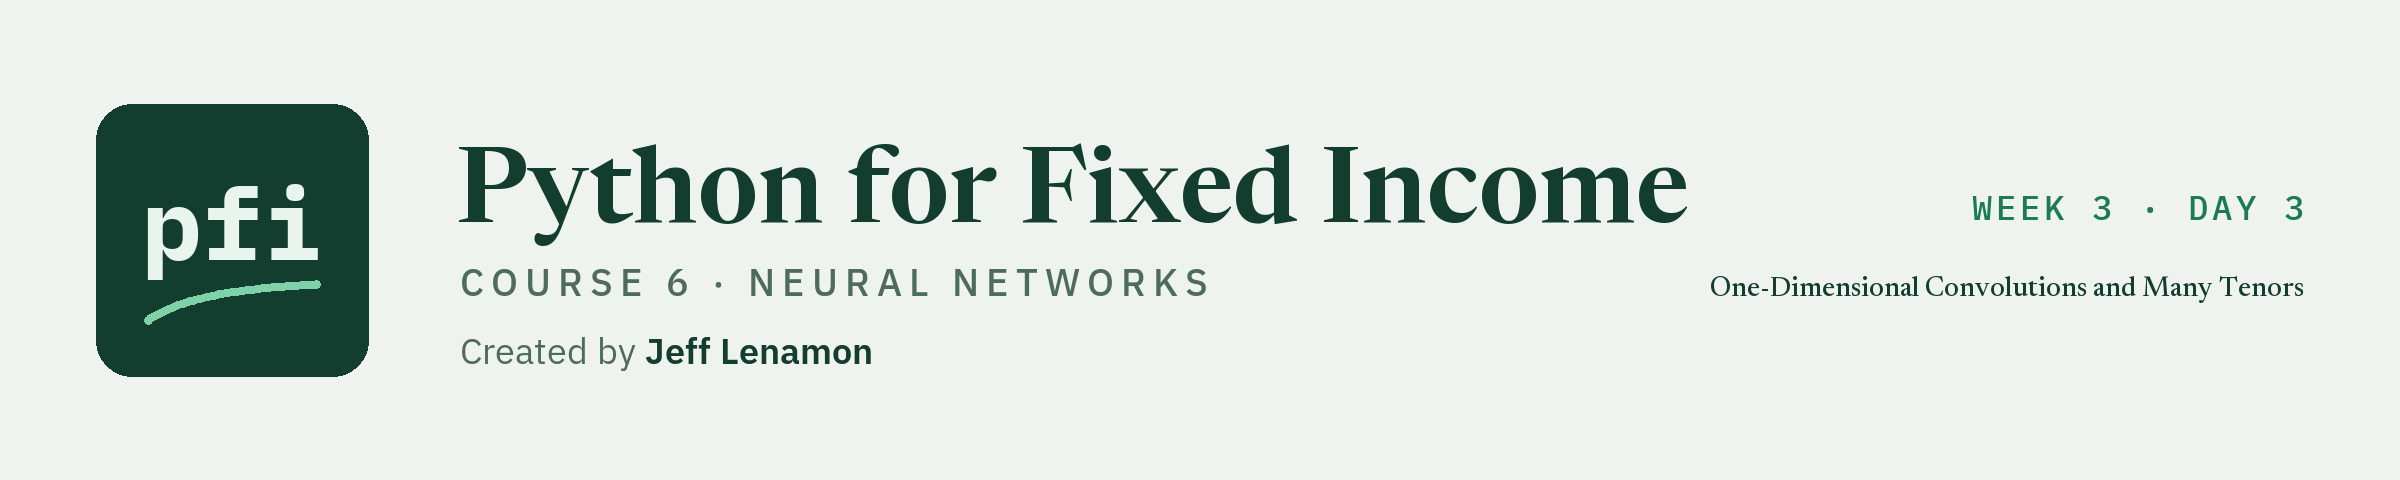

# One-Dimensional Convolutions and Many Tenors

Week 3, Day 3. A convolution slides one small set of weights along the window, day by day. Today: filters by hand and in Excel, pooling, a Conv1D scored walk-forward, all 11 tenors as channels, and every sequence model so far in one table.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course06_neural_networks/week3/day3/13_one_dimensional_convolutions_and_many_tenors.ipynb)

Day 11 laid the window flat and gave every one of its 20 days its own weight. Day 12 read the window one day at a time with a recurrent layer, carrying a state forward. A **one-dimensional convolution** does a third thing: it takes a short run of days, say 5, multiplies them by 5 weights, adds them up, and slides the same 5 weights one day along to do it again. A set of weights that slides like this is a **filter**, and a filter is a weighted moving sum: Excel's `SUMPRODUCT` over five rows, filled down.

The second idea today is **channels**. So far the window held one series, the 10 Yr's changes. The file holds the whole curve: a window can carry all 11 full tenors side by side, one channel each, and a filter then weighs a block of 5 days by 11 tenors at once.

**The sequence model, framed.** The task is stated in the past tense: the change in the 10 Yr yield on a date, in bp, from the changes on the 20 trading days before that date. Every fitted value is for a date inside the file, from a model fitted only on earlier dates, and nothing is fitted for, or reported at, any date after 2026-10-02. The comparison is the simplest rule there is: the last value carried forward, which for changes is a change of zero. A walk-forward error on past dates describes how a rule would have scored on those dates; it is not evidence about any later date, and it is not a view on rates.

Today you will:

1. Build a filter by hand (`conv1d_by_hand`), check it against Keras's `Conv1D`, and see that five weights of 0.2 are a 5-day moving average.
2. Read a filter as a weighted moving sum, on one tenor and on 11.
3. Pool a filter's outputs into one number per filter.
4. Rebuild days 11 and 12's networks on the same five folds, then score a Conv1D walk-forward on the 10 Yr changes.
5. Give three networks all 11 tenors as channels.
6. Keep same-day changes out of every window (`assert_windows_past_only`).
7. Put every sequence model so far in one table, and write down the candidates for day 14.

Q. Set up today's work folder: TensorFlow's settings, the thread settings, the seed, and the Treasury file.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course06_neural_networks/requirements.txt
NEEDED = {
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "keras": "keras==3.15.1",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "tensorflow": "tensorflow==2.21.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

17 packages checked, all present


In [2]:
# today's setup: the TensorFlow and thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# TensorFlow writes start-up notices to stderr: these three lines must run before TensorFlow is imported
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These lines must run before numpy, pandas, scikit-learn, TensorFlow, or LightGBM is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("sklearn", "scikit-learn"), ("statsmodels", "statsmodels"), ("scipy", "scipy"), ("tensorflow", "tensorflow"), ("keras", "keras"), ("lightgbm", "lightgbm"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd
import tensorflow as tf
import keras

# one thread for TensorFlow too, set before TensorFlow runs anything
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
# TensorFlow's own Python notices are turned down to errors; on Windows the one it writes is that it has no GPU
# support there (day 1 explains it)
tf.get_logger().setLevel("ERROR")
# where TensorFlow has a deterministic version of an operation, use it
tf.config.experimental.enable_op_determinism()

# the versions the saved outputs of this notebook came from (course06_neural_networks/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scikit-learn": "1.9.1", "scipy": "1.18.1", "tensorflow": "2.21.0", "keras": "3.15.1", "lightgbm": "4.7.0", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42
# Keras's seed sets Python's, numpy's, and TensorFlow's random generators at once
keras.utils.set_random_seed(SEED)

# the kinds of device TensorFlow can use on this machine
devices = sorted({device.device_type for device in tf.config.list_physical_devices()})
print(f"Devices TensorFlow can use: {', '.join(devices)}")

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "credit_card_default.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course6_13_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["treasury_par_yields.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scikit-learn 1.9.1, scipy 1.18.1, tensorflow 2.21.0, keras 3.15.1, lightgbm 4.7.0, matplotlib 3.11.2, pytest 9.1.1
Devices TensorFlow can use: CPU
Work folder: pfi_course6_13_dyv5qk7m, in your temp folder
Data files from the data folder of the course repo: treasury_par_yields.csv
SEED = 42


Q. Write `mlkit.py`, Course 4's complete module, and `ensemblekit.py`, Course 5's complete module, both unchanged. `netkit` imports them.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


In [4]:
%%writefile ensemblekit.py
"""ensemblekit: the pieces of ensembles, tuning, and rare-event modelling that the libraries leave to the analyst,
written down and tested.

Written day by day in Python for Fixed Income, Course 5: Advanced Machine Learning. It imports mlkit (Course 4's
module) and never changes it.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- The positive class is 1 (default, bankrupt). A row is flagged when its model output is at least the threshold.
- Course 5 never scores a row that Course 4 used as a test row. The course4_*_rows functions rebuild Course 4's
  splits exactly and return only the rows Course 5 may use; the closed rows are never returned.
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart.
- Every library call that can use more than one thread is given n_jobs=1, so every run gives the same digits.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from sklearn.model_selection import train_test_split  # Course 4's split, rebuilt

import mlkit  # Course 4's module: thresholds, metrics, splitters, and the no-leak check

# the card file: its outcome column and the 19 model columns (the four person columns are never features)
CARD_TARGET = "default payment next month"
CARD_FEATURES = ["LIMIT_BAL", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"] + \
    [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]


def course4_card_rows(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    """Course 4's 60/20/20 split of the card file, rebuilt, without its test rows.

    Input: frame, the 30,000 accounts of credit_card_default.csv as read by pd.read_csv.
    Output: X_train (18,000 rows), X_valid (6,000 rows), y_train, y_valid, with the 19 model columns in
    CARD_FEATURES and the file's row labels. Course 4's 6,000 test rows are never returned.
    Convention: the same two calls as Course 4: train_test_split(test_size=0.2, stratify=y, random_state=42), then
    the remaining 80 percent split with test_size=0.25, stratified, same seed. The validation rows were used in
    Course 4 to choose a threshold and a pruning level, never to fit.
    Raises ValueError if a column is missing or the frame does not have 30,000 rows.
    """
    # check the frame is the whole card file
    missing = [name for name in CARD_FEATURES + [CARD_TARGET] if name not in frame.columns]
    if missing:
        raise ValueError(f"frame lacks the columns {missing}")
    if len(frame) != 30_000:
        raise ValueError(f"frame must hold the 30,000 card accounts, not {len(frame)}")
    X, y = frame[CARD_FEATURES], frame[CARD_TARGET]
    # Course 4's first cut puts 20 percent aside as test rows: they are dropped here, never returned
    X_rest, _, y_rest, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    # Course 4's second cut: a quarter of the rest (20 percent of the file) as validation rows
    X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest,
                                                          random_state=42)
    mlkit.assert_disjoint(X_train.index, X_valid.index)
    return X_train, X_valid, y_train, y_valid


def bootstrap_positions(n_rows: int, seed: int = 42) -> np.ndarray:
    """Draw n_rows row positions with replacement: one bootstrap sample.

    Input: n_rows, how many rows the data has (at least 1); seed, the random seed.
    Output: an array of n_rows positions from 0 to n_rows - 1, in the order drawn. A position can appear more than
    once, and some positions do not appear at all (about 36.8 percent of them for large n_rows).
    Convention: np.random.default_rng(seed).integers(0, n_rows, n_rows), so the same seed gives the same sample.
    Excel: =RANDBETWEEN(1,n) draws one position but takes no seed and changes at every recalculation.
    Raises ValueError if n_rows is below 1.
    """
    if n_rows < 1:
        raise ValueError(f"n_rows must be at least 1, not {n_rows}")
    # one generator per call, seeded, so the draw does not depend on anything drawn before
    rng = np.random.default_rng(seed)
    return rng.integers(0, n_rows, n_rows)


def out_of_bag(n_rows: int, drawn: np.ndarray) -> np.ndarray:
    """The positions a bootstrap sample never drew: its out-of-bag rows.

    Inputs: n_rows, how many rows the data has; drawn, the positions of a bootstrap sample.
    Output: the sorted positions from 0 to n_rows - 1 that are not in drawn.
    Convention: a model fitted on the drawn rows has never seen these rows, so they can score it.
    Raises ValueError if drawn is empty or holds a position outside 0 to n_rows - 1.
    """
    positions = np.asarray(drawn)
    if positions.size == 0:
        raise ValueError("drawn is empty")
    if positions.min() < 0 or positions.max() > n_rows - 1:
        raise ValueError(f"drawn holds a position outside 0 to {n_rows - 1}")
    # every position, minus the ones drawn at least once
    return np.setdiff1d(np.arange(n_rows), positions)


from sklearn.metrics import roc_auc_score  # ranking quality from probabilities


def bagged_proba(bagging, X: pd.DataFrame) -> np.ndarray:
    """Bagging by hand: the average of each fitted tree's class-1 probability, each on its own columns.

    Inputs: bagging, a fitted BaggingClassifier; X, the rows to score, with the columns it was fitted on.
    Output: one number per row, the mean over bagging.estimators_ of each tree's class-1 probability on the
    columns listed in bagging.estimators_features_. It equals bagging.predict_proba(X)[:, 1] within 1e-12.
    Convention: a tree whose bootstrap sample held only one class gives 0 for class 1 when that class is 0.
    Excel: with each tree's column of outputs pasted side by side, =AVERAGE(B2:K2) filled down.
    Raises ValueError if bagging is not fitted.
    """
    if not hasattr(bagging, "estimators_"):
        raise ValueError("bagging is not fitted: call fit first")
    # the trees were fitted on plain arrays of the chosen columns, so score them the same way
    values = np.asarray(X, dtype=float)
    total = np.zeros(len(values))
    for tree, columns in zip(bagging.estimators_, bagging.estimators_features_):
        proba = tree.predict_proba(values[:, columns])
        # the tree's classes are positions in bagging.classes_; class 1 is position 1
        position = np.flatnonzero(tree.classes_ == 1)
        total += proba[:, position[0]] if position.size else 0.0
    return total / len(bagging.estimators_)


def oob_auc(model, y_train) -> float:
    """ROC AUC of the out-of-bag probabilities of a bagged model or a random forest.

    Inputs: model, fitted with oob_score=True on the training rows; y_train, those rows' outcomes, in order.
    Output: roc_auc_score(y_train, model.oob_decision_function_[:, 1]): each row scored only by the trees that
    did not draw it.
    Convention: model.oob_score_ is the accuracy of the out-of-bag votes for a classifier, not ROC AUC; this
    function gives the ranking number the course compares models by.
    Raises ValueError if the model was fitted without oob_score=True, or if a row has no out-of-bag vote (too few
    trees, so some row was drawn by every tree).
    """
    if not hasattr(model, "oob_decision_function_"):
        raise ValueError("the model has no out-of-bag outputs: fit it with oob_score=True")
    proba = model.oob_decision_function_[:, 1]
    if np.isnan(proba).any():
        raise ValueError(f"{int(np.isnan(proba).sum())} rows have no out-of-bag vote: use more trees")
    return float(roc_auc_score(y_train, proba))


def tree_correlation(forest, X: pd.DataFrame) -> float:
    """How much the trees of an ensemble agree: the mean pairwise correlation of their class-1 outputs.

    Inputs: forest, a fitted random forest, extra-trees, or bagging model (anything with estimators_, and
    estimators_features_ for bagging); X, the rows to score (validation rows).
    Output: the mean of the upper triangle of np.corrcoef over the trees' class-1 probabilities on X: 1 means
    every tree gives the same ranking, 0 means no linear agreement.
    Convention: averaging trees removes less noise the more they agree; a random forest tries a random subset of
    columns at each split to lower this number.
    Excel: =CORREL(B2:B6001,C2:C6001) for one pair of pasted tree columns.
    Raises ValueError if the ensemble has fewer than two trees.
    """
    trees = list(forest.estimators_)
    if len(trees) < 2:
        raise ValueError(f"need at least two trees, the ensemble has {len(trees)}")
    # each tree was fitted on a plain array; bagging may give each tree its own columns
    values = np.asarray(X, dtype=float)
    columns = getattr(forest, "estimators_features_", [slice(None)] * len(trees))
    outputs = np.array([tree.predict_proba(values[:, cols])[:, -1] for tree, cols in zip(trees, columns)])
    # the correlation of every pair of trees, then the mean above the diagonal
    matrix = np.corrcoef(outputs)
    return float(matrix[np.triu_indices(len(trees), k=1)].mean())


from sklearn.inspection import permutation_importance  # the drop in a score when one column is shuffled


def importance_table(model, X_valid: pd.DataFrame, y_valid, scoring: str = "roc_auc", n_repeats: int = 5,
                     seed: int = 42) -> pd.DataFrame:
    """Two importance measures side by side: impurity importance and permutation importance.

    Inputs: model, a fitted tree ensemble with feature_importances_, fitted on a DataFrame; X_valid, y_valid,
    rows the model was NOT fitted on (validation rows); scoring, the score whose drop is measured; n_repeats, how
    many shuffles per column; seed, the random seed of the shuffles.
    Output: a DataFrame indexed by feature with columns impurity (model.feature_importances_, from the training
    rows, sums to 1), permutation (the mean drop in the score over n_repeats shuffles of that column),
    permutation_sd (their standard deviation), impurity_rank and permutation_rank (1 = largest), sorted by
    permutation, largest first.
    Convention: impurity importance is learned on the training rows and rewards columns the trees could split on
    to fit noise; permutation importance on unseen rows measures how much the score leans on a column there.
    Neither measure is a cause. permutation_importance runs with n_jobs=1.
    Raises ValueError if the model has no feature_importances_ (an unfitted model, or a linear model).
    """
    if not hasattr(model, "feature_importances_"):
        raise ValueError("the model has no feature_importances_: fit a tree ensemble first")
    # shuffle each column n_repeats times on the rows given and record the drop in the score
    result = permutation_importance(model, X_valid, y_valid, scoring=scoring, n_repeats=n_repeats,
                                    random_state=seed, n_jobs=1)
    table = pd.DataFrame({"impurity": model.feature_importances_, "permutation": result.importances_mean,
                          "permutation_sd": result.importances_std}, index=pd.Index(X_valid.columns, name="feature"))
    # rank 1 is the largest value; ties share the better rank
    table["impurity_rank"] = table["impurity"].rank(ascending=False, method="min").astype(int)
    table["permutation_rank"] = table["permutation"].rank(ascending=False, method="min").astype(int)
    return table.sort_values("permutation", ascending=False, kind="stable")


from sklearn.model_selection import cross_val_predict  # out-of-fold outputs, one per row


def course4_bench_rows(bench: pd.DataFrame, ratings: pd.DataFrame) -> pd.DataFrame:
    """Course 4's 615 training bonds of the synthetic benchmark, without its 206 test bonds.

    Inputs: bench, the 821 bonds of benchmark.csv; ratings, ratings.csv (rating and score).
    Output: the 615 training bonds with every column of bench plus score (the rating's number, 1 = AAA),
    log_oas (natural log of oas in bp), years (days from as_of_date to maturity / 365.25), and amount_bn
    (amount_outstanding in billions), with bench's row labels. Course 4's 206 test bonds are never returned.
    Convention: Course 4's split, train_test_split(test_size=0.25, random_state=42) on the joined rows. The bonds
    and their spreads are invented by the course's generator.
    Raises ValueError if bench does not hold 821 bonds.
    """
    if len(bench) != 821:
        raise ValueError(f"bench must hold the 821 benchmark bonds, not {len(bench)}")
    # the rating's number, joined row for row (each rating appears once in ratings)
    frame = bench.merge(ratings[["rating", "score"]], on="rating", how="left", validate="many_to_one")
    frame["log_oas"] = np.log(frame["oas"])
    dates = pd.to_datetime(frame["maturity"]) - pd.to_datetime(frame["as_of_date"])
    frame["years"] = dates.dt.days / 365.25
    frame["amount_bn"] = frame["amount_outstanding"] / 1e9
    # Course 4's split: the second part was its test set, dropped here
    train, _ = train_test_split(frame, test_size=0.25, random_state=42)
    return train


def oof_threshold(model, X, y, target_recall: float = 0.70, cv=None) -> tuple[float, np.ndarray]:
    """The course's threshold rule, applied to out-of-fold probabilities on the training rows.

    Inputs: model, an unfitted (or fitted) classifier with predict_proba; X, y, the training rows; target_recall,
    the share of defaults to catch; cv, a splitter (default mlkit.cv_folds(), stratified 5-fold, seed 42).
    Output: (threshold, proba): proba holds each training row's class-1 probability from the fold model that did
    not see it (cross_val_predict, n_jobs=1); threshold is mlkit.threshold_for_recall(y, proba, target_recall),
    the highest threshold whose out-of-fold recall is at least target_recall.
    Convention: the threshold is chosen on training rows only, so validation and test rows stay for reporting.
    cross_val_predict fits clones, so the caller's model is left as it was.
    Raises ValueError from mlkit.threshold_for_recall on a bad target or no row of class 1.
    """
    folds = cv if cv is not None else mlkit.cv_folds()
    proba = cross_val_predict(model, X, y, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
    return mlkit.threshold_for_recall(y, proba, target_recall), proba


def samme_alpha(weighted_error: float, learning_rate: float = 1.0) -> float:
    """The weight AdaBoost gives one stump's vote, for two classes.

    Inputs: weighted_error, the stump's error with each row counted by its weight (above 0, below 0.5);
    learning_rate, the shrinkage AdaBoostClassifier applies (default 1.0).
    Output: learning_rate * ln((1 - e) / e), in natural logs. A stump right on 80 percent of the weight gets
    ln(4) = 1.3863; one barely better than a coin gets almost 0.
    Convention: the SAMME weight with two classes (its extra term ln(classes - 1) is ln 1 = 0); it equals
    AdaBoostClassifier's estimator_weights_.
    Excel: =LN((1-e)/e).
    Raises ValueError unless 0 < weighted_error < 0.5.
    """
    if not 0 < weighted_error < 0.5:
        raise ValueError(f"weighted_error must be above 0 and below 0.5, not {weighted_error}")
    return float(learning_rate * np.log((1 - weighted_error) / weighted_error))


def reweight(weights: np.ndarray, missed: np.ndarray, alpha: float) -> np.ndarray:
    """AdaBoost's new row weights after one round: the rows the stump missed count for more.

    Inputs: weights, the current row weights (non-negative); missed, 1 where the stump was wrong and 0 where it
    was right, the same length; alpha, the stump's weight (samme_alpha).
    Output: weights * exp(alpha * missed), divided by their sum so the new weights sum to 1.
    Excel: =w*EXP(alpha*miss) filled down, then each divided by the column's SUM.
    Raises ValueError if the lengths differ, the input is empty, or a weight is negative.
    """
    w = np.asarray(weights, dtype=float)
    m = np.asarray(missed, dtype=float)
    if w.size == 0 or w.shape != m.shape:
        raise ValueError(f"weights and missed must be non-empty and the same length, not {w.size} and {m.size}")
    if (w < 0).any():
        raise ValueError("weights must not be negative")
    # a missed row is multiplied by e^alpha, a correct row by 1
    new = w * np.exp(alpha * m)
    return new / new.sum()


from sklearn.tree import DecisionTreeRegressor  # one round's tree, fitted to the residuals


def boost_by_hand(X, y, n_rounds: int, learning_rate: float, max_depth: int, seed: int = 42) -> np.ndarray:
    """Gradient boosting for a squared error, by hand: start from the mean, then fit trees to the residuals.

    Inputs: X, the feature rows; y, the target (for example log_oas); n_rounds, how many trees; learning_rate,
    the fraction of each tree's output added; max_depth, each tree's depth; seed, each tree's random_state.
    Output: the fitted values on X after n_rounds: F0 = mean(y), then for each round
    F = F + learning_rate * tree.predict(X), with the tree fitted to the residuals y - F.
    Convention: equals GradientBoostingRegressor(n_estimators=n_rounds, learning_rate=..., max_depth=...,
    random_state=seed).predict(X) on the rows it was fitted on, within 1e-12. No criterion= is passed (scikit-learn
    1.9 deprecates "friedman_mse" for a regression tree).
    Excel: one round is =y-F, the two leaf means by AVERAGEIFS on either side of the stump's threshold, and
    =F+lr*IF(x<=t,left,right).
    Raises ValueError if n_rounds is below 1 or learning_rate is not positive.
    """
    if n_rounds < 1 or learning_rate <= 0:
        raise ValueError(f"n_rounds must be at least 1 and learning_rate positive, not {n_rounds}, {learning_rate}")
    target = np.asarray(y, dtype=float)
    # round 0: every row's fitted value is the mean
    fitted = np.full(target.size, target.mean())
    for _ in range(n_rounds):
        # fit a small tree to what is still unexplained, then add a fraction of it
        tree = DecisionTreeRegressor(max_depth=max_depth, random_state=seed).fit(X, target - fitted)
        fitted = fitted + learning_rate * tree.predict(X)
    return fitted


def mae_bp(log_true, log_fitted) -> float:
    """Mean absolute error in bp of a model fitted on log spreads.

    Inputs: log_true and log_fitted, natural logs of spreads in bp, the same length.
    Output: mean(|exp(log_true) - exp(log_fitted)|), in bp.
    Convention: the course's benchmark metric; exp of a fitted log is a median-type value, not a mean.
    Excel: =AVERAGE(ABS(EXP(a)-EXP(b))).
    Raises ValueError if the inputs are empty or of different lengths.
    """
    true, fitted = np.asarray(log_true, dtype=float), np.asarray(log_fitted, dtype=float)
    if true.size == 0 or true.shape != fitted.shape:
        raise ValueError(f"inputs must be non-empty and the same length, not {true.size} and {fitted.size}")
    return float(np.mean(np.abs(np.exp(true) - np.exp(fitted))))


def early_stopping_rows(X_train, y_train, fraction: float = 0.2, seed: int = 42) -> tuple:
    """Carve stopping rows out of the training rows, for early stopping, so no report row chooses the trees.

    Inputs: X_train, y_train, the training rows; fraction, the share set aside to stop on (above 0, below 0.5);
    seed, the split's seed.
    Output: X_fit, X_stop, y_fit, y_stop: a stratified split of the training rows only. Fit on X_fit and pass
    (X_stop, y_stop) as eval_set; validation and test rows are never an eval_set.
    Convention: train_test_split(test_size=fraction, stratify=y_train, random_state=seed), checked with
    mlkit.assert_disjoint.
    Raises ValueError unless 0 < fraction < 0.5.
    """
    if not 0 < fraction < 0.5:
        raise ValueError(f"fraction must be above 0 and below 0.5, not {fraction}")
    X_fit, X_stop, y_fit, y_stop = train_test_split(X_train, y_train, test_size=fraction, stratify=y_train,
                                                    random_state=seed)
    mlkit.assert_disjoint(X_fit.index, X_stop.index)
    return X_fit, X_stop, y_fit, y_stop


def scale_pos_weight(y) -> float:
    """XGBoost's weight for the rare class: negatives divided by positives.

    Input: y, the outcomes of the training rows (0 or 1).
    Output: (number of 0s) / (number of 1s). On Course 4's card training rows about 3.5.
    Convention: passed as XGBClassifier(scale_pos_weight=...); the model's output is then a score whose average
    is above the outcome rate, not a probability.
    Raises ValueError if y is empty or has no positive.
    """
    outcomes = np.asarray(y)
    positives = int((outcomes == 1).sum())
    if positives == 0:
        raise ValueError("y has no row of class 1")
    return float((outcomes == 0).sum() / positives)


def stack_inputs(models: dict, X, y, cv=None) -> pd.DataFrame:
    """The columns a stack's final model is fitted on: each base model's out-of-fold class-1 probability.

    Inputs: models, {name: classifier with predict_proba}; X, y, the training rows; cv, a splitter (default
    mlkit.cv_folds()).
    Output: a DataFrame with X's row labels and one column per model, in the order of models: each row's
    probability from the fold model that did not see it (cross_val_predict, n_jobs=1).
    Convention: what StackingClassifier(stack_method="predict_proba", cv=cv) feeds its final estimator for two
    classes. A final model fitted on in-sample outputs would learn to trust the base models too much.
    Raises ValueError if models is empty.
    """
    if not models:
        raise ValueError("models is empty")
    folds = cv if cv is not None else mlkit.cv_folds()
    columns = {name: cross_val_predict(model, X, y, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
               for name, model in models.items()}
    return pd.DataFrame(columns, index=X.index)


def bootstrap_interval(y_true, proba, metric, n_boot: int = 1000, level: float = 0.95,
                       seed: int = 42) -> tuple[float, float]:
    """A percentile interval for a metric, from resampling the scored rows.

    Inputs: y_true, the outcomes of the scored rows (0 or 1); proba, the model's outputs on them; metric, a
    function metric(y_true, proba) such as roc_auc_score; n_boot, how many resamples; level, the interval's
    coverage (0.95 for a 95 percent interval); seed, the resampling seed.
    Output: (lower, upper), numpy.percentile (linear) of the n_boot values at (1 - level) / 2 and (1 + level) / 2.
    Convention: each resample draws len(y_true) rows with replacement by np.random.default_rng(seed); a resample
    holding one class only is drawn again. The interval describes the noise from which rows happened to be
    scored, not the noise from refitting the model.
    Excel: =PERCENTILE.INC(range,0.025) and =PERCENTILE.INC(range,0.975) on the pasted resampled values.
    Raises ValueError on inputs of different lengths, fewer than both classes, n_boot below 1, or level outside
    (0, 1).
    """
    actual, scores = np.asarray(y_true), np.asarray(proba, dtype=float)
    if actual.size == 0 or actual.shape != scores.shape:
        raise ValueError(f"y_true and proba must be non-empty and the same length, not {actual.size} and {scores.size}")
    if len(np.unique(actual)) < 2:
        raise ValueError("y_true must hold both classes")
    if n_boot < 1 or not 0 < level < 1:
        raise ValueError(f"n_boot must be at least 1 and level between 0 and 1, not {n_boot}, {level}")
    rng = np.random.default_rng(seed)
    values = []
    while len(values) < n_boot:
        rows = rng.integers(0, actual.size, actual.size)
        # a resample with one class has no ROC AUC; draw again
        if len(np.unique(actual[rows])) < 2:
            continue
        values.append(metric(actual[rows], scores[rows]))
    lower, upper = np.percentile(values, [100 * (1 - level) / 2, 100 * (1 + level) / 2])
    return float(lower), float(upper)


from sklearn.model_selection import cross_val_score  # one score per fold


def course4_polish_rows(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Course 4's 4,680 training rows of the Polish bankruptcy file, without its 1,170 test rows.

    Input: frame, the 5,910 rows of polish_bankruptcy_5year.csv read with float_precision="round_trip".
    Output: X_train (Attr1 to Attr64, missing values kept) and y_train (class), 4,680 rows, 326 of them bankrupt,
    with the file's row labels. Course 4's 1,170 test rows are never returned.
    Convention: Course 4's capstone steps: exact duplicate rows dropped (5,910 to 5,850), then
    train_test_split(test_size=0.2, stratify=y, random_state=42).
    Raises ValueError if the frame does not hold 5,910 rows with a class column.
    """
    if len(frame) != 5_910 or "class" not in frame.columns:
        raise ValueError(f"frame must be the 5,910 rows of the Polish file with a class column, not {len(frame)} rows")
    unique = frame.drop_duplicates()
    X, y = unique.drop(columns="class"), unique["class"]
    # Course 4's split: the second part was its test set, dropped here
    X_train, _, y_train, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    return X_train, y_train


def nested_score(search, X, y, outer=None, scoring: str = "average_precision") -> pd.Series:
    """An honest score for a tuned model: the whole search is repeated inside each outer fold.

    Inputs: search, an unfitted RandomizedSearchCV or GridSearchCV that carries its own inner cv; X, y, the
    training rows; outer, the outer splitter (default mlkit.cv_folds()); scoring, the metric.
    Output: one score per outer fold, indexed fold_1, fold_2, ...: each fold's search tunes on the other folds
    only and is scored on its own held-out rows (cross_val_score, n_jobs=1).
    Convention: a search's best_score_ is the best of many noisy numbers and is not an honest score of the model it
    chose; the mean of this Series is.
    Raises ValueError if the search has no inner cv.
    """
    if getattr(search, "cv", None) is None:
        raise ValueError("give the search its own inner cv, for example StratifiedKFold(3, shuffle=True, random_state=42)")
    folds = outer if outer is not None else mlkit.cv_folds()
    scores = cross_val_score(search, X, y, cv=folds, scoring=scoring, n_jobs=1)
    return pd.Series(scores, index=[f"fold_{i}" for i in range(1, len(scores) + 1)], name=scoring)


def search_table(search, top: int = 5) -> pd.DataFrame:
    """A fitted search's results as a short table, best first.

    Inputs: search, a fitted RandomizedSearchCV or GridSearchCV; top, how many candidates to keep.
    Output: columns rank, mean, sd (the mean and standard deviation of the fold scores, ddof=0, as cv_results_),
    then one column per searched parameter (the param_ prefix dropped), sorted by rank.
    Excel: =AVERAGE and =STDEV.P of a candidate's five fold scores give its mean and sd (STDEV.S does not).
    Raises ValueError if the search is not fitted.
    """
    if not hasattr(search, "cv_results_"):
        raise ValueError("the search is not fitted: call fit first")
    results = pd.DataFrame(search.cv_results_)
    params = [name for name in results.columns if name.startswith("param_")]
    table = results[["rank_test_score", "mean_test_score", "std_test_score"] + params]
    table.columns = ["rank", "mean", "sd"] + [name[len("param_"):] for name in params]
    return table.sort_values("rank", kind="stable").head(top).reset_index(drop=True)


from sklearn.base import BaseEstimator, TransformerMixin  # what makes a class a scikit-learn transformer
from sklearn.utils.validation import check_is_fitted  # stops a transformer used before fit


def safe_ratio(numerator: pd.Series, denominator: pd.Series) -> pd.Series:
    """A ratio of two columns that is never infinite: missing where the denominator is 0 or either side is missing.

    Inputs: numerator, denominator, two Series with the same row labels.
    Output: numerator / denominator as floats, with NaN where the denominator is 0 or either value is missing.
    Convention: a model that handles missing values (or an imputer inside a pipeline) then deals with those rows;
    an infinity would break most estimators.
    Excel: =IF(OR(B2=0,B2="",A2=""),NA(),A2/B2), where =A2/B2 alone gives #DIV/0!.
    Raises ValueError if the two Series do not have the same row labels.
    """
    if not numerator.index.equals(denominator.index):
        raise ValueError("numerator and denominator must have the same row labels")
    defined = denominator.ne(0) & numerator.notna() & denominator.notna()
    # divide only where the ratio is defined; every other row stays NaN
    return numerator.astype(float).div(denominator.astype(float).where(defined)).where(defined)


class ClipToTraining(TransformerMixin, BaseEstimator):
    """Clip each column to bounds learned from the rows it is fitted on (by default the 1st and 99th percentiles).

    Inside a pipeline, fit sees only each fold's training rows, so the bounds never come from held-out rows.
    Parameters: lower, upper, the quantiles (0 <= lower < upper <= 1).
    Fitted attributes: lower_, upper_, one bound per column (numpy.nanquantile, linear, missing values ignored);
    n_features_in_; feature_names_in_ when fitted on a DataFrame.
    transform returns a float array; a missing value stays missing.
    Excel: =PERCENTILE.INC(training_range,0.01) and 0.99 give the bounds; =MIN(MAX(x,low),high) clips.
    """

    def __init__(self, lower: float = 0.01, upper: float = 0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        if not 0 <= self.lower < self.upper <= 1:
            raise ValueError(f"need 0 <= lower < upper <= 1, not {self.lower}, {self.upper}")
        values = np.asarray(X, dtype=float)
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = values.shape[1]
        # each column's bounds, from these rows only
        self.lower_ = np.nanquantile(values, self.lower, axis=0)
        self.upper_ = np.nanquantile(values, self.upper, axis=0)
        return self

    def transform(self, X):
        check_is_fitted(self, ["lower_", "upper_"])
        values = np.asarray(X, dtype=float)
        if values.shape[1] != self.n_features_in_:
            raise ValueError(f"X has {values.shape[1]} columns, the transformer was fitted on {self.n_features_in_}")
        return np.clip(values, self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, ["lower_", "upper_"])
        if input_features is not None:
            return np.asarray(input_features, dtype=object)
        if hasattr(self, "feature_names_in_"):
            return self.feature_names_in_
        return np.asarray([f"x{i}" for i in range(self.n_features_in_)], dtype=object)


def class_counts_after(sampler, X, y) -> pd.Series:
    """How many rows of each class a resampler leaves: for showing what a sampler does.

    Inputs: sampler, an imbalanced-learn sampler such as SMOTE(random_state=42); X, y, rows with no missing value.
    Output: the count of each class after sampler.fit_resample(X, y), indexed by class.
    Convention: a demonstration only. Rows a model is scored on are never resampled; resampling belongs inside an
    imblearn pipeline, where cross-validation resamples each fold's training rows only.
    """
    _, y_resampled = sampler.fit_resample(X, y)
    return pd.Series(y_resampled).value_counts().sort_index()


def prior_correction(score, fitted_rate: float, true_rate: float) -> np.ndarray:
    """Move a score from a model fitted at one outcome rate back to the rate of the real rows.

    Inputs: score, the model's outputs (between 0 and 1); fitted_rate, the outcome rate of the rows the model was
    fitted on (0.5 after SMOTE to balance); true_rate, the outcome rate of the real training rows.
    Output: each score's odds multiplied by k = (true_rate / (1 - true_rate)) / (fitted_rate / (1 - fitted_rate)),
    turned back into a number between 0 and 1: s * k / (s * k + 1 - s).
    Convention: a closed form that assumes resampling changed only the class shares; it leaves the ranking of rows
    unchanged. Equal rates give the score back.
    Excel: k in one cell, =(t/(1-t))/(f/(1-f)), then =p*k/(p*k+1-p) filled down.
    Raises ValueError if a rate is not strictly between 0 and 1 or a score is outside [0, 1].
    """
    for name, rate in (("fitted_rate", fitted_rate), ("true_rate", true_rate)):
        if not 0 < rate < 1:
            raise ValueError(f"{name} must be strictly between 0 and 1, not {rate}")
    s = np.asarray(score, dtype=float)
    if s.size == 0 or (s < 0).any() or (s > 1).any():
        raise ValueError("score must be non-empty and between 0 and 1")
    # the factor that moves odds from the fitted rate to the true rate
    k = (true_rate / (1 - true_rate)) / (fitted_rate / (1 - fitted_rate))
    return s * k / (s * k + 1 - s)


import re  # whole-word search

# words that turn a description of a model into a claim about causes; a reminder, not a proof
EXPLANATION_WORDS = ["cause", "causes", "caused", "driver", "drivers", "drives", "reason", "reasons", "because"]


def shap_table(shap_values, top: int | None = None) -> pd.DataFrame:
    """Mean absolute SHAP value per feature, largest first.

    Inputs: shap_values, a shap.Explanation for one output (rows by features), for example
    shap.TreeExplainer(model)(X); top, how many features to keep (all if None).
    Output: a DataFrame indexed by feature with columns mean_abs_shap (the average size of the feature's
    contribution to the model's log-odds, in log-odds) and rank (1 = largest).
    Convention: a SHAP value describes how the model's output for a row splits across features; it is not the
    effect of changing a feature and not a cause.
    Excel: =AVERAGE(ABS(column)) on a pasted column of SHAP values.
    Raises ValueError if the values are not one row per observation and one column per feature.
    """
    values = np.asarray(shap_values.values, dtype=float)
    if values.ndim != 2 or values.shape[1] != len(shap_values.feature_names):
        raise ValueError(f"expected rows by features, got shape {values.shape}")
    table = pd.DataFrame({"mean_abs_shap": np.abs(values).mean(axis=0)},
                         index=pd.Index(shap_values.feature_names, name="feature"))
    table = table.sort_values("mean_abs_shap", ascending=False, kind="stable")
    table["rank"] = np.arange(1, len(table) + 1)
    return table if top is None else table.head(top)


def assert_additive(shap_values, raw_score, tol: float = 1e-9) -> None:
    """Stop unless each row's SHAP values add up to the model's raw output (log-odds).

    Inputs: shap_values, a shap.Explanation for one output; raw_score, the model's log-odds for the same rows
    (LightGBM: predict(X, raw_score=True); XGBoost: predict(X, output_margin=True)); tol, the largest gap allowed
    (1e-9 for LightGBM; 1e-5 for XGBoost, which computes in float32).
    Output: None when base value + the row's SHAP values equals raw_score in every row within tol.
    Convention: the contributions add up in log-odds, not in probability; mlkit.logistic_probability turns the sum
    into the model's probability.
    Raises AssertionError naming the largest gap and its row position, and ValueError on lengths that differ.
    """
    values = np.asarray(shap_values.values, dtype=float)
    raw = np.asarray(raw_score, dtype=float)
    if values.ndim != 2 or values.shape[0] != raw.size:
        raise ValueError(f"shap_values has {values.shape[0]} rows and raw_score {raw.size}")
    # base value plus the row's contributions, against the model's own log-odds
    gaps = np.abs(np.asarray(shap_values.base_values, dtype=float) + values.sum(axis=1) - raw)
    worst = int(np.argmax(gaps))
    if gaps[worst] > tol:
        raise AssertionError(f"SHAP values do not add up to raw_score: largest gap {gaps[worst]:.3g} at row "
                             f"position {worst} (tolerance {tol:g}); raw_score must be log-odds, not a probability")


def assert_described(text: str) -> None:
    """Stop if a written description uses a forecast word or a cause word.

    Input: text, a description of what a model shows.
    Output: None if the text passes mlkit.assert_descriptive and holds no word of EXPLANATION_WORDS as a whole word,
    in any case.
    Convention: the lists are a reminder, not a proof. "because" is on the list so the writer looks again at every
    causal sentence; a description that needs it rewrites the sentence.
    Raises ValueError naming the words found.
    """
    mlkit.assert_descriptive(text)
    found = [word for word in EXPLANATION_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses cause or explanation words: {found}")

Writing ensemblekit.py


Q. Write `netkit.py` and `test_netkit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [5]:
%%writefile netkit.py
"""netkit: the pieces of neural networks that Keras leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 6: Neural Networks. It imports mlkit (Course 4's module) and
ensemblekit (Course 5's module) and never changes either.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one. Every function that builds a Keras model calls
  keras.utils.set_random_seed(seed) first, so a model's numbers do not depend on what ran before it.
- Keras runs quietly: verbose=0 on every fit, predict, and evaluate.
- The positive class is 1 (default, bankrupt). A row is flagged when its model output is at least the threshold.
- Course 6 never scores a row that an earlier course used as a test row: rows come from ensemblekit.course4_*_rows.
- Rows that fit a network, rows that stop or choose, and rows that report a result are kept apart. A scaler is
  fitted on the fit rows only (fit_arrays).
- Changes and errors on the Treasury curve are in basis points (bp).
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import os

# TensorFlow reads these when it is imported. setdefault keeps whatever a notebook's setup cell already set, and
# quiets TensorFlow's start-up notices when the tests run from PowerShell.
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
import tensorflow as tf  # tensors and automatic gradients
import keras  # networks: layers, optimizers, losses

import ensemblekit  # Course 5's module: the card, benchmark, and Polish rows, stopping rows, mae_bp
import mlkit  # Course 4's module: folds, thresholds, metrics, and the no-leak checks


def _labels_and_scores(y, p) -> tuple[np.ndarray, np.ndarray]:
    """y and p as float64 arrays of the same length, y holding only 0 and 1; raises ValueError otherwise."""
    labels = np.asarray(y, dtype=float).ravel()
    scores = np.asarray(p, dtype=float).ravel()
    if labels.size == 0 or labels.size != scores.size:
        raise ValueError(f"y and p must be non-empty and the same length, not {labels.size} and {scores.size}")
    if not np.isin(labels, (0.0, 1.0)).all():
        raise ValueError("y must hold only 0 and 1")
    return labels, scores


def mean_log_loss(y, p, epsilon: float = 1e-7) -> float:
    """The mean log loss (binary cross-entropy) of outputs p for outcomes y.

    Inputs: y, outcomes (0 or 1); p, the model's outputs, between 0 and 1, the same length; epsilon, how far from 0
    and 1 each output is clipped.
    Output: mean of -(y ln p + (1 - y) ln(1 - p)), with p clipped to [epsilon, 1 - epsilon] as Keras clips (its
    default epsilon is 1e-7). Equals sklearn.metrics.log_loss within 1e-12 when no output is clipped.
    Excel: =-(B2*LN(C2)+(1-B2)*LN(1-C2)) filled down, then =AVERAGE of the column.
    Raises ValueError on lengths that differ or labels other than 0 and 1.
    """
    labels, scores = _labels_and_scores(y, p)
    # keep every output inside (0, 1), so no logarithm is of 0
    clipped = np.clip(scores, epsilon, 1 - epsilon)
    return float(np.mean(-(labels * np.log(clipped) + (1 - labels) * np.log(1 - clipped))))


def _neuron_inputs(w, b: float, X, y) -> tuple[np.ndarray, float, np.ndarray, np.ndarray]:
    """w, X, y as float64 arrays that line up with each other; raises ValueError otherwise."""
    weights = np.asarray(w, dtype=float).ravel()
    rows = np.asarray(X, dtype=float)
    if rows.ndim != 2 or rows.shape[0] == 0:
        raise ValueError(f"X must be a non-empty 2-D array of rows by columns, not shape {rows.shape}")
    if rows.shape[1] != weights.size:
        raise ValueError(f"X has {rows.shape[1]} columns but w has {weights.size} weights")
    labels, _ = _labels_and_scores(y, np.zeros(rows.shape[0]))
    return weights, float(b), rows, labels


def log_loss_gradient(w, b: float, X, y) -> tuple[np.ndarray, float]:
    """The gradient of the mean log loss of one sigmoid neuron, worked by hand.

    Inputs: w, one weight per column of X; b, the intercept; X, the rows (rows by columns); y, the outcomes (0 or 1).
    Output: (gradient for the weights, gradient for the intercept), in float64: ((p - y) @ X / n, mean(p - y)),
    where p = 1 / (1 + exp(-(X @ w + b))) and n is the number of rows.
    Convention: the gradient is averaged over the rows, as Keras averages the loss over a batch. Equals
    tf.GradientTape on float64 tensors within 1e-12.
    Excel: =SUMPRODUCT(C2:C18001-B2:B18001,A2:A18001)/ROWS(A2:A18001) for a weight and
    =SUMPRODUCT(C2:C18001-B2:B18001)/ROWS(A2:A18001) for the intercept.
    Raises ValueError if the shapes do not line up or y holds labels other than 0 and 1.
    """
    weights, intercept, rows, labels = _neuron_inputs(w, b, X, y)
    # the neuron's output for each row, then how far it is from the outcome
    p = 1 / (1 + np.exp(-(rows @ weights + intercept)))
    error = p - labels
    return error @ rows / rows.shape[0], float(error.mean())


def gradient_step(w, b: float, X, y, learning_rate: float) -> tuple[np.ndarray, float]:
    """One full-batch step of gradient descent for one sigmoid neuron.

    Inputs: w, b, X, y as log_loss_gradient; learning_rate, the size of the step (above 0).
    Output: (w - learning_rate * gradient for the weights, b - learning_rate * gradient for the intercept).
    Convention: a learning rate that is too large makes the loss rise instead of fall.
    Excel: =$H$2-$H$5*$H$7 for each weight, with the gradient in its own cell.
    Raises ValueError unless learning_rate > 0, and as log_loss_gradient.
    """
    if not learning_rate > 0:
        raise ValueError(f"learning_rate must be above 0, not {learning_rate}")
    gradient_w, gradient_b = log_loss_gradient(w, b, X, y)
    return np.asarray(w, dtype=float).ravel() - learning_rate * gradient_w, float(b) - learning_rate * gradient_b


from sklearn.base import clone  # a fresh, unfitted copy of a transformer


def fit_arrays(transformer, X_fit, *others) -> tuple:
    """Fit a scaler (or any scikit-learn transformer) on the fit rows only, then transform every set of rows.

    Inputs: transformer, an unfitted scikit-learn transformer, for example StandardScaler(), a ColumnTransformer,
    or a Pipeline of an imputer and a QuantileTransformer; X_fit, the rows the network is fitted on; others, any
    other sets of rows (stopping rows, validation rows, a held-out fold).
    Output: (fitted, A_fit, *A_others): a clone of transformer fitted on X_fit only, and float32 arrays of X_fit and
    of each of others transformed by that fitted copy.
    Convention: this is the course's one way to scale rows for a network. The rows in others are never seen by the
    fit, so their statistics cannot leak into the scaling.
    Raises ValueError if X_fit is empty.
    """
    if len(X_fit) == 0:
        raise ValueError("X_fit is empty")
    # a clone, so the transformer passed in stays unfitted and can be used again
    fitted = clone(transformer).fit(X_fit)
    arrays = [np.asarray(fitted.transform(rows), dtype="float32") for rows in (X_fit, *others)]
    return (fitted, *arrays)


def neuron_coefficients(model, names: list[str]) -> pd.Series:
    """The intercept and weights of a network that is one neuron.

    Inputs: model, a Keras model with exactly one Dense layer of one unit; names, the input columns' names.
    Output: a Series indexed intercept, then names, in the model's input units (scaled inputs give weights per
    standard deviation). With a sigmoid output these are log-odds coefficients, as a logistic regression's.
    Raises ValueError if the model has another Dense layer, the layer has more than one unit, or names has the
    wrong length.
    """
    dense = [layer for layer in model.layers if isinstance(layer, keras.layers.Dense)]
    if len(dense) != 1 or dense[0].units != 1:
        raise ValueError("the model must have exactly one Dense layer with one unit")
    kernel, bias = dense[0].get_weights()
    if len(names) != kernel.shape[0]:
        raise ValueError(f"the layer has {kernel.shape[0]} inputs but {len(names)} names were given")
    return pd.Series(np.concatenate([bias, kernel[:, 0]]).astype(float), index=["intercept", *names])


ACTIVATIONS = {
    "linear": lambda z: z,
    "relu": lambda z: np.maximum(0.0, z),
    "tanh": np.tanh,
    "sigmoid": lambda z: 1 / (1 + np.exp(-z)),
}


def forward_pass(model, A) -> np.ndarray:
    """A dense network's output computed with numpy, layer by layer, in float64.

    Inputs: model, a Keras Sequential model of Dense layers (activations linear, relu, tanh, or sigmoid) and
    Dropout layers; A, the scaled input rows (rows by inputs).
    Output: the model's output for each row, shaped as model.predict's (rows by output units). Each Dense layer
    computes activation(inputs @ kernel + bias); Dropout passes its inputs through, as at scoring time.
    Convention: equals model.predict(A, verbose=0) within 1e-5 (Keras computes in float32).
    Excel: one unit is =MAX(0,SUMPRODUCT(inputs,weights)+bias) for ReLU, =TANH(...) for tanh,
    =1/(1+EXP(-(...))) for sigmoid.
    Raises ValueError on any other layer or activation, or rows of the wrong width.
    """
    values = np.asarray(A, dtype=float)
    if values.ndim != 2 or values.shape[0] == 0:
        raise ValueError(f"A must be a non-empty 2-D array of rows by inputs, not shape {values.shape}")
    for layer in model.layers:
        if isinstance(layer, keras.layers.Dropout):
            continue  # at scoring time dropout changes nothing
        if not isinstance(layer, keras.layers.Dense):
            raise ValueError(f"forward_pass handles Dense and Dropout layers only, not {type(layer).__name__}")
        activation = layer.get_config()["activation"]
        if activation not in ACTIVATIONS:
            raise ValueError(f"forward_pass handles {sorted(ACTIVATIONS)} activations only, not {activation!r}")
        kernel, bias = (w.astype(float) for w in layer.get_weights())
        if values.shape[1] != kernel.shape[0]:
            raise ValueError(f"layer {layer.name} expects {kernel.shape[0]} inputs, not {values.shape[1]}")
        values = ACTIVATIONS[activation](values @ kernel + bias)
    return values


def parameter_count(layer_sizes: list[int]) -> int:
    """How many weights and biases a stack of dense layers has.

    Input: layer_sizes, the number of inputs first, then each layer's units, the output layer last, for example
    [19, 64, 32, 1].
    Output: the sum of a * b + b over consecutive sizes a, b (a kernel of a by b weights and b biases per layer).
    Convention: equals model.count_params() for a Sequential model of Dense layers.
    Excel: =19*64+64 for one layer, added up over the layers.
    Raises ValueError on fewer than two sizes or a size below 1.
    """
    sizes = list(layer_sizes)
    if len(sizes) < 2 or min(sizes) < 1:
        raise ValueError(f"need at least two sizes, each at least 1, not {sizes}")
    return int(sum(a * b + b for a, b in zip(sizes[:-1], sizes[1:])))


import math  # ceil for whole steps


def steps_per_epoch(n_rows: int, batch_size: int) -> int:
    """How many gradient steps one epoch takes: one per batch, the last batch possibly smaller.

    Inputs: n_rows, the rows the network is fitted on; batch_size, the rows per step.
    Output: ceil(n_rows / batch_size), for example 225 for 14,400 rows at batch 64.
    Excel: =ROUNDUP(14400/64,0).
    Raises ValueError unless both are at least 1.
    """
    if n_rows < 1 or batch_size < 1:
        raise ValueError(f"n_rows and batch_size must both be at least 1, not {n_rows} and {batch_size}")
    return math.ceil(n_rows / batch_size)


def history_table(history) -> pd.DataFrame:
    """The losses Keras recorded during fit, one row per epoch.

    Input: history, the object model.fit returns.
    Output: a DataFrame indexed epoch (from 1), one column per key of history.history, for example loss (the fit
    rows) and val_loss (the stopping rows).
    Raises ValueError if nothing was recorded.
    """
    if not history.history:
        raise ValueError("the history holds no recorded values")
    table = pd.DataFrame(history.history)
    table.index = pd.RangeIndex(1, len(table) + 1, name="epoch")
    return table


def best_epoch(history, monitor: str = "val_loss") -> int:
    """The epoch with the smallest value of monitor, counted from 1.

    Inputs: history, the object model.fit returns; monitor, the recorded value to read.
    Output: the first epoch (from 1) at which monitor is smallest; on a tie the earlier epoch.
    Convention: the stopping rule reads the stopping rows' loss (val_loss), never the training loss, which keeps
    falling as the network fits its own rows more closely.
    Excel: =MATCH(MIN(C2:C41),C2:C41,0) on a pasted loss column.
    Raises ValueError if monitor is not recorded.
    """
    if monitor not in history.history:
        raise ValueError(f"{monitor!r} is not recorded; recorded: {sorted(history.history)}")
    # argmin returns the first position of the smallest value
    return int(np.argmin(history.history[monitor])) + 1


from sklearn.metrics import average_precision_score, roc_auc_score  # scores from the network's outputs


def dense_classifier(n_inputs: int, units: tuple = (64, 32), activation: str = "relu", dropout: float = 0.0,
                     learning_rate: float = 1e-3, seed: int = 42) -> keras.Model:
    """A compiled dense network for a 0/1 outcome: the course's default classification network.

    Inputs: n_inputs, the number of input columns; units, the width of each hidden layer, first layer first;
    activation, the hidden layers' activation; dropout, the share of a hidden layer's outputs dropped in training
    (0 for none); learning_rate, Adam's step size; seed, the seed set before the weights are drawn.
    Output: keras.Sequential with keras.Input, one Dense layer per entry of units (named hidden_1, hidden_2, ...,
    each followed by Dropout(dropout), named dropout_1, ..., when dropout > 0), and Dense(1, activation="sigmoid")
    named output; compiled with Adam(learning_rate) and binary_crossentropy.
    Convention: keras.utils.set_random_seed(seed) runs first, so two builds start from the same weights.
    Raises ValueError on an empty units, a width below 1, or dropout outside [0, 1).
    """
    if len(units) == 0 or min(units) < 1:
        raise ValueError(f"units must hold at least one width, each at least 1, not {units}")
    if not 0 <= dropout < 1:
        raise ValueError(f"dropout must be at least 0 and below 1, not {dropout}")
    keras.utils.set_random_seed(seed)
    layers = [keras.Input(shape=(n_inputs,))]
    for i, width in enumerate(units, start=1):
        layers.append(keras.layers.Dense(width, activation=activation, name=f"hidden_{i}"))
        if dropout > 0:
            layers.append(keras.layers.Dropout(dropout, name=f"dropout_{i}"))
    layers.append(keras.layers.Dense(1, activation="sigmoid", name="output"))
    model = keras.Sequential(layers, name="dense_classifier")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate), loss="binary_crossentropy")
    return model


def cv_network(build, transformer, X, y, cv=None, epochs: int = 200, batch_size: int = 64, patience: int = 10,
               class_weight=None) -> tuple[pd.DataFrame, np.ndarray]:
    """Cross-validate a network: out-of-fold outputs, with early stopping on rows carved from each fold.

    Inputs: build, a function build(n_inputs) that returns a compiled model; transformer, an unfitted scaler or
    pipeline (fit_arrays fits a fresh clone per fold); X, y, the training rows (a DataFrame and a Series); cv, the
    splitter (default mlkit.cv_folds()); epochs, the most epochs; batch_size; patience, the epochs early stopping
    waits; class_weight, passed to fit (None for none).
    Output: (table, out_of_fold). table has one row per fold (fold_1, ...) with roc_auc and average_precision on
    the held-out fold, best_epoch (from 1), and epochs_run. out_of_fold holds each row's output from the network
    that did not see it, in the order of X.
    Convention: per fold, the fold's training rows are split by ensemblekit.early_stopping_rows into fit rows and
    stopping rows; the transformer is fitted on the fit rows only; EarlyStopping(monitor="val_loss",
    patience=patience, restore_best_weights=True) watches the stopping rows. The held-out fold is never fitted,
    stopped, or scaled on (mlkit.assert_disjoint proves it). keras.utils.set_random_seed(42) runs before each
    fold's build. A class-weighted network's output is a score, not a probability.
    Raises ValueError if X and y differ in length.
    """
    if len(X) != len(y) or len(X) == 0:
        raise ValueError(f"X and y must be non-empty and the same length, not {len(X)} and {len(y)}")
    folds = cv if cv is not None else mlkit.cv_folds()
    out_of_fold = np.full(len(X), np.nan)
    rows = {}
    for number, (train, held_out) in enumerate(folds.split(X, y), start=1):
        X_train, y_train = X.iloc[train], y.iloc[train]
        X_held, y_held = X.iloc[held_out], y.iloc[held_out]
        # stopping rows come from the fold's training rows, never from the held-out fold
        X_fit, X_stop, y_fit, y_stop = ensemblekit.early_stopping_rows(X_train, y_train)
        mlkit.assert_disjoint(X_fit.index, X_held.index)
        mlkit.assert_disjoint(X_stop.index, X_held.index)
        _, A_fit, A_stop, A_held = fit_arrays(transformer, X_fit, X_stop, X_held)
        keras.utils.set_random_seed(42)
        model = build(A_fit.shape[1])
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
        history = model.fit(A_fit, y_fit.to_numpy("float32"), validation_data=(A_stop, y_stop.to_numpy("float32")),
                            epochs=epochs, batch_size=batch_size, class_weight=class_weight, callbacks=[stop],
                            verbose=0)
        output = model.predict(A_held, verbose=0).ravel()
        out_of_fold[held_out] = output
        rows[f"fold_{number}"] = {"roc_auc": roc_auc_score(y_held, output),
                                  "average_precision": average_precision_score(y_held, output),
                                  "best_epoch": best_epoch(history), "epochs_run": len(history.history["loss"])}
    return pd.DataFrame.from_dict(rows, orient="index"), out_of_fold


from sklearn.model_selection import train_test_split  # a random fifth of a fold's training rows to stop on


def regression_losses(y_true, y_fitted, delta: float = 1.0) -> dict[str, float]:
    """Three regression losses by hand: mean squared error, mean absolute error, and the Huber loss.

    Inputs: y_true and y_fitted, the same length, in the target's unit; delta, where the Huber loss turns from
    squared to straight (in the target's unit, above 0).
    Output: {"mse", "mae", "huber"}. Huber is the mean of 0.5 e^2 where |e| <= delta and
    delta (|e| - 0.5 delta) elsewhere, so a large residual counts in proportion, not squared.
    Convention: equal to keras.losses.mean_squared_error, mean_absolute_error, and Huber(delta) within 1e-6.
    Excel: =SUMXMY2(a,b)/COUNT(a), =AVERAGE(ABS(a-b)), and =IF(ABS(e)<=d,0.5*e^2,d*(ABS(e)-0.5*d)) averaged.
    Raises ValueError on inputs that are empty or of different lengths, or delta not above 0.
    """
    actual = np.asarray(y_true, dtype=float).ravel()
    fitted = np.asarray(y_fitted, dtype=float).ravel()
    if actual.size == 0 or actual.size != fitted.size:
        raise ValueError(f"inputs must be non-empty and the same length, not {actual.size} and {fitted.size}")
    if not delta > 0:
        raise ValueError(f"delta must be above 0, not {delta}")
    error = actual - fitted
    size = np.abs(error)
    huber = np.where(size <= delta, 0.5 * error ** 2, delta * (size - 0.5 * delta))
    return {"mse": float(np.mean(error ** 2)), "mae": float(np.mean(size)), "huber": float(np.mean(huber))}


def cv_regressor(build, transformer, X, y, cv=None, epochs: int = 100, batch_size: int = 32,
                 patience: int = 10) -> tuple[pd.DataFrame, np.ndarray]:
    """Cross-validate a regression network: out-of-fold fitted values, in the target's own units.

    Inputs: build, a function build(n_inputs) that returns a compiled model with a linear output; transformer, an
    unfitted scaler or ColumnTransformer (fit_arrays fits a fresh clone per fold); X, y, the training rows (a
    DataFrame and a Series, for example log_oas); cv, the splitter (default mlkit.cv_folds("regression")); epochs,
    batch_size, patience as cv_network.
    Output: (table, out_of_fold). table has one row per fold (fold_1, ...) with mae and r2 on the held-out fold in
    the target's units (mlkit.regression_metrics) and best_epoch; out_of_fold holds each row's fitted value from
    the network that did not see it, in the order of X and in the target's units.
    Convention: per fold, a random fifth of the fold's training rows (seed 42) are the stopping rows; the target is
    standardized with the fit rows' mean and standard deviation (ddof=0) for fitting and turned back before anything
    is returned. For a log_oas target, ensemblekit.mae_bp(y, out_of_fold) gives the error in bp.
    Raises ValueError if X and y differ in length.
    """
    if len(X) != len(y) or len(X) == 0:
        raise ValueError(f"X and y must be non-empty and the same length, not {len(X)} and {len(y)}")
    folds = cv if cv is not None else mlkit.cv_folds("regression")
    out_of_fold = np.full(len(X), np.nan)
    rows = {}
    for number, (train, held_out) in enumerate(folds.split(X, y), start=1):
        X_train, y_train = X.iloc[train], y.iloc[train]
        X_held, y_held = X.iloc[held_out], y.iloc[held_out]
        X_fit, X_stop, y_fit, y_stop = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
        mlkit.assert_disjoint(X_fit.index, X_held.index)
        mlkit.assert_disjoint(X_stop.index, X_held.index)
        _, A_fit, A_stop, A_held = fit_arrays(transformer, X_fit, X_stop, X_held)
        # the target in standard units of the fit rows, so the network's output layer starts near the right scale
        centre, spread = float(y_fit.mean()), float(y_fit.std(ddof=0))
        t_fit = ((y_fit.to_numpy(float) - centre) / spread).astype("float32")
        t_stop = ((y_stop.to_numpy(float) - centre) / spread).astype("float32")
        keras.utils.set_random_seed(42)
        model = build(A_fit.shape[1])
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
        history = model.fit(A_fit, t_fit, validation_data=(A_stop, t_stop), epochs=epochs, batch_size=batch_size,
                            callbacks=[stop], verbose=0)
        # turned back to the target's units before anything is scored or returned
        fitted = model.predict(A_held, verbose=0).ravel().astype(float) * spread + centre
        out_of_fold[held_out] = fitted
        metrics = mlkit.regression_metrics(y_held, fitted)
        rows[f"fold_{number}"] = {"mae": metrics["mae"], "r2": metrics["r2"], "best_epoch": best_epoch(history)}
    return pd.DataFrame.from_dict(rows, orient="index"), out_of_fold


def momentum_step(w, velocity, gradient, learning_rate: float, momentum: float) -> tuple[np.ndarray, np.ndarray]:
    """One step of gradient descent with momentum, as Keras's SGD optimizer takes it.

    Inputs: w, the weights; velocity, the velocity carried from the last step (zeros before the first); gradient,
    the loss gradient at w; learning_rate, above 0; momentum, from 0 (plain SGD) to below 1.
    Output: (new w, new velocity): velocity = momentum * velocity - learning_rate * gradient, then w + velocity.
    Convention: Keras 3's SGD update (read from its sgd.py, without Nesterov). Equals
    keras.optimizers.SGD(learning_rate, momentum) for two steps within 1e-6.
    Excel: =$B$1*C2-$B$2*D2 for the velocity, then =A2+E2.
    Raises ValueError on shapes that differ, learning_rate not above 0, or momentum outside [0, 1).
    """
    weights, carried, step = (np.asarray(a, dtype=float) for a in (w, velocity, gradient))
    if not weights.shape == carried.shape == step.shape:
        raise ValueError(f"w, velocity, gradient must have the same shape, not {weights.shape}, {carried.shape}, "
                         f"{step.shape}")
    if not learning_rate > 0 or not 0 <= momentum < 1:
        raise ValueError(f"need learning_rate > 0 and 0 <= momentum < 1, not {learning_rate} and {momentum}")
    carried = momentum * carried - learning_rate * step
    return weights + carried, carried


def adam_step(w, m, v, gradient, step: int, learning_rate: float = 1e-3, beta_1: float = 0.9, beta_2: float = 0.999,
              epsilon: float = 1e-7) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """One step of Adam, as Keras takes it, with the bias correction.

    Inputs: w, the weights; m and v, the running averages of the gradient and of its square (zeros before the
    first step); gradient, the loss gradient at w; step, the step number, from 1; learning_rate, beta_1, beta_2,
    epsilon, Keras's defaults.
    Output: (w, m, v) after the step: m += (g - m) (1 - beta_1); v += (g^2 - v) (1 - beta_2);
    alpha = learning_rate sqrt(1 - beta_2^step) / (1 - beta_1^step); w - alpha m / (sqrt(v) + epsilon).
    Convention: Keras 3's Adam update (read from its adam.py). The bias correction in alpha makes the first steps
    about learning_rate in size; without its 1 - beta_1^step term they are about ten times smaller. Equals
    keras.optimizers.Adam for three steps within 1e-6.
    Excel: =$B$2*SQRT(1-$B$4^t)/(1-$B$3^t) for alpha, then =w-alpha*m/(SQRT(v)+$B$5).
    Raises ValueError unless step >= 1, or on shapes that differ.
    """
    if step < 1:
        raise ValueError(f"step counts from 1, not {step}")
    weights, first, second, g = (np.asarray(a, dtype=float) for a in (w, m, v, gradient))
    if not weights.shape == first.shape == second.shape == g.shape:
        raise ValueError("w, m, v, and gradient must have the same shape")
    first = first + (g - first) * (1 - beta_1)
    second = second + (g ** 2 - second) * (1 - beta_2)
    alpha = learning_rate * np.sqrt(1 - beta_2 ** step) / (1 - beta_1 ** step)
    return weights - alpha * first / (np.sqrt(second) + epsilon), first, second


def gradient_norms(model, A, y) -> pd.Series:
    """The size of the loss gradient for each Dense layer's weights, on the rows given.

    Inputs: model, a compiled Keras model; A, the input rows (one batch); y, their outcomes.
    Output: a Series indexed by layer name, first layer first: the Euclidean norm of the gradient of the model's
    own loss (averaged over the rows) with respect to each Dense layer's kernel.
    Convention: computed by tf.GradientTape with the model in scoring mode (training=False), so a dropout layer
    changes nothing and a batch-normalization layer uses, and does not update, its moving averages. Very small norms
    in the first layers of a deep sigmoid network are the vanishing gradients.
    Raises ValueError if the model is not compiled or A and y differ in length.
    """
    if model.loss is None:
        raise ValueError("compile the model first: its loss is used")
    inputs = tf.constant(np.asarray(A, dtype="float32"))
    if inputs.shape[0] != len(y) or len(y) == 0:
        raise ValueError(f"A and y must be non-empty and the same length, not {inputs.shape[0]} and {len(y)}")
    dense = [layer for layer in model.layers if isinstance(layer, keras.layers.Dense)]
    loss_function = keras.losses.get(model.loss)
    with tf.GradientTape() as tape:
        output = model(inputs, training=False)
        # the outcomes shaped like the output, so the loss compares row with row
        target = tf.reshape(tf.constant(np.asarray(y, dtype="float32")), output.shape)
        loss = tf.reduce_mean(loss_function(target, output))
    gradients = tape.gradient(loss, [layer.kernel for layer in dense])
    return pd.Series([float(tf.norm(g)) for g in gradients], index=[layer.name for layer in dense], name="gradient_norm")


def batch_norm_by_hand(values, gamma: float = 1.0, beta: float = 0.0, epsilon: float = 1e-3) -> np.ndarray:
    """Batch normalization in training mode, by hand: each column standardized with the batch's own statistics.

    Inputs: values, a batch (rows by columns); gamma and beta, the layer's scale and shift (Keras starts them at 1
    and 0); epsilon, added to the variance (Keras's default 1e-3, read from the layer).
    Output: (x - column mean) / sqrt(column population variance + epsilon) * gamma + beta, in float64.
    Convention: equals keras.layers.BatchNormalization()(values, training=True) within 1e-5. At scoring time the
    layer uses moving averages instead, so one row's output does not depend on the other rows scored with it.
    Excel: =(A2-AVERAGE(A$2:A$65))/SQRT(VAR.P(A$2:A$65)+0.001).
    Raises ValueError unless values is a 2-D batch of at least one row.
    """
    batch = np.asarray(values, dtype=float)
    if batch.ndim != 2 or batch.shape[0] == 0:
        raise ValueError(f"values must be a 2-D batch of rows by columns, not shape {batch.shape}")
    # population variance (divide by n), as the layer computes it
    return (batch - batch.mean(axis=0)) / np.sqrt(batch.var(axis=0) + epsilon) * gamma + beta


def l2_penalty(model, factor: float) -> float:
    """The L2 penalty Keras adds to the loss, by hand.

    Inputs: model, a Keras model; factor, the L2 factor given to keras.regularizers.L2.
    Output: factor times the sum of squared kernel weights, over every Dense layer whose kernel_regularizer is an
    L2 regularizer of that factor (layers without one add nothing). Biases are not penalized.
    Convention: equals sum(model.losses) within 1e-6 when every regularized layer uses this factor.
    Excel: =0.001*SUMSQ(range) on a pasted kernel.
    Raises ValueError if factor is not above 0.
    """
    if not factor > 0:
        raise ValueError(f"factor must be above 0, not {factor}")
    total = 0.0
    for layer in model.layers:
        regularizer = getattr(layer, "kernel_regularizer", None)
        if isinstance(layer, keras.layers.Dense) and isinstance(regularizer, keras.regularizers.L2) \
                and np.isclose(regularizer.l2, factor, rtol=1e-9, atol=0):
            total += float(np.sum(layer.get_weights()[0].astype(float) ** 2))
    return factor * total


def dropout_by_hand(values, rate: float, uniforms) -> np.ndarray:
    """Inverted dropout, by hand: drop each value whose uniform draw is below rate, scale the rest up.

    Inputs: values, a layer's outputs; rate, the share dropped (0 to below 1); uniforms, one draw from [0, 1) per
    value, the same shape.
    Output: values * (uniforms >= rate) / (1 - rate). Dividing by 1 - rate keeps each value's average the same, so
    at scoring time, when nothing is dropped, the layer passes values through unchanged.
    Excel: =A2*(B2>=0.2)/(1-0.2) on pasted uniforms.
    Raises ValueError unless 0 <= rate < 1 and the shapes match.
    """
    if not 0 <= rate < 1:
        raise ValueError(f"rate must be at least 0 and below 1, not {rate}")
    kept, draws = np.asarray(values, dtype=float), np.asarray(uniforms, dtype=float)
    if kept.shape != draws.shape:
        raise ValueError(f"values and uniforms must have the same shape, not {kept.shape} and {draws.shape}")
    return kept * (draws >= rate) / (1 - rate)


def balanced_class_weight(y) -> dict[int, float]:
    """Class weights that make each class count equally in the loss, for fit(class_weight=...).

    Input: y, the outcomes of the fit rows (0 or 1).
    Output: {0: n / (2 n0), 1: n / (2 n1)}, where n0 and n1 count each class. The rare class gets the larger
    weight; on the Polish training rows about 0.54 for 0 and 7.2 for 1.
    Convention: equals sklearn.utils.class_weight.compute_class_weight("balanced") within 1e-12. A network fitted
    with these weights gives the model's score, whose average sits above the outcome rate; it is not a probability.
    Excel: =ROWS(r)/(2*COUNTIF(r,1)) for class 1, and the same with 0 for class 0.
    Raises ValueError if a class is missing or y holds another label.
    """
    labels, _ = _labels_and_scores(y, np.zeros(len(np.asarray(y).ravel())))
    n, n1 = labels.size, int(labels.sum())
    if n1 == 0 or n1 == n:
        raise ValueError("y must hold both classes, 0 and 1")
    return {0: n / (2 * (n - n1)), 1: n / (2 * n1)}


def output_vs_rate(y, output) -> pd.Series:
    """The average of a network's outputs beside the outcome rate on the same rows.

    Inputs: y, the outcomes (0 or 1); output, the network's outputs on the same rows.
    Output: a Series with mean_output, outcome_rate, and ratio (mean_output / outcome_rate). A ratio near 1 is
    what a probability shows; a class-weighted network's ratio is well above 1, so its output is a score.
    Raises ValueError on lengths that differ, labels other than 0 and 1, or no row of class 1.
    """
    labels, scores = _labels_and_scores(y, output)
    if labels.sum() == 0:
        raise ValueError("y has no row of class 1, so the ratio is undefined")
    mean_output, rate = float(scores.mean()), float(labels.mean())
    return pd.Series({"mean_output": mean_output, "outcome_rate": rate, "ratio": mean_output / rate})


from sklearn.preprocessing import StandardScaler  # each walk-forward fold scales on its own training rows


def _channels(values) -> np.ndarray:
    """values as a float64 array of rows by channels (a 1-D input is one channel)."""
    array = np.asarray(values, dtype=float)
    if array.ndim == 1:
        array = array[:, None]
    if array.ndim != 2 or array.shape[0] == 0:
        raise ValueError(f"values must be a non-empty array of rows (by channels), not shape {array.shape}")
    return array


def make_windows(values, target, window: int, positions) -> tuple[np.ndarray, np.ndarray]:
    """Windows of past rows and the target each one is scored on.

    Inputs: values, the input series in date order (rows, or rows by channels, for example daily changes in bp of
    11 tenors); target, one value per row (for example the 10 Yr change in bp on that row's date); window, the rows
    in each window; positions, the row positions of the targets.
    Output: (inputs, targets): inputs shaped (len(positions), window, channels), where the window for position p is
    values[p - window : p], the `window` rows strictly before p; targets shaped (len(positions),), target[p].
    Convention: a window never holds the row it is scored on, so nothing from that date is in the inputs.
    Excel: =OFFSET(C22,-20,0,20,1) is the 20 rows above row 22, for example inside AVERAGE.
    Raises ValueError if window is below 1, a position has fewer than `window` rows before it or is past the last
    row, or any input or target is missing.
    """
    rows = _channels(values)
    labels = np.asarray(target, dtype=float).ravel()
    places = np.asarray(positions, dtype=int).ravel()
    if window < 1 or places.size == 0:
        raise ValueError(f"need window >= 1 and at least one position, not window {window}, {places.size} positions")
    if labels.size != rows.shape[0]:
        raise ValueError(f"values has {rows.shape[0]} rows but target has {labels.size}")
    if places.min() - window < 0 or places.max() > rows.shape[0] - 1:
        raise ValueError(f"every position needs {window} rows before it and must be at most {rows.shape[0] - 1}")
    # one window per position: the rows from p - window up to, not including, p
    inputs = np.stack([rows[p - window:p] for p in places])
    targets = labels[places]
    if np.isnan(inputs).any() or np.isnan(targets).any():
        raise ValueError("a window or a target holds a missing value")
    return inputs, targets


def walk_forward_network(build, values, target, dates, window: int, min_train: int, test_size: int,
                         epochs: int = 50, batch_size: int = 32, patience: int = 5) -> tuple[pd.DataFrame, pd.Series]:
    """Score a sequence network walk-forward: fitted on earlier dates only, scored on the dates that follow.

    Inputs: build, a function build(window, channels) that returns a compiled model with one linear output;
    values, the input series (rows, or rows by channels); target, one value per row, in bp; dates, the rows' dates,
    unique and ascending; window, the rows in each window; min_train and test_size, as mlkit.walk_forward_splits,
    counted in target dates (every row from position `window` on is a target); epochs, batch_size, patience, the
    fit and early stopping settings.
    Output: (table, fitted). table has one row per fold (fold_1, ...): train_start, train_end, test_start, test_end
    (target dates), mae_bp (the network), zero_change_mae_bp (a fitted change of zero: the last value carried
    forward), train_mean_mae_bp (the training targets' mean as the fitted change), and best_epoch. fitted holds the
    network's fitted change in bp for every test date, indexed by date.
    Convention: per fold, a StandardScaler is fitted on the training windows' input rows only (from the first
    training window's first row to the last training window's last row); the target is standardized with the
    training targets' mean and standard deviation and turned back to bp before scoring; the last fifth of the
    training windows, in date order, are the stopping rows; keras.utils.set_random_seed(42) runs before each build;
    mlkit.assert_past_only checks every fold. A walk-forward error describes how a rule would have scored on these
    past dates; it is not evidence about any later date.
    Raises ValueError on lengths that differ or min_train below 5 (a fifth must hold a stopping row), and as
    make_windows and mlkit.walk_forward_splits.
    """
    if min_train < 5:
        raise ValueError(f"min_train must be at least 5, so a fifth of it can stop the fit, not {min_train}")
    rows = _channels(values)
    labels = np.asarray(target, dtype=float).ravel()
    calendar = pd.DatetimeIndex(dates)
    if not rows.shape[0] == labels.size == len(calendar):
        raise ValueError(f"values, target, and dates must have the same length, not {rows.shape[0]}, {labels.size}, "
                         f"{len(calendar)}")
    positions = np.arange(window, rows.shape[0])
    table, fitted_parts = {}, []
    for number, (train, test) in enumerate(mlkit.walk_forward_splits(calendar[positions], min_train, test_size),
                                           start=1):
        train_positions, test_positions = positions[train], positions[test]
        mlkit.assert_past_only(calendar[train_positions], calendar[test_positions])
        # the scaler sees only rows that sit inside a training window
        scaler = StandardScaler().fit(rows[train_positions[0] - window:train_positions[-1]])
        scaled = scaler.transform(rows)
        X_train, y_train = make_windows(scaled, labels, window, train_positions)
        X_test, y_test = make_windows(scaled, labels, window, test_positions)
        centre, spread = float(y_train.mean()), float(y_train.std())
        standard = ((y_train - centre) / spread).astype("float32")
        # the last fifth of the training windows, in date order, to stop on
        n_stop = len(train_positions) // 5
        keras.utils.set_random_seed(42)
        model = build(window, rows.shape[1])
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
        history = model.fit(X_train[:-n_stop].astype("float32"), standard[:-n_stop],
                            validation_data=(X_train[-n_stop:].astype("float32"), standard[-n_stop:]),
                            epochs=epochs, batch_size=batch_size, callbacks=[stop], verbose=0)
        fitted = model.predict(X_test.astype("float32"), verbose=0).ravel().astype(float) * spread + centre
        fitted_parts.append(pd.Series(fitted, index=calendar[test_positions]))
        table[f"fold_{number}"] = {
            "train_start": calendar[train_positions[0]], "train_end": calendar[train_positions[-1]],
            "test_start": calendar[test_positions[0]], "test_end": calendar[test_positions[-1]],
            "mae_bp": float(np.mean(np.abs(y_test - fitted))), "zero_change_mae_bp": float(np.mean(np.abs(y_test))),
            "train_mean_mae_bp": float(np.mean(np.abs(y_test - centre))), "best_epoch": best_epoch(history)}
    fitted_changes = pd.concat(fitted_parts).rename("fitted_change_bp")
    fitted_changes.index.name = "date"
    return pd.DataFrame.from_dict(table, orient="index"), fitted_changes


def recurrent_parameter_count(kind: str, units: int, n_features: int) -> int:
    """How many weights and biases a Keras recurrent layer has.

    Inputs: kind, "SimpleRNN", "LSTM", or "GRU"; units, the layer's units; n_features, the channels per time step.
    Output: SimpleRNN u (u + f + 1); LSTM 4 u (u + f + 1), one set per gate and the cell; GRU 3 u (u + f + 2),
    since Keras's default reset_after=True keeps two bias vectors.
    Convention: equals count_params() of the Keras layer, for example 288, 1,152, and 912 for 16 units on 1
    channel.
    Raises ValueError on another kind, or units or n_features below 1.
    """
    if units < 1 or n_features < 1:
        raise ValueError(f"units and n_features must be at least 1, not {units} and {n_features}")
    counts = {"SimpleRNN": units * (units + n_features + 1), "LSTM": 4 * units * (units + n_features + 1),
              "GRU": 3 * units * (units + n_features + 2)}
    if kind not in counts:
        raise ValueError(f"kind must be one of {list(counts)}, not {kind!r}")
    return counts[kind]


def lstm_step(x, h, c, kernel, recurrent_kernel, bias) -> tuple[np.ndarray, np.ndarray]:
    """One step of an LSTM layer, by hand, with Keras's weights and gate order.

    Inputs: x, the inputs at this step (rows by channels); h and c, the hidden state and cell state carried from the
    last step (rows by units; zeros before the first step); kernel (channels by 4 units), recurrent_kernel (units
    by 4 units), and bias (4 units), as the layer's get_weights() returns them.
    Output: (h, c) after the step. z = x @ kernel + h @ recurrent_kernel + bias, split into four blocks in Keras's
    order, input i, forget f, cell g, output o; i, f, o pass through the sigmoid and g through tanh;
    c = f * c + i * g; h = o * tanh(c).
    Convention: equals a Keras LSTM layer's output after one step within 1e-6.
    Excel: each gate is =1/(1+EXP(-(SUMPRODUCT(...)+SUMPRODUCT(...)+b))) and the cell =TANH(...).
    Raises ValueError if the shapes do not line up.
    """
    x, h, c = (np.atleast_2d(np.asarray(a, dtype=float)) for a in (x, h, c))
    kernel, recurrent_kernel, bias = (np.asarray(a, dtype=float) for a in (kernel, recurrent_kernel, bias))
    units = recurrent_kernel.shape[0]
    if kernel.shape != (x.shape[1], 4 * units) or recurrent_kernel.shape != (units, 4 * units) \
            or bias.shape != (4 * units,) or h.shape != c.shape or h.shape[1] != units:
        raise ValueError("x, h, c, kernel, recurrent_kernel, and bias do not line up as a Keras LSTM's")
    z = x @ kernel + h @ recurrent_kernel + bias
    i, f, g, o = (z[:, k * units:(k + 1) * units] for k in range(4))

    def sigmoid(value):
        return 1 / (1 + np.exp(-value))

    c = sigmoid(f) * c + sigmoid(i) * np.tanh(g)
    return sigmoid(o) * np.tanh(c), c

Writing netkit.py


In [6]:
%%writefile test_netkit.py
"""Tests for netkit.py.

Expected values come from TensorFlow, Keras, or scikit-learn on the same inputs, or from small examples worked by
hand. Every test uses small seeded arrays: no course data file, no network connection.
Run from this folder with:  python -m pytest
"""
import keras
import numpy as np
import pytest
import tensorflow as tf
from sklearn.metrics import log_loss

import netkit

SEED = 42


def small_rows(n: int = 200, k: int = 3) -> tuple[np.ndarray, np.ndarray]:
    """n seeded rows of k standard normal columns and 0/1 outcomes that depend on the first column."""
    rng = np.random.default_rng(SEED)
    X = rng.normal(size=(n, k))
    y = (X[:, 0] + rng.normal(size=n) > 0.5).astype(float)
    return X, y


def test_mean_log_loss_matches_sklearn():
    rng = np.random.default_rng(SEED)
    y = rng.integers(0, 2, 50)
    p = rng.uniform(0.05, 0.95, 50)
    assert netkit.mean_log_loss(y, p) == pytest.approx(log_loss(y, p), abs=1e-12)
    with pytest.raises(ValueError):
        netkit.mean_log_loss([0, 1], [0.5])
    with pytest.raises(ValueError):
        netkit.mean_log_loss([0, 2], [0.5, 0.5])


def test_mean_log_loss_clips_like_keras():
    # an output of exactly 0 for an outcome of 1 is clipped to 1e-7, as Keras clips, so the loss is finite
    y, p = np.array([1.0, 0.0]), np.array([0.0, 0.0])
    expected = -(np.log(1e-7) + np.log(1 - 1e-7)) / 2
    assert netkit.mean_log_loss(y, p) == pytest.approx(expected, rel=1e-12)
    keras_loss = keras.losses.binary_crossentropy(y.astype("float32"), p.astype("float32"))
    assert netkit.mean_log_loss(y, p) == pytest.approx(float(keras_loss), rel=1e-6)


def test_log_loss_gradient_matches_tape():
    X, y = small_rows()
    w, b = np.array([0.5, -0.25, 0.1]), -1.0
    weights = tf.Variable(w)
    intercept = tf.Variable(b, dtype=tf.float64)
    with tf.GradientTape() as tape:
        p = tf.sigmoid(tf.linalg.matvec(tf.constant(X), weights) + intercept)
        loss = tf.reduce_mean(-(y * tf.math.log(p) + (1 - y) * tf.math.log(1 - p)))
    tape_w, tape_b = tape.gradient(loss, [weights, intercept])
    hand_w, hand_b = netkit.log_loss_gradient(w, b, X, y)
    assert np.allclose(hand_w, tape_w.numpy(), rtol=0, atol=1e-12)
    assert hand_b == pytest.approx(float(tape_b), abs=1e-12)


def test_log_loss_gradient_hand_case():
    # two rows, one column, w = 0 and b = 0: both outputs are 0.5
    # weight: ((0.5 - 1) * 2 + (0.5 - 0) * 4) / 2 = 0.5; intercept: ((0.5 - 1) + (0.5 - 0)) / 2 = 0
    gradient_w, gradient_b = netkit.log_loss_gradient([0.0], 0.0, [[2.0], [4.0]], [1, 0])
    assert gradient_w.tolist() == pytest.approx([0.5], abs=1e-12)
    assert gradient_b == pytest.approx(0.0, abs=1e-12)
    with pytest.raises(ValueError):
        netkit.log_loss_gradient([0.0, 1.0], 0.0, [[2.0], [4.0]], [1, 0])


def test_gradient_step_lowers_loss():
    X, y = small_rows()
    w, b = np.zeros(3), 0.0

    def loss(w, b):
        return netkit.mean_log_loss(y, 1 / (1 + np.exp(-(X @ w + b))))

    before = loss(w, b)
    for _ in range(20):
        w, b = netkit.gradient_step(w, b, X, y, learning_rate=0.5)
    assert loss(w, b) < before


def test_gradient_step_rejects_learning_rate():
    X, y = small_rows(10)
    for rate in (0.0, -0.1):
        with pytest.raises(ValueError):
            netkit.gradient_step(np.zeros(3), 0.0, X, y, learning_rate=rate)


from sklearn.preprocessing import StandardScaler


def test_fit_arrays_fits_on_fit_rows_only():
    X, _ = small_rows()
    X_fit, X_other = X[:150], X[150:] + 10.0
    fitted, A_fit, A_other = netkit.fit_arrays(StandardScaler(), X_fit, X_other)
    # the scaler's statistics are the fit rows' alone
    assert np.allclose(fitted.mean_, X_fit.mean(axis=0), rtol=0, atol=1e-12)
    assert np.allclose(fitted.scale_, X_fit.std(axis=0), rtol=0, atol=1e-12)
    assert np.allclose(A_other, (X_other - X_fit.mean(axis=0)) / X_fit.std(axis=0), rtol=0, atol=1e-5)
    with pytest.raises(ValueError):
        netkit.fit_arrays(StandardScaler(), X[:0])


def test_fit_arrays_returns_float32():
    X, _ = small_rows()
    scaler = StandardScaler()
    _, A_fit, A_a, A_b = netkit.fit_arrays(scaler, X[:100], X[100:150], X[150:])
    assert [a.dtype for a in (A_fit, A_a, A_b)] == [np.float32] * 3
    assert [a.shape for a in (A_fit, A_a, A_b)] == [(100, 3), (50, 3), (50, 3)]
    # the transformer passed in is left unfitted
    assert not hasattr(scaler, "mean_")


def one_neuron(n_inputs: int) -> keras.Model:
    keras.utils.set_random_seed(SEED)
    return keras.Sequential([keras.Input(shape=(n_inputs,)), keras.layers.Dense(1, activation="sigmoid", name="neuron")],
                            name="one_neuron")


def test_neuron_coefficients_names_and_values():
    model = one_neuron(2)
    model.layers[0].set_weights([np.array([[0.75], [-0.5]], dtype="float32"), np.array([0.25], dtype="float32")])
    coefficients = netkit.neuron_coefficients(model, ["PAY_0", "LIMIT_BAL"])
    assert coefficients.index.tolist() == ["intercept", "PAY_0", "LIMIT_BAL"]
    assert coefficients.tolist() == pytest.approx([0.25, 0.75, -0.5], abs=1e-7)
    with pytest.raises(ValueError):
        netkit.neuron_coefficients(model, ["PAY_0"])


def test_neuron_coefficients_rejects_hidden_layer():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(2,)), keras.layers.Dense(4, activation="relu", name="hidden"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name="two_layers")
    with pytest.raises(ValueError):
        netkit.neuron_coefficients(model, ["a", "b"])


def small_network(n_inputs: int = 3, dropout: float = 0.0) -> keras.Model:
    """A seeded 8-4 network with tanh and ReLU hidden layers and a sigmoid output, compiled."""
    keras.utils.set_random_seed(SEED)
    layers = [keras.Input(shape=(n_inputs,)), keras.layers.Dense(8, activation="tanh", name="hidden_1")]
    if dropout:
        layers.append(keras.layers.Dropout(dropout, name="dropout_1"))
    layers += [keras.layers.Dense(4, activation="relu", name="hidden_2"),
               keras.layers.Dense(1, activation="sigmoid", name="output")]
    model = keras.Sequential(layers, name="small_network")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy")
    return model


def test_forward_pass_matches_predict():
    X, _ = small_rows(50)
    model = small_network()
    expected = model.predict(X.astype("float32"), verbose=0)
    by_hand = netkit.forward_pass(model, X.astype("float32"))
    assert by_hand.shape == expected.shape == (50, 1)
    assert np.allclose(by_hand, expected, rtol=0, atol=1e-5)


def test_forward_pass_skips_dropout():
    X, _ = small_rows(50)
    model = small_network(dropout=0.5)
    assert np.allclose(netkit.forward_pass(model, X), model.predict(X.astype("float32"), verbose=0), rtol=0, atol=1e-5)


def test_forward_pass_rejects_other_layers():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(3,)), keras.layers.BatchNormalization(name="batch_norm"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name="with_batch_norm")
    X, _ = small_rows(10)
    with pytest.raises(ValueError):
        netkit.forward_pass(model, X)


def test_parameter_count_matches_keras():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(19,)), keras.layers.Dense(64, activation="relu", name="hidden_1"),
                              keras.layers.Dense(32, activation="relu", name="hidden_2"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name="card_network")
    assert netkit.parameter_count([19, 64, 32, 1]) == model.count_params() == 3_393
    # by hand: 19 * 16 + 16 = 320 and 16 * 1 + 1 = 17
    assert netkit.parameter_count([19, 16, 1]) == 337


def test_parameter_count_rejects_short_list():
    with pytest.raises(ValueError):
        netkit.parameter_count([19])
    with pytest.raises(ValueError):
        netkit.parameter_count([19, 0, 1])


class RecordedHistory:
    """Stands in for the object model.fit returns: only its history dictionary is read."""

    def __init__(self, history: dict):
        self.history = history


def test_steps_per_epoch_hand():
    assert netkit.steps_per_epoch(14_400, 64) == 225
    assert netkit.steps_per_epoch(14_401, 64) == 226
    assert netkit.steps_per_epoch(100, 1_000) == 1
    with pytest.raises(ValueError):
        netkit.steps_per_epoch(0, 64)


def test_history_table_index_from_one():
    X, y = small_rows()
    model = small_network()
    history = model.fit(X[:150].astype("float32"), y[:150], validation_data=(X[150:].astype("float32"), y[150:]),
                        epochs=3, batch_size=50, verbose=0)
    table = netkit.history_table(history)
    assert table.index.tolist() == [1, 2, 3]
    assert table.index.name == "epoch"
    assert set(table.columns) == {"loss", "val_loss"}


def test_best_epoch_reads_val_loss():
    # the training loss keeps falling; the stopping loss is smallest at epoch 3
    history = RecordedHistory({"loss": [0.6, 0.5, 0.4, 0.3, 0.2], "val_loss": [0.65, 0.6, 0.55, 0.58, 0.62]})
    assert netkit.best_epoch(history) == 3
    assert netkit.best_epoch(history, monitor="loss") == 5


def test_best_epoch_first_on_tie():
    history = RecordedHistory({"val_loss": [0.7, 0.5, 0.6, 0.5]})
    assert netkit.best_epoch(history) == 2


def test_best_epoch_rejects_missing_monitor():
    with pytest.raises(ValueError):
        netkit.best_epoch(RecordedHistory({"loss": [0.5]}))


from functools import cache

import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import roc_auc_score

import mlkit


class RecordingScaler(TransformerMixin, BaseEstimator):
    """A StandardScaler that writes down the row labels of every set of rows it is fitted on."""

    fitted_on: list = []  # shared by every clone, so the test can read it after cv_network

    def fit(self, X, y=None):
        RecordingScaler.fitted_on.append(set(X.index))
        self.scaler_ = StandardScaler().fit(X)
        return self

    def transform(self, X):
        return self.scaler_.transform(X)


def small_frame(n: int = 200) -> tuple[pd.DataFrame, pd.Series]:
    """small_rows as a DataFrame and a Series, with row labels that are not positions."""
    X, y = small_rows(n)
    labels = np.arange(1_000, 1_000 + n)
    return pd.DataFrame(X, columns=["a", "b", "c"], index=labels), pd.Series(y.astype(int), index=labels)


def tiny_build(n_inputs: int) -> keras.Model:
    return netkit.dense_classifier(n_inputs, units=(4,))


def test_dense_classifier_layers_and_loss():
    model = netkit.dense_classifier(19, units=(64, 32), dropout=0.2)
    assert [layer.name for layer in model.layers] == ["hidden_1", "dropout_1", "hidden_2", "dropout_2", "output"]
    assert model.layers[-1].get_config()["activation"] == "sigmoid"
    assert model.loss == "binary_crossentropy"
    assert model.count_params() == netkit.parameter_count([19, 64, 32, 1])
    with pytest.raises(ValueError):
        netkit.dense_classifier(19, units=())
    with pytest.raises(ValueError):
        netkit.dense_classifier(19, dropout=1.0)


def test_dense_classifier_seeded():
    first = netkit.dense_classifier(5, units=(8,))
    np.random.default_rng(SEED).normal(size=100)  # anything drawn in between changes nothing
    second = netkit.dense_classifier(5, units=(8,))
    assert all(np.array_equal(a, b) for a, b in zip(first.get_weights(), second.get_weights()))


@cache
def small_cv_network() -> tuple[pd.DataFrame, np.ndarray, list]:
    """One cv_network run on small_frame, shared by the tests below: (table, out_of_fold, the scaler's fitted rows)."""
    X, y = small_frame()
    RecordingScaler.fitted_on = []
    table, out_of_fold = netkit.cv_network(tiny_build, RecordingScaler(), X, y, epochs=2, batch_size=32, patience=1)
    return table, out_of_fold, list(RecordingScaler.fitted_on)


def test_cv_network_held_out_never_fitted():
    X, y = small_frame()
    _, _, fitted_on = small_cv_network()
    held_out = [set(X.index[test]) for _, test in mlkit.cv_folds().split(X, y)]
    assert len(fitted_on) == 5
    for fitted, held in zip(fitted_on, held_out):
        assert not fitted & held
        # the scaler saw the fit rows only: four fifths of the fold's training rows
        assert len(fitted) == 128


def test_cv_network_out_of_fold_shape_and_order():
    X, y = small_frame()
    table, out_of_fold, _ = small_cv_network()
    assert table.index.tolist() == [f"fold_{i}" for i in range(1, 6)]
    assert set(table.columns) == {"roc_auc", "average_precision", "best_epoch", "epochs_run"}
    assert out_of_fold.shape == (200,) and not np.isnan(out_of_fold).any()
    # each fold's held-out outputs sit at that fold's positions: the fold's ROC AUC recomputed from them agrees
    for (_, test), auc in zip(mlkit.cv_folds().split(X, y), table["roc_auc"]):
        assert roc_auc_score(y.iloc[test], out_of_fold[test]) == pytest.approx(auc, abs=1e-12)


def regression_frame(n: int = 150) -> tuple[pd.DataFrame, pd.Series]:
    """Seeded rows and a target near 5 with spread about 0.5, like a log spread in bp."""
    X, _ = small_frame(n)
    rng = np.random.default_rng(SEED)
    y = pd.Series(5.0 + 0.4 * X["a"] - 0.2 * X["b"] + rng.normal(scale=0.2, size=n), index=X.index)
    return X, y


def linear_build(n_inputs: int) -> keras.Model:
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(n_inputs,)), keras.layers.Dense(1, name="output")], name="linear")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.05), loss="mse")
    return model


@cache
def small_cv_regressor() -> tuple[pd.DataFrame, np.ndarray, list]:
    """One cv_regressor run on regression_frame, shared by the tests below: (table, out_of_fold, fitted rows)."""
    X, y = regression_frame()
    RecordingScaler.fitted_on = []
    table, out_of_fold = netkit.cv_regressor(linear_build, RecordingScaler(), X, y, epochs=5, batch_size=32, patience=2)
    return table, out_of_fold, list(RecordingScaler.fitted_on)


def test_regression_losses_match_keras():
    rng = np.random.default_rng(SEED)
    actual = rng.normal(size=40).astype("float32")
    fitted = (actual + rng.normal(scale=1.5, size=40)).astype("float32")
    losses = netkit.regression_losses(actual, fitted, delta=1.0)
    assert losses["mse"] == pytest.approx(float(keras.losses.mean_squared_error(actual, fitted)), abs=1e-6)
    assert losses["mae"] == pytest.approx(float(keras.losses.mean_absolute_error(actual, fitted)), abs=1e-6)
    assert losses["huber"] == pytest.approx(float(keras.losses.Huber(delta=1.0)(actual, fitted)), abs=1e-6)


def test_regression_losses_huber_switches_at_delta():
    # errors 0.5 (inside delta 1: 0.5 * 0.25 = 0.125) and 3 (outside: 1 * (3 - 0.5) = 2.5)
    losses = netkit.regression_losses([0.0, 0.0], [0.5, 3.0], delta=1.0)
    assert losses["huber"] == pytest.approx((0.125 + 2.5) / 2, abs=1e-12)
    assert losses["mse"] == pytest.approx((0.25 + 9.0) / 2, abs=1e-12)
    with pytest.raises(ValueError):
        netkit.regression_losses([0.0], [0.5], delta=0.0)


def test_cv_regressor_target_turned_back():
    X, y = regression_frame()
    table, out_of_fold, _ = small_cv_regressor()
    assert table.index.tolist() == [f"fold_{i}" for i in range(1, 6)]
    # fitted values are in the target's units (near 5), not in standard units (near 0)
    assert abs(out_of_fold.mean() - y.mean()) < y.std()
    for (_, test), mae in zip(mlkit.cv_folds("regression").split(X, y), table["mae"]):
        assert np.mean(np.abs(y.iloc[test] - out_of_fold[test])) == pytest.approx(mae, abs=1e-12)


def test_cv_regressor_held_out_never_fitted():
    X, y = regression_frame()
    _, _, fitted_on = small_cv_regressor()
    held_out = [set(X.index[test]) for _, test in mlkit.cv_folds("regression").split(X, y)]
    assert len(fitted_on) == 5
    for fitted, held in zip(fitted_on, held_out):
        assert not fitted & held
        assert len(fitted) == 96


START = np.array([1.0, -2.0, 0.5])
GRADIENTS = [np.array([0.5, 0.25, -1.0]), np.array([0.4, -0.3, -0.8]), np.array([0.1, 0.2, 0.3])]


def keras_steps(optimizer, n_steps: int) -> np.ndarray:
    """The weights after Keras's optimizer applies the first n_steps of GRADIENTS to START."""
    weights = keras.Variable(START.astype("float32"))
    for gradient in GRADIENTS[:n_steps]:
        optimizer.apply([tf.constant(gradient.astype("float32"))], [weights])
    return weights.numpy()


def test_momentum_step_matches_keras():
    w, velocity = START, np.zeros(3)
    for gradient in GRADIENTS[:2]:
        w, velocity = netkit.momentum_step(w, velocity, gradient, learning_rate=0.1, momentum=0.9)
    expected = keras_steps(keras.optimizers.SGD(learning_rate=0.1, momentum=0.9), 2)
    assert np.allclose(w, expected, rtol=0, atol=1e-6)
    with pytest.raises(ValueError):
        netkit.momentum_step(START, np.zeros(2), GRADIENTS[0], 0.1, 0.9)


def test_adam_step_matches_keras():
    w, m, v = START, np.zeros(3), np.zeros(3)
    for step, gradient in enumerate(GRADIENTS, start=1):
        w, m, v = netkit.adam_step(w, m, v, gradient, step, learning_rate=0.01)
    expected = keras_steps(keras.optimizers.Adam(learning_rate=0.01), 3)
    assert np.allclose(w, expected, rtol=0, atol=1e-6)


def test_adam_step_first_step_size():
    # with the bias correction the first step moves each weight by about the learning rate, whatever the gradient
    w, _, _ = netkit.adam_step(START, np.zeros(3), np.zeros(3), GRADIENTS[0], step=1, learning_rate=0.01)
    assert np.allclose(np.abs(w - START), 0.01, rtol=0, atol=1e-6)


def test_adam_step_rejects_step_zero():
    with pytest.raises(ValueError):
        netkit.adam_step(START, np.zeros(3), np.zeros(3), GRADIENTS[0], step=0)


def test_gradient_norms_one_per_dense_layer():
    X, y = small_rows(64)
    norms = netkit.gradient_norms(small_network(dropout=0.5), X, y)
    assert norms.index.tolist() == ["hidden_1", "hidden_2", "output"]
    assert (norms > 0).all()


def test_gradient_norms_match_tape():
    X, y = small_rows(64)
    model = small_network()
    inputs = tf.constant(X.astype("float32"))
    y = y.astype("float32")
    with tf.GradientTape() as tape:
        output = model(inputs, training=False)[:, 0]
        p = tf.clip_by_value(output, 1e-7, 1 - 1e-7)
        loss = tf.reduce_mean(-(y * tf.math.log(p) + (1 - y) * tf.math.log(1 - p)))
    expected = [float(tf.norm(g)) for g in tape.gradient(loss, [layer.kernel for layer in model.layers])]
    assert netkit.gradient_norms(model, X, y).tolist() == pytest.approx(expected, rel=1e-4)


def test_batch_norm_by_hand_matches_layer():
    rng = np.random.default_rng(SEED)
    batch = rng.normal(loc=3.0, scale=2.0, size=(64, 4)).astype("float32")
    layer = keras.layers.BatchNormalization()
    expected = layer(batch, training=True).numpy()
    assert np.allclose(netkit.batch_norm_by_hand(batch, epsilon=layer.epsilon), expected, rtol=0, atol=1e-5)


def test_batch_norm_by_hand_column_means_zero():
    rng = np.random.default_rng(SEED)
    normalized = netkit.batch_norm_by_hand(rng.normal(loc=5.0, size=(64, 3)))
    assert np.allclose(normalized.mean(axis=0), 0.0, rtol=0, atol=1e-12)
    shifted = netkit.batch_norm_by_hand(rng.normal(size=(64, 3)), gamma=2.0, beta=1.0)
    assert np.allclose(shifted.mean(axis=0), 1.0, rtol=0, atol=1e-12)
    with pytest.raises(ValueError):
        netkit.batch_norm_by_hand(np.ones(5))


def test_l2_penalty_matches_model_losses():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([
        keras.Input(shape=(3,)),
        keras.layers.Dense(8, activation="relu", kernel_regularizer=keras.regularizers.L2(0.001), name="hidden_1"),
        keras.layers.Dense(4, activation="relu", kernel_regularizer=keras.regularizers.L2(0.001), name="hidden_2"),
        keras.layers.Dense(1, activation="sigmoid", name="output")], name="with_l2")
    assert netkit.l2_penalty(model, 0.001) == pytest.approx(float(sum(model.losses)), abs=1e-6)
    by_hand = 0.001 * sum(float(np.sum(layer.get_weights()[0].astype(float) ** 2)) for layer in model.layers[:2])
    assert netkit.l2_penalty(model, 0.001) == pytest.approx(by_hand, abs=1e-12)


def test_dropout_by_hand_scaling():
    values = np.array([[1.0, 2.0], [3.0, 4.0]])
    uniforms = np.array([[0.1, 0.5], [0.25, 0.15]])
    # rate 0.2: draws 0.1 and 0.15 drop their values; the rest are divided by 0.8
    assert np.allclose(netkit.dropout_by_hand(values, 0.2, uniforms), [[0.0, 2.5], [3.75, 0.0]], rtol=0, atol=1e-12)
    assert np.array_equal(netkit.dropout_by_hand(values, 0.0, uniforms), values)


def test_keras_dropout_values_are_zero_or_scaled():
    keras.utils.set_random_seed(SEED)
    values = np.full((200, 10), 2.0, dtype="float32")
    dropped = keras.layers.Dropout(0.25)(values, training=True).numpy()
    # in training every value is either dropped (0) or scaled to 2 / (1 - 0.25)
    kept = np.unique(dropped)
    assert kept.size == 2 and kept[0] == 0.0 and kept[1] == pytest.approx(2.0 / 0.75, abs=1e-6)
    # at scoring time nothing changes
    assert np.array_equal(keras.layers.Dropout(0.25)(values, training=False).numpy(), values)


def test_dropout_by_hand_rejects_rate():
    for rate in (-0.1, 1.0):
        with pytest.raises(ValueError):
            netkit.dropout_by_hand(np.ones(3), rate, np.zeros(3))
    with pytest.raises(ValueError):
        netkit.dropout_by_hand(np.ones(3), 0.2, np.zeros(2))


from sklearn.utils.class_weight import compute_class_weight


def test_balanced_class_weight_matches_sklearn():
    y = np.array([0] * 93 + [1] * 7)
    weights = netkit.balanced_class_weight(y)
    expected = compute_class_weight("balanced", classes=np.array([0, 1]), y=y)
    assert list(weights) == [0, 1]
    assert [weights[0], weights[1]] == pytest.approx(expected.tolist(), abs=1e-12)
    # by hand: 100 / (2 * 7) for the rare class
    assert weights[1] == pytest.approx(100 / 14, abs=1e-12)
    assert weights[1] > weights[0]


def test_balanced_class_weight_rejects_one_class():
    with pytest.raises(ValueError):
        netkit.balanced_class_weight([0, 0, 0])
    with pytest.raises(ValueError):
        netkit.balanced_class_weight([1, 1])


def test_output_vs_rate_hand():
    table = netkit.output_vs_rate([0, 0, 0, 1], [0.1, 0.2, 0.3, 0.6])
    assert table.index.tolist() == ["mean_output", "outcome_rate", "ratio"]
    assert table.tolist() == pytest.approx([0.3, 0.25, 1.2], abs=1e-12)
    with pytest.raises(ValueError):
        netkit.output_vs_rate([0, 0], [0.1, 0.2])


def dated_series(n: int = 140, channels: int = 2) -> tuple[np.ndarray, np.ndarray, pd.DatetimeIndex]:
    """n seeded business days of changes in bp on `channels` series; the target is the first channel."""
    rng = np.random.default_rng(SEED)
    values = rng.normal(scale=3.0, size=(n, channels))
    return values, values[:, 0].copy(), pd.bdate_range("2015-01-02", periods=n)


def sequence_build(window: int, channels: int) -> keras.Model:
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(window, channels)), keras.layers.Flatten(name="flatten"),
                              keras.layers.Dense(1, name="output")], name="flat_window")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
    return model


@cache
def small_walk_forward() -> tuple[pd.DataFrame, pd.Series]:
    """One walk_forward_network run on dated_series, shared by the tests below."""
    values, target, dates = dated_series()
    return netkit.walk_forward_network(sequence_build, values, target, dates, window=5, min_train=60, test_size=25,
                                       epochs=2, patience=1)


def test_make_windows_inputs_end_before_target():
    values = np.arange(10.0)  # row p holds the number p, so a window shows which rows it took
    inputs, targets = netkit.make_windows(values, values * 100, window=3, positions=[3, 7, 9])
    assert inputs[:, :, 0].tolist() == [[0.0, 1.0, 2.0], [4.0, 5.0, 6.0], [6.0, 7.0, 8.0]]
    assert targets.tolist() == [300.0, 700.0, 900.0]
    # the last row of every window is the row before its target
    assert (inputs[:, -1, 0] == np.array([3, 7, 9]) - 1).all()


def test_make_windows_shapes():
    values, target, _ = dated_series(50, channels=11)
    inputs, targets = netkit.make_windows(values, target, window=20, positions=np.arange(20, 50))
    assert inputs.shape == (30, 20, 11) and targets.shape == (30,)


def test_make_windows_rejects_short_history():
    values, target, _ = dated_series(30)
    with pytest.raises(ValueError):
        netkit.make_windows(values, target, window=20, positions=[19])
    with pytest.raises(ValueError):
        netkit.make_windows(values, target, window=20, positions=[30])
    missing = target.copy()
    missing[25] = np.nan
    with pytest.raises(ValueError):
        netkit.make_windows(values, missing, window=20, positions=[25])


def test_walk_forward_network_past_only():
    _, _, dates = dated_series()
    table, fitted = small_walk_forward()
    assert table.index.tolist() == ["fold_1", "fold_2", "fold_3"]
    assert (table["train_end"] < table["test_start"]).all()
    # the first target date is the sixth row's: five rows of window come first
    assert table.loc["fold_1", "train_start"] == dates[5]
    assert fitted.index.equals(dates[65:140])


def test_walk_forward_network_zero_change_column():
    _, target, dates = dated_series()
    table, fitted = small_walk_forward()
    actual = pd.Series(target, index=dates)
    for _, row in table.iterrows():
        test = actual[row["test_start"]:row["test_end"]]
        # zero change: the mean absolute change on the fold's test dates
        assert row["zero_change_mae_bp"] == pytest.approx(float(test.abs().mean()), abs=1e-12)
        assert row["mae_bp"] == pytest.approx(float((test - fitted[test.index]).abs().mean()), abs=1e-12)


@pytest.mark.parametrize("kind", ["SimpleRNN", "LSTM", "GRU"])
def test_recurrent_parameter_count_matches_keras(kind):
    for channels in (1, 11):
        keras.utils.set_random_seed(SEED)
        model = keras.Sequential([keras.Input(shape=(20, channels)), getattr(keras.layers, kind)(16, name="recurrent")],
                                 name="one_recurrent_layer")
        assert netkit.recurrent_parameter_count(kind, 16, channels) == model.count_params()
    assert [netkit.recurrent_parameter_count(k, 16, 1) for k in ("SimpleRNN", "LSTM", "GRU")] == [288, 1_152, 912]


def test_recurrent_parameter_count_rejects_kind():
    with pytest.raises(ValueError):
        netkit.recurrent_parameter_count("Transformer", 16, 1)
    with pytest.raises(ValueError):
        netkit.recurrent_parameter_count("LSTM", 0, 1)


def test_lstm_step_matches_keras():
    keras.utils.set_random_seed(SEED)
    layer = keras.layers.LSTM(4)
    x = np.random.default_rng(SEED).normal(size=(5, 1, 3)).astype("float32")  # 5 rows, one step, 3 channels
    expected = layer(x).numpy()
    kernel, recurrent_kernel, bias = layer.get_weights()
    zeros = np.zeros((5, 4))
    h, c = netkit.lstm_step(x[:, 0, :], zeros, zeros, kernel, recurrent_kernel, bias)
    assert np.allclose(h, expected, rtol=0, atol=1e-6)
    # the forget gate starts with a bias of 1 in Keras (unit_forget_bias), read from the weights
    assert np.allclose(bias[4:8], 1.0)

Writing test_netkit.py


Q. Import the modules.

In [7]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
sys.path.insert(0, str(work))
import mlkit
import ensemblekit
import netkit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(ensemblekit)
importlib.reload(netkit)

# the functions defined in netkit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(netkit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "netkit" and not name.startswith("_")]
print(f"netkit functions: {functions}")

netkit functions: ['mean_log_loss', 'log_loss_gradient', 'gradient_step', 'fit_arrays', 'neuron_coefficients', 'forward_pass', 'parameter_count', 'steps_per_epoch', 'history_table', 'best_epoch', 'dense_classifier', 'cv_network', 'regression_losses', 'cv_regressor', 'momentum_step', 'adam_step', 'gradient_norms', 'batch_norm_by_hand', 'l2_penalty', 'dropout_by_hand', 'balanced_class_weight', 'output_vs_rate', 'make_windows', 'walk_forward_network', 'recurrent_parameter_count', 'lstm_step']


* The setup cell is the same in every Course 6 notebook; day 1 explains each line.

Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [8]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [9]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


* `netkit.py` and `test_netkit.py` are written as day 12 left them, 53 tests. Today adds two functions and 3 tests.

Q. Start today's repository now, before anything changes, so the evening's commit holds only today's work.

In [10]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [11]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course6_13_dyv5qk7m and nowhere else


Q. Tell Git which files never to track, and commit the module files as they stand.

In [12]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx
*.keras

Writing .gitignore


In [13]:
# the Treasury file is a copy of the course's data and stays untracked
!git -C "{work}" add .gitignore mlkit.py ensemblekit.py netkit.py test_netkit.py
!git -C "{work}" commit -q -m "Start of day 13: netkit as day 12 left it"
!git -C "{work}" log --oneline

4c468ef Start of day 13: netkit as day 12 left it


## 13.1 A Filter Sliding Over Time

**How it works.** A convolution slides a small set of weights, a **filter**, along the window. At each position the filter lays its weights against that many consecutive days, multiplies day by day, adds up, adds a bias, and gives one number; then it moves one day along and does it again. The same few weights are used at every position, so the layer looks for one pattern wherever it sits in the window, and a window of any length needs the same weights. You control the filter's width, the number of filters (each learns weights of its own), the padding, and the stride. What comes out is a new sequence for each filter, one number per position, which pooling later squeezes to one number per filter.

The data is day 11's: the development years only, as daily changes in bp. Today the changes of all 11 full tenors are kept, because section 13.5 uses them.

Q. Load the Treasury file, keep the development years, and turn the 11 full tenors into daily changes in bp.

In [14]:
# the Treasury file (real, public domain); only the development years are kept
treasury = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"]).set_index("date")
development = treasury.loc[:"2022-12-30"]
held_out = treasury.index[treasury.index > pd.Timestamp("2022-12-30")]
print(f"held-out years, not read today: {len(held_out)} dates, {held_out[0].date()} to {held_out[-1].date()}")
del treasury  # nothing below can read a held-out row

# the 11 full tenors; the three partial tenors are not used
TENORS = ['1 Mo', '3 Mo', '6 Mo', '1 Yr', '2 Yr', '3 Yr', '5 Yr', '7 Yr', '10 Yr', '20 Yr', '30 Yr']
# the change on each date, in bp: the yield in percent minus the day before's, times 100
changes = (development[TENORS].diff() * 100).iloc[1:]
assert not changes.isna().any().any(), "a tenor has a missing change"
print(f"daily changes: {len(changes):,} dates, {changes.index[0].date()} to {changes.index[-1].date()}, "
      f"{changes.shape[1]} tenors")

held-out years, not read today: 939 dates, 2023-01-03 to 2026-10-02
daily changes: 2,000 dates, 2015-01-05 to 2022-12-30, 11 tenors


* 2,000 daily changes for each of 11 tenors, from 2015-01-05 (the first date has no day before it in the file) to 2022-12-30, with no gap in any tenor. The 939 held-out dates are counted and dropped; day 14 opens them once.

Q. Take the first window: the 10 Yr's changes on the 20 trading days before the first target date.

In [15]:
# one window, from make_windows: the 20 rows strictly before position 20, the first date with 20 days before it
window = 20
window_one = netkit.make_windows(changes[["10 Yr"]], changes["10 Yr"], window, [window])[0][0]
print(f"window shape (steps, channels): {window_one.shape}; target date {changes.index[window].date()}")
print(f"its days: {changes.index[0].date()} to {changes.index[window - 1].date()}")
# the yields have two decimals in percent, so each change is a whole number of bp; round away the float dust
print(f"10 Yr changes in bp: {window_one[:, 0].round(2).tolist()}")

window shape (steps, channels): (20, 1); target date 2015-02-03
its days: 2015-01-05 to 2015-02-02
10 Yr changes in bp: [-8.0, -7.0, -1.0, 7.0, -5.0, -6.0, -1.0, -5.0, -9.0, 6.0, -1.0, 5.0, 3.0, -9.0, 2.0, 0.0, -10.0, 4.0, -9.0, 0.0]


* A window of 20 steps by 1 channel, from 2015-01-05 to 2015-02-02, for the target date 2015-02-03. The par yields are quoted to two decimals in percent, so every change is a whole number of bp, none larger than 10 bp either way in this window.

**A filter.** A filter of width 5 has 5 weights and one bias. Lay the weights against days 1 to 5 of the window, multiply day by day, add up, add the bias: that is the filter's first output. Slide one day along, days 2 to 6, and do it again. The last place it fits is days 16 to 20, so a 20-day window gives 20 - 5 + 1 = 16 outputs. Keras names this padding "valid": the filter only sits where it fits. Keras's `Conv1D` layer holds several filters and runs each one down the window; with several channels, each weight has a day and a channel.

Q. Add `conv1d_by_hand` to `netkit.py`. Read the docstring first.

In [16]:
%%writefile -a netkit.py


def conv1d_by_hand(window, kernel, bias) -> np.ndarray:
    """A one-dimensional convolution over time, by hand: each filter is a weighted moving sum.

    Inputs: window, one window (steps by channels); kernel, the filters' weights (width by channels by filters), as
    a Conv1D layer's get_weights()[0]; bias, one per filter.
    Output: (steps - width + 1) by filters: output[t, f] = sum over k and c of window[t + k, c] * kernel[k, c, f],
    plus bias[f] (Keras's "valid" padding, no activation; Keras computes a cross-correlation, the kernel is not
    flipped).
    Convention: equals keras.layers.Conv1D(filters, width) within 1e-6.
    Excel: =SUMPRODUCT(B2:B6,$K$2:$K$6)+$K$7 filled down for one channel and one filter.
    Raises ValueError if the shapes do not line up or the window is shorter than the kernel.
    """
    steps = np.asarray(window, dtype=float)
    weights, shift = np.asarray(kernel, dtype=float), np.asarray(bias, dtype=float)
    if steps.ndim != 2 or weights.ndim != 3 or weights.shape[1] != steps.shape[1] or shift.shape != (weights.shape[2],):
        raise ValueError(f"window {steps.shape}, kernel {weights.shape}, and bias {shift.shape} do not line up")
    width = weights.shape[0]
    if steps.shape[0] < width:
        raise ValueError(f"the window has {steps.shape[0]} steps, fewer than the kernel's width {width}")
    # slide the kernel down the window, one step at a time
    return np.stack([np.tensordot(steps[t:t + width], weights, axes=([0, 1], [0, 1]))
                     for t in range(steps.shape[0] - width + 1)]) + shift

Appending to netkit.py


* The kernel is shaped (width, channels, filters), the shape a Keras `Conv1D` layer's `get_weights()[0]` has, so a layer's own weights can be passed straight in.
* The docstring says Keras computes a cross-correlation: the kernel is not flipped. In mathematics a "convolution" flips the kernel first; Keras, like most network libraries, does not, and the name stays.
* `np.tensordot(steps[t:t + width], weights, axes=([0, 1], [0, 1]))` multiplies the window's slice by every filter's weights and adds up over days and channels at once, one total per filter.

Q. Add its two tests: agreement with Keras, and a filter of ones worked by hand.

In [17]:
%%writefile -a test_netkit.py


def test_conv1d_by_hand_matches_keras():
    keras.utils.set_random_seed(SEED)
    layer = keras.layers.Conv1D(filters=3, kernel_size=5)
    window = np.random.default_rng(SEED).normal(size=(20, 2)).astype("float32")
    expected = layer(window[None]).numpy()[0]
    kernel, bias = layer.get_weights()
    assert np.allclose(netkit.conv1d_by_hand(window, kernel, bias), expected, rtol=0, atol=1e-6)


def test_conv1d_by_hand_output_length():
    # one channel, a width-3 filter of ones and bias 0.5: each output is a moving sum of three steps plus 0.5
    window = np.arange(6.0)[:, None]
    output = netkit.conv1d_by_hand(window, np.ones((3, 1, 1)), np.array([0.5]))
    assert output.shape == (4, 1)
    assert output[:, 0].tolist() == [3.5, 6.5, 9.5, 12.5]
    with pytest.raises(ValueError):
        netkit.conv1d_by_hand(window[:2], np.ones((3, 1, 1)), np.array([0.5]))

Appending to test_netkit.py


* The hand case: the window 0, 1, 2, 3, 4, 5 and a width-3 filter of ones with bias 0.5 gives 0 + 1 + 2 + 0.5 = 3.5, then 6.5, 9.5, 12.5: four outputs from six steps.

Q. Reload `netkit` and run today's two new tests. `-k conv1d` runs only the tests whose names hold "conv1d".

In [18]:
# the file changed, so reload before using the new function
importlib.reload(netkit)
print(f"conv1d_by_hand in netkit: {hasattr(netkit, 'conv1d_by_hand')}")

conv1d_by_hand in netkit: True


In [19]:
# run the two new tests only; the full run comes in section 13.6
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_netkit.py", "-k", "conv1d"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..                                                                       [100%]
2 passed, 53 deselected in 4.59s



* `2 passed, 53 deselected`: the two new tests passed, and the 53 from earlier days were not run this time.

Q. Give a filter five weights of 0.2 and a bias of 0. What does it do to the window?

In [20]:
# five weights of 0.2, one channel, one filter: kernel shaped (width, channels, filters)
average_kernel = np.full((5, 1, 1), 0.2)
moving = netkit.conv1d_by_hand(window_one, average_kernel, np.zeros(1))
# pandas' 5-day rolling mean of the same 20 changes, without the first four days, which have no full five
rolling = changes["10 Yr"].iloc[:window].rolling(5).mean().dropna().to_numpy()
print(f"filter output shape: {moving.shape}")
print(f"first five outputs: {moving[:5, 0].round(2).tolist()}")
print(f"equal to the 5-day rolling mean within 1e-12: {np.abs(moving[:, 0] - rolling).max() < 1e-12}")

filter output shape: (16, 1)
first five outputs: [-2.8, -2.4, -1.2, -2.0, -5.2]
equal to the 5-day rolling mean within 1e-12: True


* 16 outputs, and each is the average of 5 days: the first is (-8 + -7 + -1 + 7 + -5) / 5 = -2.8. **A filter of equal weights is a moving average.** A network does not keep equal weights; it fits them, so each of its filters is a moving sum with weights of its own choosing.

Q. Build a Keras `Conv1D` layer with 4 filters of width 5, run it on the window, and compare with `conv1d_by_hand` on the layer's own weights.

In [21]:
# seed before building any Keras layer, so its starting weights never depend on what ran before
keras.utils.set_random_seed(SEED)
conv_one = keras.layers.Conv1D(filters=4, kernel_size=5, name="conv_one")
# a Keras layer takes a batch: one window becomes a batch of one, shape (1, 20, 1), in float32
keras_one = conv_one(window_one[None].astype("float32")).numpy()[0]
kernel_one, bias_one = conv_one.get_weights()
hand_one = netkit.conv1d_by_hand(window_one, kernel_one, bias_one)
print(f"kernel shape (width, channels, filters): {kernel_one.shape}; biases: {bias_one.tolist()}")
print(f"output shape (steps, filters): {keras_one.shape}")
print(f"conv1d_by_hand equal to the Keras layer within 1e-5: {np.abs(hand_one - keras_one).max() < 1e-5}")

kernel shape (width, channels, filters): (5, 1, 4); biases: [0.0, 0.0, 0.0, 0.0]
output shape (steps, filters): (16, 4)
conv1d_by_hand equal to the Keras layer within 1e-5: True


* The kernel is 5 days by 1 channel by 4 filters, and the output 16 steps by 4 filters: each filter makes its own column. A fresh layer starts its biases at 0 (day 8 met the same start for `Dense`), so these filters are their starting weights; fitting moves both.
* Within 1e-5 here, not day 3's 1e-6: Keras works in float32, about 7 significant digits, and these outputs are sums of changes of up to 10 bp, so float32's last digit falls near the sixth decimal. netkit's own test uses small numbers and holds to 1e-6.

Q. Draw it: the window with its 5-day moving average, and the four starting filters' outputs.

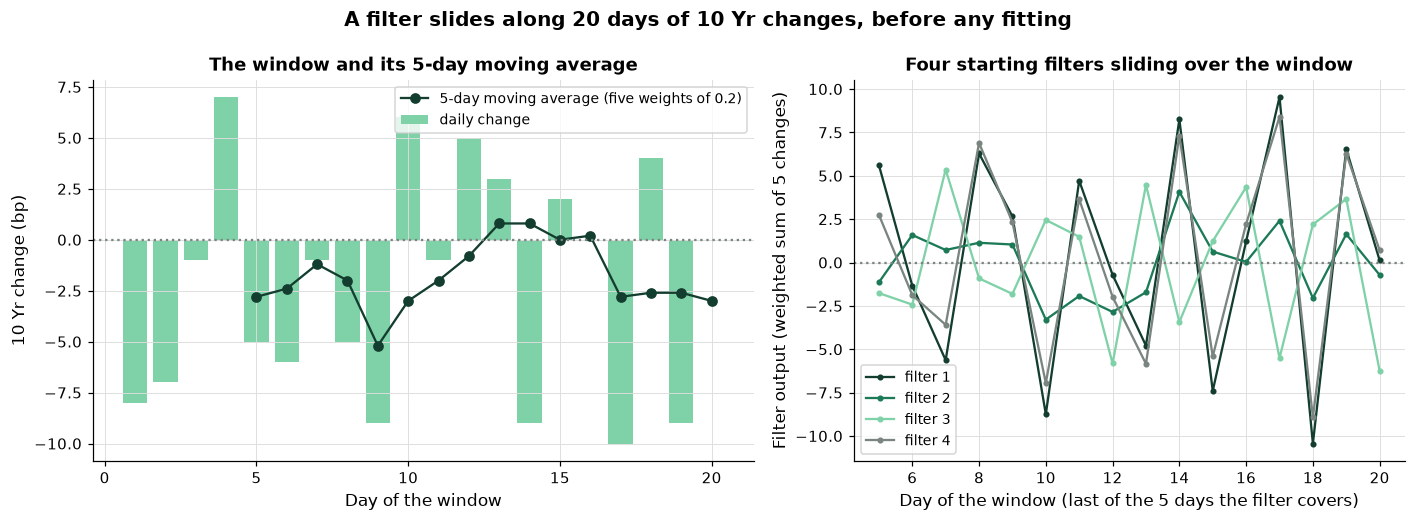

In [22]:
# the 5-day moving average and each filter's output are drawn at the last day of the 5 days they cover
last_days = np.arange(5, 20 + 1)
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
left.bar(np.arange(1, 20 + 1), window_one[:, 0], color=plotkit.GREEN_LIGHT, label="daily change")
left.plot(last_days, moving[:, 0], color=plotkit.GREEN_DARK, marker="o", label="5-day moving average (five weights of 0.2)")
left.axhline(0, color=plotkit.GREY, linestyle=":")
left.set_xticks(range(0, 20 + 1, 5))
left.set_xlabel("Day of the window")
left.set_ylabel("10 Yr change (bp)")
left.set_title("The window and its 5-day moving average")
left.legend(fontsize=9)
for k in range(4):
    right.plot(last_days, hand_one[:, k], marker=".", label=f"filter {k + 1}")
right.axhline(0, color=plotkit.GREY, linestyle=":")
right.set_xlabel("Day of the window (last of the 5 days the filter covers)")
right.set_ylabel("Filter output (weighted sum of 5 changes)")
right.set_title("Four starting filters sliding over the window")
right.legend(fontsize=9)
fig.suptitle("A filter slides along 20 days of 10 Yr changes, before any fitting", fontweight="bold")
fig.tight_layout()
plt.show()

* Left: the daily changes are bars, up to 10 bp in size. The moving average is the line: it is never larger than 5.20 bp in size, because an average of 5 days cannot be larger than the largest of them, and it moves more slowly than the bars. Right: four filters with random starting weights give four different lines, from -10.44 to 9.53; each is a weighted moving sum, and fitting changes the weights, not the sliding. In Excel, a column chart of column B with a line chart of the `SUMPRODUCT` column drawn over it is the left panel.

## 13.2 A Filter Is a Weighted Moving Sum

Each output of a filter is one line of arithmetic. Seeing that line once makes the layer less mysterious.

Q. Write out the first output of the layer's first filter by hand: the window's first five days times the filter's five weights, plus the bias.

In [23]:
first_days = window_one[:5, 0]
weights = kernel_one[:, 0, 0]
print(f"first five days, bp: {first_days.round(2).tolist()}")
# the weights are float32; astype(float) before rounding keeps the printed digits short
print(f"filter 1's weights: {weights.astype(float).round(4).tolist()}; bias {bias_one[0]:.1f}")
by_hand = float(first_days @ weights + bias_one[0])
print(f"sum of day times weight, plus the bias: {by_hand:.4f}; conv1d_by_hand's first output: {hand_one[0, 0]:.4f}")

first five days, bp: [-8.0, -7.0, -1.0, 7.0, -5.0]
filter 1's weights: [0.351, -0.4134, 0.0233, 0.4566, -0.4714]; bias 0.0
sum of day times weight, plus the bias: 5.6165; conv1d_by_hand's first output: 5.6165


* 5.6165: five products added up, plus a bias of 0. In Excel this is `=SUMPRODUCT(B2:B6,$K$2:$K$6)+$K$7` with the window in column B and the weights in K2:K6, filled down 16 rows (Excel Side by Side has it).
* The same five weights are used at every step. That is the difference from day 11's dense network, which gave every day of the window its own weight: a filter has 5 weights however long the window is.

Q. Draw that one output as arithmetic: the five days, the five weights, their five products, and what they add up to.

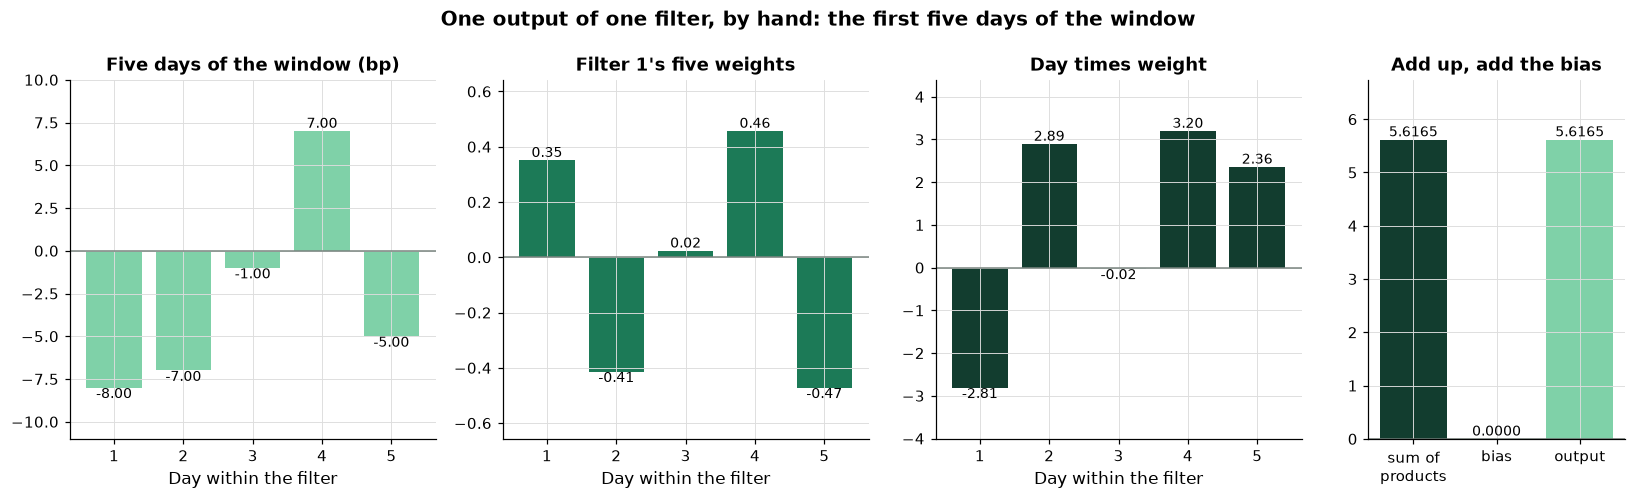

In [24]:
# the first output of filter 1: five days times five weights, the five products, their sum, and the bias
products = first_days * weights
fig, axes = plt.subplots(1, 4, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1, 1, 0.7]})
steps = np.arange(1, 6)
for ax, values, colour, title in [(axes[0], first_days, plotkit.GREEN_LIGHT, "Five days of the window (bp)"),
                                  (axes[1], weights.astype(float), plotkit.GREEN, "Filter 1's five weights"),
                                  (axes[2], products, plotkit.GREEN_DARK, "Day times weight")]:
    bars = ax.bar(steps, values, color=colour)
    ax.bar_label(bars, fmt="%.2f", fontsize=9)
    ax.axhline(0, color=plotkit.GREY, linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("Day within the filter")
    ax.margins(y=0.2)
# the last panel: the sum of the products, the bias, and the filter's output
bars = axes[3].bar(["sum of\nproducts", "bias", "output"], [products.sum(), float(bias_one[0]), by_hand],
                   color=[plotkit.GREEN_DARK, plotkit.GREY, plotkit.GREEN_LIGHT])
axes[3].bar_label(bars, fmt="%.4f", fontsize=9)
axes[3].axhline(0, color=plotkit.GREY, linewidth=1)
axes[3].set_title("Add up, add the bias")
axes[3].margins(y=0.2)
fig.suptitle("One output of one filter, by hand: the first five days of the window", fontweight="bold")
fig.tight_layout()
plt.show()

* Left to right: the window's first five days, the filter's five weights, and each day times its weight; the fourth panel adds the five products (5.6165), adds the bias (0.0), and lands on the output, 5.6165, the first value of `conv1d_by_hand`. Every one of the 16 outputs is this picture on the next five days.
* The signs matter: a positive weight on a day that rose adds to the output, a negative weight on it subtracts. Fitting a filter is choosing five signed weights that make this sum useful, the same five at every position.

**Many tenors as channels.** With 11 channels, a window is 20 days by 11 tenors, and a filter of width 5 is a block of 5 by 11 = 55 weights. Each output is the block of 5 days by 11 tenors, multiplied cell by cell by the weights and added up: still one `SUMPRODUCT`, over a rectangle instead of a column.

Q. Take the same first window with all 11 tenors, run a fresh 4-filter layer on it, and compare with `conv1d_by_hand`.

In [25]:
# the first window again, with all 11 tenors side by side: 20 steps by 11 channels
window_many = netkit.make_windows(changes, changes["10 Yr"], window, [window])[0][0]
keras.utils.set_random_seed(SEED)
conv_many = keras.layers.Conv1D(filters=4, kernel_size=5, name="conv_many")
keras_many = conv_many(window_many[None].astype("float32")).numpy()[0]
kernel_many, bias_many = conv_many.get_weights()
hand_many = netkit.conv1d_by_hand(window_many, kernel_many, bias_many)
print(f"window shape: {window_many.shape}; kernel shape: {kernel_many.shape}; output shape: {keras_many.shape}")
print(f"weights in one filter: {kernel_many[:, :, 0].size}")
print(f"conv1d_by_hand equal to the Keras layer within 1e-5: {np.abs(hand_many - keras_many).max() < 1e-5}")

window shape: (20, 11); kernel shape: (5, 11, 4); output shape: (16, 4)
weights in one filter: 55
conv1d_by_hand equal to the Keras layer within 1e-5: True


* The window is 20 by 11, the kernel 5 by 11 by 4, and the output is still 16 steps by 4 filters: the channels are added up inside each output, so more tenors make each filter bigger, not the output longer.
* Each filter now mixes days and tenors: one weight for the 2 Yr three days back, another for the 30 Yr yesterday. Whether that mixing finds anything in the 10 Yr's next change is what section 13.5 measures.

Q. Draw the 11-tenor window and one filter's 5 by 11 weights as two grids.

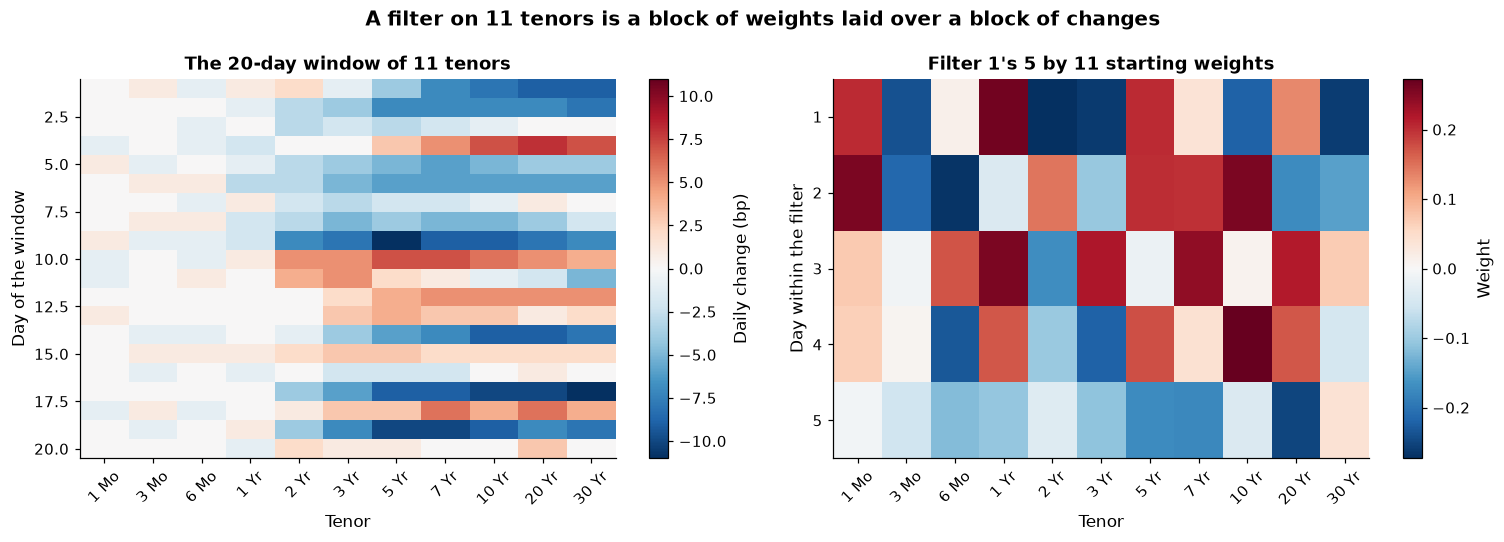

In [26]:
# left: the window, days down and tenors across, in bp; right: filter 1's block of weights, days down and tenors across
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1]})
limit = np.abs(window_many).max()
image = left.imshow(window_many, aspect="auto", cmap="RdBu_r", vmin=-limit, vmax=limit, extent=[-0.5, 11 - 0.5, 20 + 0.5, 0.5])
left.grid(False)
left.set_xticks(range(11), labels=changes.columns, rotation=45)
left.set_xlabel("Tenor")
left.set_ylabel("Day of the window")
left.set_title("The 20-day window of 11 tenors")
fig.colorbar(image, ax=left, label="Daily change (bp)")
weights_block = kernel_many[:, :, 0]
bound = np.abs(weights_block).max()
image = right.imshow(weights_block, aspect="auto", cmap="RdBu_r", vmin=-bound, vmax=bound, extent=[-0.5, 11 - 0.5, 5 + 0.5, 0.5])
right.grid(False)
right.set_xticks(range(11), labels=changes.columns, rotation=45)
right.set_xlabel("Tenor")
right.set_ylabel("Day within the filter")
right.set_title("Filter 1's 5 by 11 starting weights")
fig.colorbar(image, ax=right, label="Weight")
fig.suptitle("A filter on 11 tenors is a block of weights laid over a block of changes", fontweight="bold")
fig.tight_layout()
plt.show()

* Left: the window as a grid, days down and tenors across, red for a rise and blue for a fall; the largest change anywhere in it is 11 bp in size, and neighbouring tenors move together, which shows as vertical bands of one colour. Right: filter 1's 55 weights, none larger than 0.27 in size. Each output multiplies a 5-day slice of the left grid, cell by cell, by the right grid and adds up: `SUMPRODUCT` over a rectangle. Excel's Conditional Formatting, Color Scales, gives the same two grids.

### Width, padding, stride, and dilation

A `Conv1D` layer's shape is set by four numbers, and each has a picture. The **width** is how many days one output covers. **Padding** is `valid` (the filter sits only where it fits, so the sequence gets shorter) or `same` (zeros are added at the ends so every day gets an output). The **stride** is how far the filter moves between outputs. The **dilation** is the gap between the days a filter looks at: with a width of 3 and a dilation of 2 it looks at every second day and covers 5. The output has floor((n + padding - reach) / stride) + 1 steps, where n is the window's length, reach is (width - 1) x dilation + 1, and padding is the zeros added in all (0 for valid).

Q. Change one setting per panel. Run a filter of equal weights, a moving average, over the window with each setting, and draw the outputs at the middle of the days each one covers.

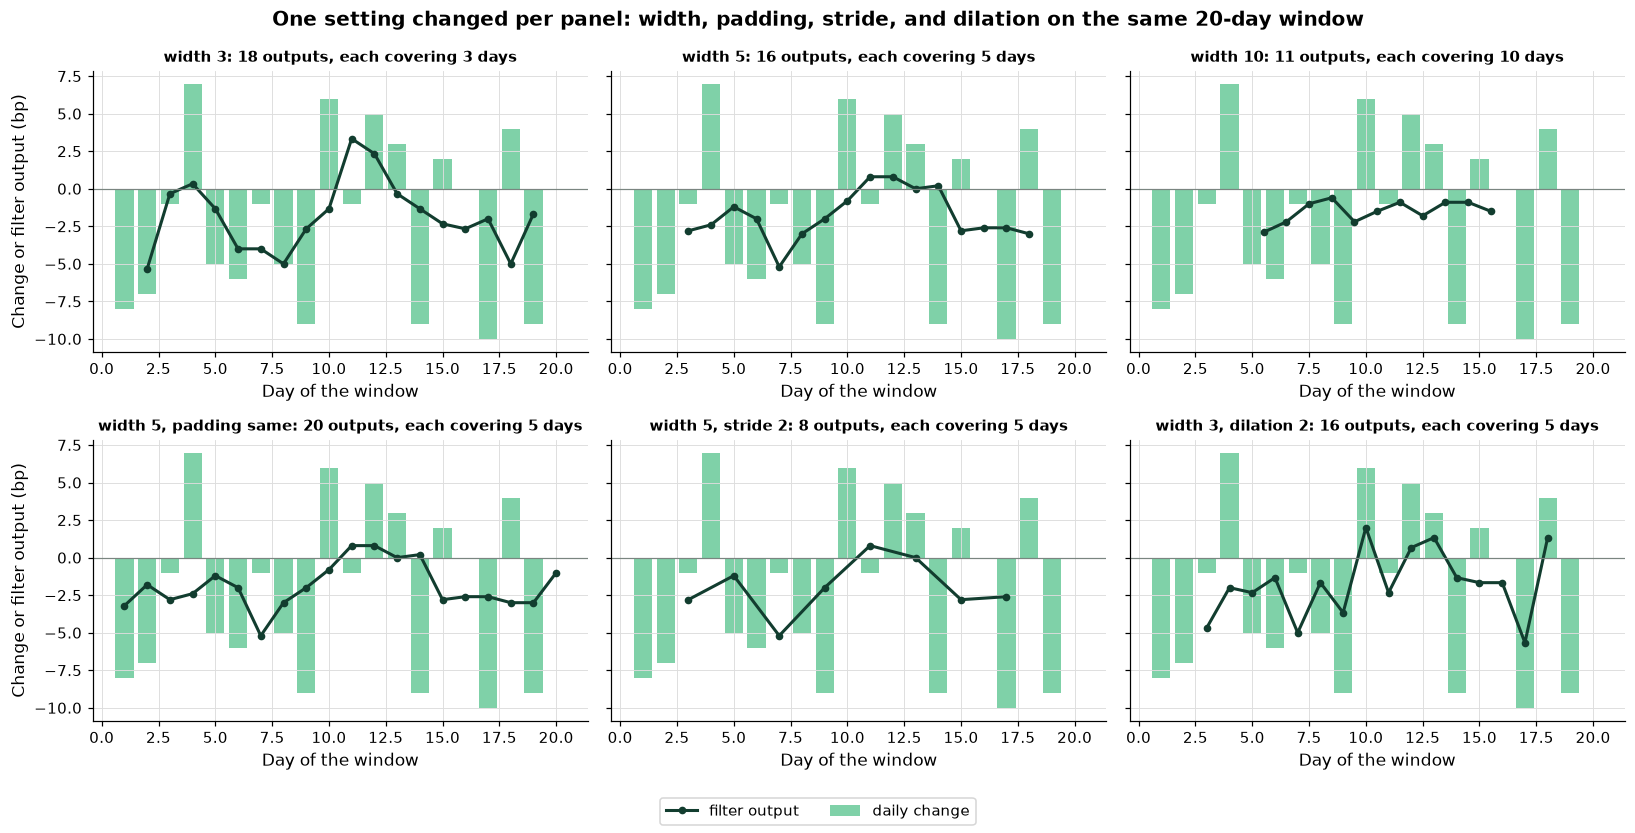

the output length equals the formula in every panel: True


,outputs,days one output covers
setting,,
width 3,18,3
width 5,16,5
width 10,11,10
"width 5, padding same",20,5
"width 5, stride 2",8,5
"width 3, dilation 2",16,5


In [27]:
# a moving average (equal weights 1 / width, no bias) so each output is easy to read; one setting changes per panel
panels = [("width 3", {"kernel_size": 3}), ("width 5", {"kernel_size": 5}), ("width 10", {"kernel_size": 10}),
          ("width 5, padding same", {"kernel_size": 5, "padding": "same"}), ("width 5, stride 2", {"kernel_size": 5, "strides": 2}),
          ("width 3, dilation 2", {"kernel_size": 3, "dilation_rate": 2})]
days = np.arange(1, 21)
keras.utils.set_random_seed(SEED)
fig, axes = plt.subplots(2, 3, figsize=(15, 7.6), sharey=True)
rows = []
for ax, (label, options) in zip(axes.ravel(), panels):
    width, stride, dilation = options["kernel_size"], options.get("strides", 1), options.get("dilation_rate", 1)
    layer = keras.layers.Conv1D(1, kernel_initializer=keras.initializers.Constant(1 / width), use_bias=False, **options)
    output = layer(window_one[None].astype("float32")).numpy()[0, :, 0]
    reach = (width - 1) * dilation + 1
    total_padding = reach - 1 if options.get("padding") == "same" else 0
    # TensorFlow puts the smaller half of the zeros on the left
    left_padding = total_padding // 2
    # the middle day of the days output j covers, counting the first day of the window as day 1
    middle = np.arange(len(output)) * stride - left_padding + (reach - 1) / 2 + 1
    ax.bar(days, window_one[:, 0], color=plotkit.GREEN_LIGHT, label="daily change")
    ax.plot(middle, output, color=plotkit.GREEN_DARK, marker="o", markersize=4, linewidth=2, label="filter output")
    ax.axhline(0, color=plotkit.GREY, linewidth=0.8)
    ax.set_title(f"{label}: {len(output)} outputs, each covering {reach} days", fontsize=10)
    ax.set_xlabel("Day of the window")
    rows.append({"setting": label, "outputs": len(output), "days one output covers": reach,
                 "formula": (20 + total_padding - reach) // stride + 1})
for ax in axes[:, 0]:
    ax.set_ylabel("Change or filter output (bp)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2)
fig.suptitle("One setting changed per panel: width, padding, stride, and dilation on the same 20-day window", fontweight="bold")
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()
shapes = pd.DataFrame(rows).set_index("setting")
print(f"the output length equals the formula in every panel: {bool((shapes['outputs'] == shapes['formula']).all())}")
# a table of lengths: nothing is marked
plotkit.styled(shapes.drop(columns="formula"), [], "The same window through six filter settings: how many outputs, and how many days each one covers")

* **How to read the grid.** Each panel changes one thing from the width-5 panel in the middle of the top row. A wider filter (18 outputs at width 3, 16 at 5, 11 at 10) averages more days, so its line is smoother and shorter. `same` padding gives 20 outputs, one per day, and its first and last outputs dip toward zero because they average the added zeros in with real days. A stride of 2 keeps every second output, 8 of them. A dilation of 2 on a width of 3 covers 5 days with three weights and gives 16 outputs.
* **Which to pick.** The course uses `valid`, stride 1, and no dilation: nothing is invented at the ends, and every output is a plain moving sum. A wider filter looks further back with more weights (96 for 16 filters of width 5, 176 for width 10); a stride or a dilation reaches further back without them. The walk-forward grid in section 13.4 changes the width alone.

### Every setting of `Conv1D`

The layer has 16 settings. The table lists them all with the default read from Keras's own signature, what each controls, and what raising or lowering it does. The four of the grid above are the ones that shape the output; the rest are the weights' starting values, penalties, and limits, met on days 8 and 9.

Q. Build the table from Keras itself.

In [28]:
import inspect

# the defaults come from the installed Keras's own signature, so they are never typed
signature = inspect.signature(keras.layers.Conv1D.__init__)
defaults = {name: p.default for name, p in signature.parameters.items() if name not in ("self", "kwargs")}

# setting: (what it controls, raising it, lowering it, tune first)
notes = {
    'filters': ('how many filters: patterns the layer looks for, each with weights of its own', 'more patterns, more weights, more room to fit noise', 'fewer patterns', 'tune first'),
    'kernel_size': ("the filter's width in days", 'each output covers more days, more weights per filter, a smoother output', 'each output covers fewer days', 'tune first'),
    'strides': ('how many days the filter moves between outputs', 'fewer outputs, a shorter sequence', '1 gives an output at every position', ''),
    'padding': ("'valid': the filter sits only where it fits; 'same': zeros are added at the ends so every day gets an output", 'a choice, not a dial', 'a choice, not a dial', ''),
    'data_format': ('whether the channels axis is last or first in the input', 'a choice, not a dial', "None uses Keras's configured format, channels last", ''),
    'dilation_rate': ('the gap between the days one filter looks at', 'reaches further back with the same weights', '1 looks at consecutive days', ''),
    'groups': ('splits the channels into this many groups, each with its own filters', 'fewer weights, channels mixed less', '1 mixes every channel in every filter', ''),
    'activation': ("applied to each output; None means none (the course's network uses ReLU, section 13.3)", 'a choice', 'None leaves the weighted sum as it is', 'tune first'),
    'use_bias': ('whether each filter has a bias', 'True: a bias per filter', 'False: none', ''),
    'kernel_initializer': ('where the filter weights start', "a choice (day 8's initializers)", 'a choice', ''),
    'bias_initializer': ('where the biases start', 'a choice', 'a choice', ''),
    'kernel_regularizer': ('an optional penalty on the filter weights; None means none', 'a stronger pull toward 0 (day 9)', 'None leaves them alone', ''),
    'bias_regularizer': ('an optional penalty on the biases; None means none', 'a stronger pull toward 0', 'None leaves them alone', ''),
    'activity_regularizer': ("an optional penalty on the layer's outputs; None means none", 'smaller outputs', 'None leaves them alone', ''),
    'kernel_constraint': ("an optional limit on the filter weights' values; None means none", 'a looser limit', 'a tighter limit', ''),
    'bias_constraint': ("an optional limit on the biases' values; None means none", 'a looser limit', 'a tighter limit', ''),
}
# every setting Keras has is described, and nothing else
assert set(notes) == set(defaults)

conv_settings = pd.DataFrame({name: ["required" if defaults[name] is inspect.Parameter.empty else repr(defaults[name]), *notes[name]]
                              for name in defaults}, index=["default", "what it controls", "raising it", "lowering it", "tune first"]).T
conv_settings.index.name = "setting"
print(f"keras.layers.Conv1D has {len(defaults)} settings; the defaults are read from the installed Keras")
# a table of words: nothing is marked
plotkit.styled(conv_settings, [], "Every setting of keras.layers.Conv1D: its default, what it controls, and what raising or lowering it does")

keras.layers.Conv1D has 16 settings; the defaults are read from the installed Keras


,default,what it controls,raising it,lowering it,tune first
setting,,,,,
filters,required,"how many filters: patterns the layer looks for, each with weights of its own","more patterns, more weights, more room to fit noise",fewer patterns,tune first
kernel_size,required,the filter's width in days,"each output covers more days, more weights per filter, a smoother output",each output covers fewer days,tune first
strides,1,how many days the filter moves between outputs,"fewer outputs, a shorter sequence",1 gives an output at every position,
padding,'valid','valid': the filter sits only where it fits; 'same': zeros are added at the ends so every day gets an output,"a choice, not a dial","a choice, not a dial",
data_format,None,whether the channels axis is last or first in the input,"a choice, not a dial","None uses Keras's configured format, channels last",
dilation_rate,1,the gap between the days one filter looks at,reaches further back with the same weights,1 looks at consecutive days,
groups,1,"splits the channels into this many groups, each with its own filters","fewer weights, channels mixed less",1 mixes every channel in every filter,
activation,None,"applied to each output; None means none (the course's network uses ReLU, section 13.3)",a choice,None leaves the weighted sum as it is,tune first
use_bias,True,whether each filter has a bias,True: a bias per filter,False: none,


* 16 settings; `filters` and `kernel_size` have no default and must be given. **Tune first:** `filters` (the number of patterns, 16 here), `kernel_size` (the days one pattern covers, 5 here), and `activation` (ReLU in the course's network, because pooling should average what is left above zero). Everything else stays at its default in the course's network.

## 13.3 Pooling

**How it works.** Pooling squeezes a sequence into fewer numbers. A **global** pooling layer takes each filter's outputs over every position and keeps one number per filter: the average (how much the pattern showed up across the window) or the largest (where it showed up most). A **windowed** pooling layer does the same inside small blocks of positions and keeps one number per block, so the sequence gets shorter but stays a sequence. You control which summary and, for windowed pooling, the block size (`pool_size`) and the step between blocks (`strides`). What comes out is one number per filter, or a shorter sequence, which the final `Dense` layer turns into the fitted change.

A `Conv1D` layer gives 16 outputs per filter. Before the network's single output, those are usually squeezed to one number per filter, which is called **pooling**. `GlobalAveragePooling1D` takes each filter's average over the steps; `GlobalMaxPooling1D` takes each filter's largest output. In a network the filter's outputs go through ReLU first (day 3's `MAX(0, z)`), so pooling averages what is left above zero.

Q. Put the first layer's outputs through ReLU, then pool them by hand and with Keras's two pooling layers.

In [29]:
# ReLU keeps each output above zero and sets the rest to zero
relu_hand = np.maximum(hand_one, 0)
relu_keras = keras.activations.relu(keras_one[None])
# pooling over the steps: one number per filter
average_keras = keras.layers.GlobalAveragePooling1D()(relu_keras).numpy()[0]
max_keras = keras.layers.GlobalMaxPooling1D()(relu_keras).numpy()[0]
print(f"filter 1: {int((hand_one[:, 0] <= 0).sum())} of {len(hand_one)} outputs at or below zero, set to 0 by ReLU")
print(f"average pooling, by hand: {relu_hand.mean(axis=0).round(4).tolist()}")
print(f"max pooling, by hand:     {relu_hand.max(axis=0).round(4).tolist()}")
same = np.abs(relu_hand.mean(axis=0) - average_keras).max() < 1e-5 and np.abs(relu_hand.max(axis=0) - max_keras).max() < 1e-5
print(f"equal to Keras's pooling layers within 1e-5: {same}")

filter 1: 7 of 16 outputs at or below zero, set to 0 by ReLU
average pooling, by hand: [2.8086, 0.8285, 1.575, 2.5319]
max pooling, by hand:     [9.5347, 4.0728, 5.3602, 8.3941]
equal to Keras's pooling layers within 1e-5: True


* ReLU set 7 of filter 1's 16 outputs to 0, and average pooling gives 2.8086 for filter 1, max pooling 9.5347. Four filters, four numbers each way: pooling turns a window of any length into one number per filter.
* Average pooling asks "how much did this pattern show up across the window"; max pooling asks "where did it show up most". The network today uses the average, the gentler of the two on 20 noisy days.

Q. Write the convolution's build function: 16 filters of width 5 with ReLU, average pooling, and one linear output. Trace a window through it.

In [30]:
# seed before building any Keras model, so its numbers never depend on what ran before
def conv_window(window, channels, width=5):
    """A one-dimensional convolution on a window: 16 filters of `width` days with ReLU, the average of each
    filter's outputs over the window, and one linear output."""
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(window, channels)),
                              keras.layers.Conv1D(16, width, activation="relu", name="conv"),
                              keras.layers.GlobalAveragePooling1D(name="pool"),
                              keras.layers.Dense(1, name="output")], name="conv_window")
    # mean squared error on the standardized change, Adam at Keras's default learning rate
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
    return model


model = conv_window(20, 1)
# send the first window through the layers one at a time, and print the shape after each
flowing = window_one[None].astype("float32")
for layer in model.layers:
    flowing = layer(flowing)
    print(f"after {layer.name}: shape {tuple(flowing.shape)}")
print(f"conv_window(20, 1): {model.count_params()} weights and biases; on 11 tenors: {conv_window(20, 11).count_params()}")

after conv: shape (1, 16, 16)
after pool: shape (1, 16)
after output: shape (1, 1)
conv_window(20, 1): 113 weights and biases; on 11 tenors: 913


* A batch of one window, 20 days by 1 channel, becomes 16 steps by 16 filters, then 16 pooled numbers, then one output: the standardized change, turned back to bp by `walk_forward_network`, as on day 11.
* 113 numbers: 5 x 16 filter weights and 16 biases, then 16 weights and one bias at the output. Day 11's dense network had 353. On 11 tenors the convolution has 913: each filter grows to 5 x 11 weights.

Q. Draw filter 1's outputs after ReLU with its two pooled values, and the four filters' pooled numbers.

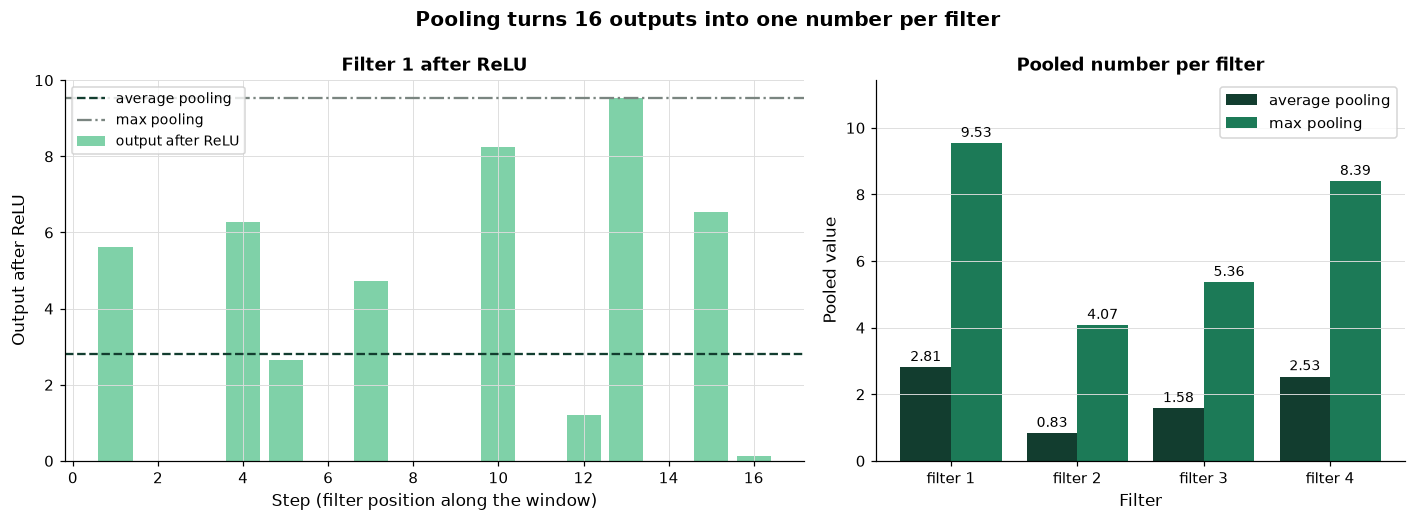

,average pooling,max pooling,outputs at or below zero
Filter,,,
filter 1,2.8086,9.5347,7
filter 2,0.8285,4.0728,7
filter 3,1.5750,5.3602,8
filter 4,2.5319,8.3941,7


In [31]:
# left: filter 1's outputs after ReLU, with the two pooled values; right: the pooled numbers of all four filters
pooled = pd.DataFrame({"average pooling": relu_hand.mean(axis=0), "max pooling": relu_hand.max(axis=0),
                       "outputs at or below zero": (hand_one <= 0).sum(axis=0)},
                      index=pd.Index([f"filter {k}" for k in range(1, 5)], name="Filter"))
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
left.bar(np.arange(1, 16 + 1), relu_hand[:, 0], color=plotkit.GREEN_LIGHT, label="output after ReLU")
left.axhline(pooled.loc["filter 1", "average pooling"], color=plotkit.GREEN_DARK, linestyle="--", label="average pooling")
left.axhline(pooled.loc["filter 1", "max pooling"], color=plotkit.GREY, linestyle="-.", label="max pooling")
left.set_xlabel("Step (filter position along the window)")
left.set_ylabel("Output after ReLU")
left.set_title("Filter 1 after ReLU")
left.legend(fontsize=9)
plotkit.bars(pooled[["average pooling", "max pooling"]], "Pooled number per filter", "Pooled value", ax=right, fmt="{:.2f}")
right.set_ylim(0, pooled[["average pooling", "max pooling"]].to_numpy().max() * 1.2)
fig.suptitle("Pooling turns 16 outputs into one number per filter", fontweight="bold")
fig.tight_layout()
plt.show()
# the rows are filters, not rival models, so no cell is marked
plotkit.styled(pooled, [], "Pooling of the four starting filters on the first window: average and max of the 16 outputs after ReLU, and how many ReLU set to 0", fmt="{:.4f}")

* Left: ReLU set 7 of filter 1's 16 bars to 0. The dashed line is the average of all 16, 2.8086; the dash-dot line is the largest, 9.5347. Right: the same two numbers for each of the four filters. The max is always the taller bar, and each filter has a pair of its own. In Excel, `AVERAGE` and `MAX` of a column of `MAX(0, ...)` cells give the two numbers.

Q. Pool in blocks instead of all at once. Take filter 1's 16 outputs after ReLU and pool them with `MaxPooling1D` and `AveragePooling1D` in blocks of 4, with a step of 2, and with the two global layers, one setting changed per panel.

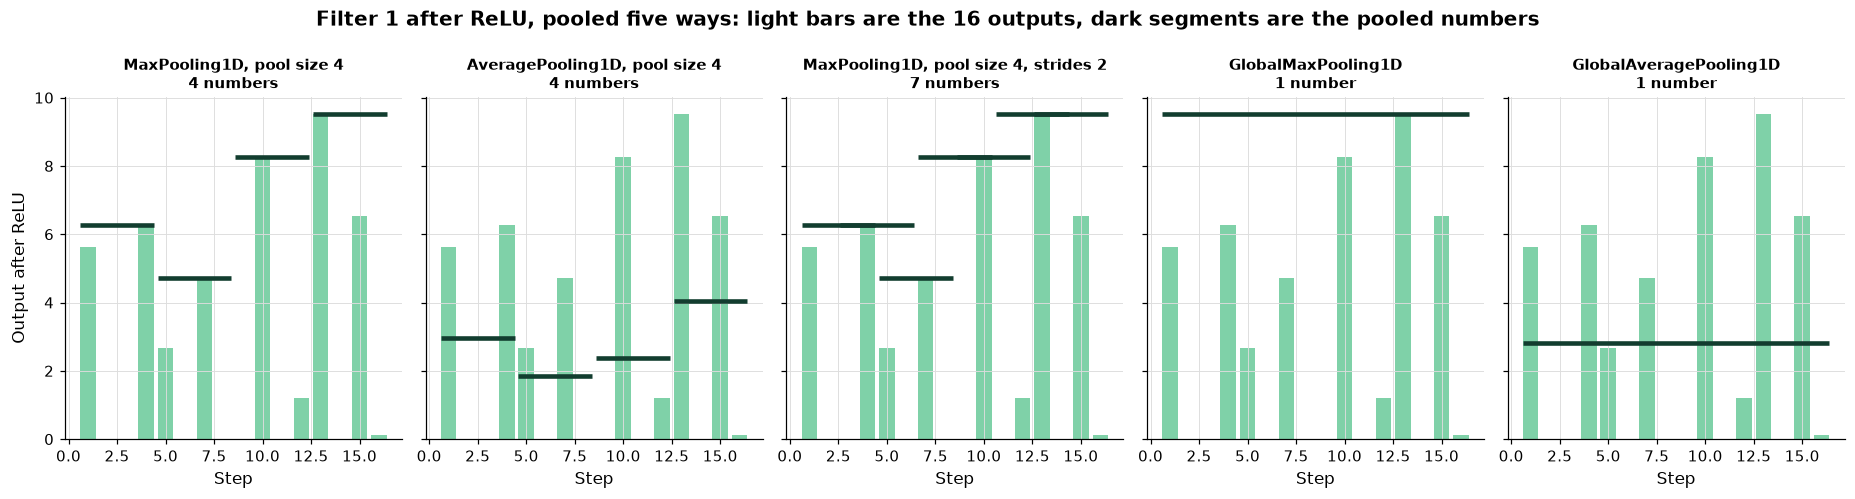

first block of four by hand: max 6.2845, average 2.9753; pooled numbers per panel: [4, 4, 7, 1, 1]


In [32]:
# filter 1's 16 outputs after ReLU, as a batch of one sequence with one channel
sequence = relu_hand[:, 0][None, :, None].astype("float32")
panels = [("MaxPooling1D, pool size 4", keras.layers.MaxPooling1D(pool_size=4)),
          ("AveragePooling1D, pool size 4", keras.layers.AveragePooling1D(pool_size=4)),
          ("MaxPooling1D, pool size 4, strides 2", keras.layers.MaxPooling1D(pool_size=4, strides=2)),
          ("GlobalMaxPooling1D", keras.layers.GlobalMaxPooling1D()),
          ("GlobalAveragePooling1D", keras.layers.GlobalAveragePooling1D())]
fig, axes = plt.subplots(1, 5, figsize=(17, 4.6), sharey=True)
steps = np.arange(1, 17)
counts = []
for ax, (label, layer) in zip(axes, panels):
    pooled = layer(sequence).numpy().reshape(-1)
    counts.append(len(pooled))
    ax.bar(steps, relu_hand[:, 0], color=plotkit.GREEN_LIGHT)
    # each pooled number as a segment over the block of steps it summarizes
    size = getattr(layer, "pool_size", (16,))[0]
    stride = getattr(layer, "strides", (size,))[0] if hasattr(layer, "pool_size") else 16
    for j, value in enumerate(pooled):
        start = j * stride + 1
        ax.hlines(value, start - 0.4, start + size - 1 + 0.4, color=plotkit.GREEN_DARK, linewidth=3)
    ax.set_title(f"{label}\n{len(pooled)} number{'s' if len(pooled) != 1 else ''}", fontsize=10)
    ax.set_xlabel("Step")
axes[0].set_ylabel("Output after ReLU")
fig.suptitle("Filter 1 after ReLU, pooled five ways: light bars are the 16 outputs, dark segments are the pooled numbers", fontweight="bold")
fig.tight_layout()
plt.show()
# the blocks by hand: the first block of four, in numpy
first_block = relu_hand[:4, 0]
print(f"first block of four by hand: max {first_block.max():.4f}, average {first_block.mean():.4f}; pooled numbers per panel: {counts}")

* Left to right: blocks of 4 with the maximum give 4 numbers; the average gives 4, each at or below the maximum of its block; a step of 2 lets the blocks overlap and gives 7; the two global layers give one number each, the 9.5347 and 2.8086 of the table above. Windowed pooling keeps where along the window a pattern showed up, roughly; global pooling throws that away and keeps how strongly. The course's networks use the average, global, because their next layer is a `Dense` layer that wants a fixed number of inputs per filter.

### Every setting of the pooling layers

Four pooling layers cover the two choices, global or windowed, and average or maximum. They share a few settings; the table lists every one of them with each layer's default from Keras's own signature (a dash where a layer lacks it).

Q. Build the table from Keras itself.

In [33]:
import inspect

# the defaults come from the installed Keras's own signatures, so they are never typed
pools = {"MaxPooling1D": keras.layers.MaxPooling1D, "AveragePooling1D": keras.layers.AveragePooling1D,
         "GlobalMaxPooling1D": keras.layers.GlobalMaxPooling1D, "GlobalAveragePooling1D": keras.layers.GlobalAveragePooling1D}
defaults = {kind: {name: p.default for name, p in inspect.signature(layer.__init__).parameters.items() if name not in ("self", "kwargs", "name")}
            for kind, layer in pools.items()}
names = list(dict.fromkeys(name for d in defaults.values() for name in d))

# setting: (what it controls, raising it, lowering it, tune first)
notes = {
    'pool_size': ('how many steps one block holds (MaxPooling1D and AveragePooling1D)', 'fewer, coarser numbers', 'finer, closer to no pooling', 'tune first'),
    'strides': ("how far the block moves between outputs; None means one block's width, so blocks do not overlap", 'fewer outputs', 'overlapping blocks, more outputs', ''),
    'padding': ("'valid': only whole blocks; 'same': zeros fill the last block", 'a choice, not a dial', 'a choice, not a dial', ''),
    'data_format': ('whether the channels axis is last or first in the input', 'a choice, not a dial', "None uses Keras's configured format", ''),
    'keepdims': ('whether a global layer keeps the steps axis, with length 1 (global layers only)', 'True: output (batch, 1, channels)', 'False: output (batch, channels)', ''),
}
# every setting Keras has is described, and nothing else
assert set(notes) == set(names)


def default_text(kind, name):
    if name not in defaults[kind]:
        return "-"
    return "required" if defaults[kind][name] is inspect.Parameter.empty else repr(defaults[kind][name])


pool_settings = pd.DataFrame({name: [default_text(kind, name) for kind in pools] + list(notes[name]) for name in names},
                             index=list(pools) + ["what it controls", "raising it", "lowering it", "tune first"]).T
pool_settings.index.name = "setting"
print(f"the four pooling layers have {len(names)} settings between them; the defaults are read from the installed Keras")
# a table of words: nothing is marked
plotkit.styled(pool_settings, [], "Every setting of the four pooling layers: each default, what it controls, and what raising or lowering it does")

the four pooling layers have 5 settings between them; the defaults are read from the installed Keras


,MaxPooling1D,AveragePooling1D,GlobalMaxPooling1D,GlobalAveragePooling1D,what it controls,raising it,lowering it,tune first
setting,,,,,,,,
pool_size,2,required,-,-,how many steps one block holds (MaxPooling1D and AveragePooling1D),"fewer, coarser numbers","finer, closer to no pooling",tune first
strides,None,None,-,-,"how far the block moves between outputs; None means one block's width, so blocks do not overlap",fewer outputs,"overlapping blocks, more outputs",
padding,'valid','valid',-,-,'valid': only whole blocks; 'same': zeros fill the last block,"a choice, not a dial","a choice, not a dial",
data_format,None,None,None,None,whether the channels axis is last or first in the input,"a choice, not a dial",None uses Keras's configured format,
keepdims,-,-,False,False,"whether a global layer keeps the steps axis, with length 1 (global layers only)","True: output (batch, 1, channels)","False: output (batch, channels)",


* 5 settings. `pool_size` has no default on `AveragePooling1D` and defaults to 2 on `MaxPooling1D`; `strides=None` means one block's width. **Tune first:** which summary (average or maximum), then `pool_size` for the windowed layers. The course's network uses `GlobalAveragePooling1D` with every setting at its default.

## 13.4 Walk-Forward Conv1D on the 10 Yr Changes

The convolution needs company: days 11 and 12's networks on the same five folds. A fresh work folder holds none of their results, so they are fitted again here, on the same folds, with the same settings: day 11's dense network on the flattened window, and day 12's three recurrent layers of 16 units (SimpleRNN, LSTM, GRU). `walk_forward_network` reseeds before every fold, so the same build on the same rows gives the same numbers on any day.

Q. Write day 11's and day 12's build functions, and score all four networks walk-forward on the 10 Yr changes: five folds of 252 dates, the first fitted on 504.

In [34]:
def dense_window(window, channels):
    """Day 11's network: a dense network on a flattened window, window x channels inputs, 16 ReLU units, one
    linear output."""
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(window, channels)), keras.layers.Flatten(name="flatten"),
                              keras.layers.Dense(16, activation="relu", name="hidden"),
                              keras.layers.Dense(1, name="output")], name="dense_window")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
    return model


def recurrent_window(layer):
    """Day 12's networks: a build function for one recurrent layer of 16 units (keras.layers.SimpleRNN, LSTM, or
    GRU) that reads the window day by day, and one linear output."""
    def build(window, channels):
        keras.utils.set_random_seed(SEED)
        model = keras.Sequential([keras.Input(shape=(window, channels)), layer(16, name="recurrent"),
                                  keras.layers.Dense(1, name="output")], name=f"{layer.__name__.lower()}_window")
        model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
        return model
    return build


earlier = {"dense_16_changes": dense_window, "simple_rnn_16": recurrent_window(keras.layers.SimpleRNN),
           "lstm_16": recurrent_window(keras.layers.LSTM), "gru_16": recurrent_window(keras.layers.GRU)}
tables = {}
for name, build in earlier.items():
    # every fold: scaler and target statistics from the training dates, the last fifth to stop on, fitted only on
    # earlier dates
    tables[name], _ = netkit.walk_forward_network(build, changes[["10 Yr"]], changes["10 Yr"], changes.index, window=20, min_train=504, test_size=252)
zero = tables["dense_16_changes"]["zero_change_mae_bp"]
train_mean = tables["dense_16_changes"]["train_mean_mae_bp"]
print(f"zero change (the last value carried forward): {zero.mean():.2f} bp; training mean: {train_mean.mean():.2f} bp")
for name, table in tables.items():
    below = int((table["mae_bp"].to_numpy() < zero.to_numpy()).sum())
    print(f"{name}: walk-forward MAE {table['mae_bp'].mean():.2f} bp, below zero change on {below} of {len(table)} folds")

zero change (the last value carried forward): 3.21 bp; training mean: 3.22 bp
dense_16_changes: walk-forward MAE 3.35 bp, below zero change on 0 of 5 folds
simple_rnn_16: walk-forward MAE 3.31 bp, below zero change on 0 of 5 folds
lstm_16: walk-forward MAE 3.23 bp, below zero change on 0 of 5 folds
gru_16: walk-forward MAE 3.22 bp, below zero change on 1 of 5 folds


**Rows.** Every network on the Treasury file in this notebook is fitted and scored walk-forward inside the development years, 2015-01-02 to 2022-12-30; the held-out years, 2023-01-03 to 2026-10-02, are opened once, on day 14, and nothing is fitted for or reported at any date after 2026-10-02.

* Averaged over the five folds, from 2017-02-07 to 2022-02-17: zero change 3.21 bp, the training mean 3.22 bp, and the four networks 3.35, 3.31, 3.23, and 3.22 bp. No network's average is below zero change's, and below it fold by fold the four manage 0, 0, 0, and 1 of 5.
* These rows rebuild days 11 and 12 with the course's settings. If your own day 11 or day 12 notebook shows other numbers, check the build functions against these first.

Q. Now the convolution, on the same folds. Print the table fold by fold.

In [35]:
conv_table, conv_fitted = netkit.walk_forward_network(conv_window, changes[["10 Yr"]], changes["10 Yr"], changes.index,
                                                      window=20, min_train=504, test_size=252)
show = conv_table[["test_start", "test_end", "mae_bp", "zero_change_mae_bp", "train_mean_mae_bp", "best_epoch"]].copy()
# dates without times
for column in ("test_start", "test_end"):
    show[column] = pd.to_datetime(show[column]).dt.strftime("%Y-%m-%d")
# the rows are folds, so no cell is marked as best
display(plotkit.styled(show, [], "The Conv1D on the 10 Yr changes, fold by fold: its MAE, zero change's, and the training mean's in bp, and the epoch kept", fmt="{:.2f}"))
tables["conv1d_16"] = conv_table
below = int((conv_table["mae_bp"].to_numpy() < zero.to_numpy()).sum())
print(f"mean over {len(conv_table)} folds: Conv1D {conv_table['mae_bp'].mean():.2f} bp, zero change {zero.mean():.2f} bp; "
      f"below zero change on {below} of {len(conv_table)} folds")
# how far the fitted changes spread, against the actual changes on the same dates
actual = changes["10 Yr"].loc[conv_fitted.index]
print(f"standard deviation on the test dates: fitted {conv_fitted.std():.2f} bp, actual {actual.std():.2f} bp")

,test_start,test_end,mae_bp,zero_change_mae_bp,train_mean_mae_bp,best_epoch
fold_1,2017-02-07,2018-02-07,2.74,2.72,2.74,1
fold_2,2018-02-08,2019-02-12,2.80,2.76,2.79,50
fold_3,2019-02-13,2020-02-14,3.50,3.44,3.46,1
fold_4,2020-02-18,2021-02-18,3.57,3.53,3.53,1
fold_5,2021-02-19,2022-02-17,3.60,3.59,3.59,50


mean over 5 folds: Conv1D 3.24 bp, zero change 3.21 bp; below zero change on 0 of 5 folds
standard deviation on the test dates: fitted 0.25 bp, actual 4.33 bp


* The Conv1D scores 3.24 bp against zero change's 3.21 bp, 0.03 bp behind on average, and below zero change on 0 of 5 folds. Like every network before it, it did not beat carrying the last value forward on these dates.
* The best epoch was 1 on 3 folds: the stopping rows' loss was lowest after one pass, and early stopping kept those weights. On 2 folds it ran to the limit of 50 epochs, because the stopping loss kept edging down. The fitted changes spread 0.25 bp against the actual 4.33 bp: a network that finds little to fit stays close to the training mean, and its error ends near the training mean's (3.22 bp).
* The folds differ more than the models do: zero change ranges from 2.72 bp (fold_1) to 3.59 bp (fold_5), because some years moved more than others. That is why every comparison here is on the same folds.

Q. Put the two rules and the five networks side by side, as a table and as bars, with each one's gap to zero change.

,mean fold MAE (bp),folds below zero change
zero change,3.21,0
training mean,3.22,0
dense_16_changes,3.35,0
simple_rnn_16,3.31,0
lstm_16,3.23,0
gru_16,3.22,1
conv1d_16,3.24,0


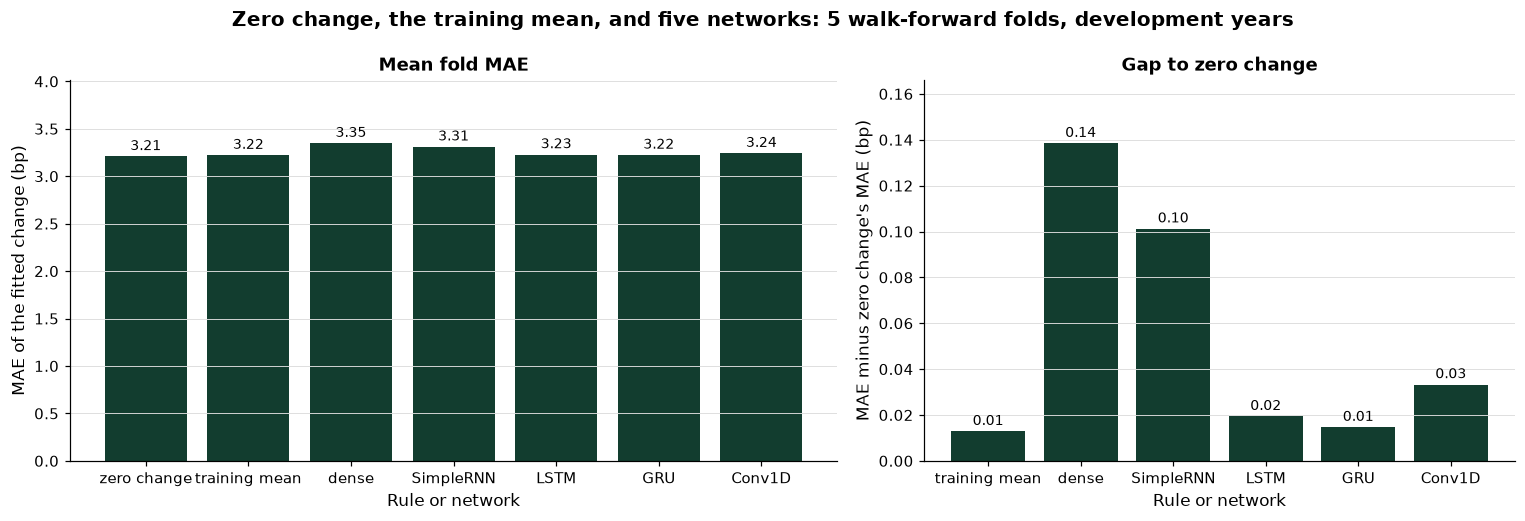

In [36]:
# one row per rule or network: the mean over the five folds, and the folds below zero change
names = ["dense_16_changes", "simple_rnn_16", "lstm_16", "gru_16", "conv1d_16"]
means = pd.DataFrame({"mean fold MAE (bp)": [zero.mean(), train_mean.mean()] + [tables[n]["mae_bp"].mean() for n in names],
                      "folds below zero change": [0, int((train_mean.to_numpy() < zero.to_numpy()).sum())]
                                                 + [int((tables[n]["mae_bp"].to_numpy() < zero.to_numpy()).sum()) for n in names]},
                     index=["zero change", "training mean"] + names)
# the lowest mean fold MAE is marked: it ranks the rows, a rule and five networks scored on the same dates
display(plotkit.styled(means, ["mean fold MAE (bp)"], "Mean of the five walk-forward fold MAEs of the 10 Yr daily change in bp: two rules and five networks, scored on the same test dates",
                       higher_is_better=False, fmt="{:.2f}"))
# short names for the axis, and each score minus zero change's
short = {"zero change": "zero change", "training mean": "training mean", "dense_16_changes": "dense", "simple_rnn_16": "SimpleRNN",
         "lstm_16": "LSTM", "gru_16": "GRU", "conv1d_16": "Conv1D"}
scores = means[["mean fold MAE (bp)"]].rename(index=short)
scores.index.name = "Rule or network"
gap_to_zero = (scores - scores.loc["zero change"]).drop(index="zero change").rename(columns={"mean fold MAE (bp)": "mean fold MAE minus zero change's (bp)"})
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
plotkit.bars(scores, "Mean fold MAE", "MAE of the fitted change (bp)", ax=left, fmt="{:.2f}")
left.set_ylim(0, scores.max().iloc[0] * 1.2)
plotkit.bars(gap_to_zero, "Gap to zero change", "MAE minus zero change's MAE (bp)", ax=right, fmt="{:.2f}")
right.set_ylim(0, gap_to_zero.max().iloc[0] * 1.2)
fig.suptitle("Zero change, the training mean, and five networks: 5 walk-forward folds, development years", fontweight="bold")
fig.tight_layout()
plt.show()

* Left: the seven bars are nearly the same height, and zero change, 3.21 bp, is the lowest. Right: each one's gap above it, in bp: the training mean 0.01, the dense network 0.14, the SimpleRNN 0.10, the LSTM 0.02, the GRU 0.01, the Conv1D 0.03. The table marks the lowest score in its column, which ranks the rows, not any security. In Excel, a clustered column chart of the table's first column draws the left panel.

Q. Draw the Conv1D's fitted change beside the actual change on fold 1's test dates.

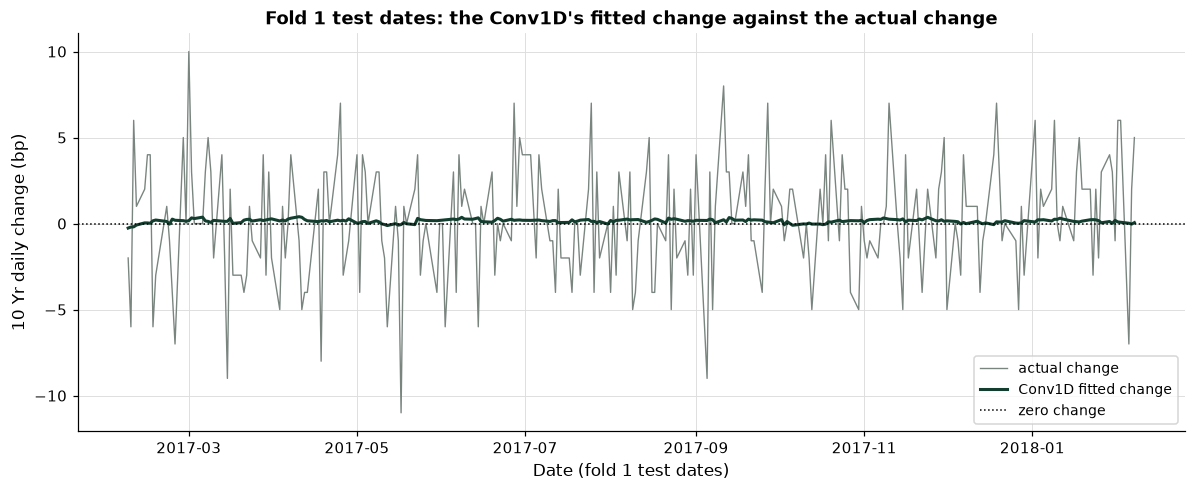

In [37]:
fold_1 = conv_fitted.loc[conv_table["test_start"].iloc[0]:conv_table["test_end"].iloc[0]]
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(fold_1.index, changes["10 Yr"].loc[fold_1.index], color=plotkit.GREY, linewidth=0.9, label="actual change")
ax.plot(fold_1.index, fold_1, color=plotkit.GREEN_DARK, linewidth=2, label="Conv1D fitted change")
ax.axhline(0, color="black", linestyle=":", linewidth=1, label="zero change")
ax.set_xlabel("Date (fold 1 test dates)")
ax.set_ylabel("10 Yr daily change (bp)")
ax.set_title("Fold 1 test dates: the Conv1D's fitted change against the actual change")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

* The actual changes swing several bp either way; the Conv1D's fitted change is a nearly flat line just off zero, as the GRU's was on day 12. On a date when the 10 Yr moved a lot, the fitted change was as small as on any other date.

Q. Change one setting of the convolution, the filter width: fit widths of 3 and 15 days as well as 5, and draw the three side by side, one per panel, fold by fold.

,weights and biases,network MAE,zero change MAE,gap,folds below zero change
filter width (days),,,,,
3,81,3.239,3.209,0.030,0
5,113,3.242,3.209,0.033,0
15,273,3.247,3.209,0.038,0


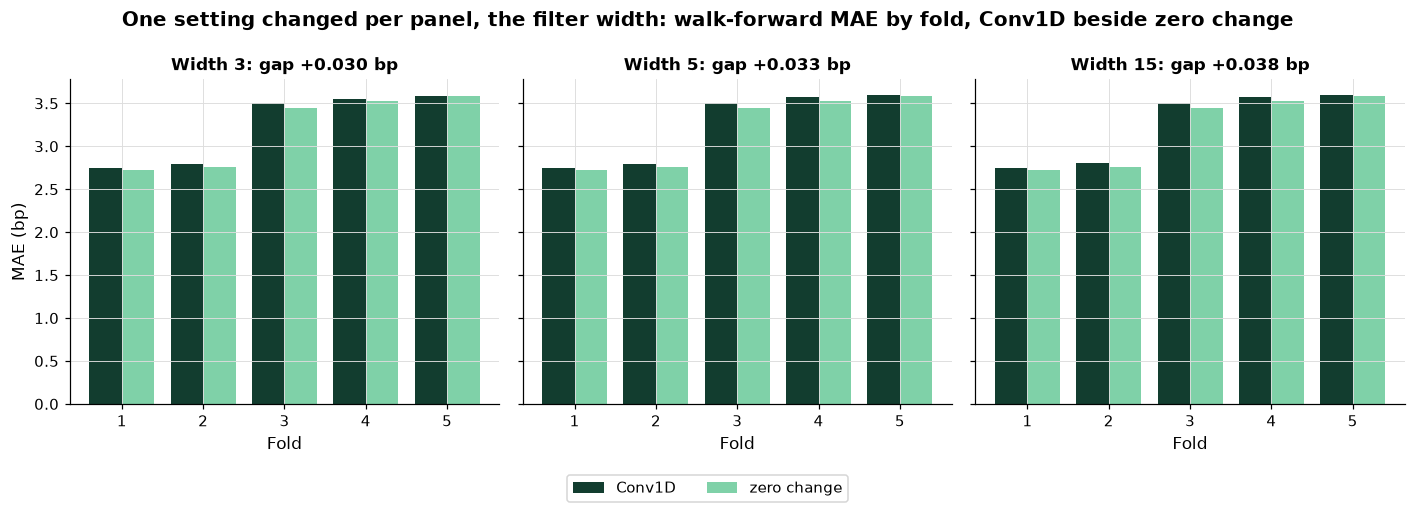

In [38]:
# the width is the only setting that changes: same 16 filters, window, folds, seed, and stopping rule
def conv_of_width(width):
    return lambda window, channels: conv_window(window, channels, width=width)


width_tables = {3: netkit.walk_forward_network(conv_of_width(3), changes[["10 Yr"]], changes["10 Yr"], changes.index, window=20, min_train=504, test_size=252)[0],
                5: conv_table,
                15: netkit.walk_forward_network(conv_of_width(15), changes[["10 Yr"]], changes["10 Yr"], changes.index, window=20, min_train=504, test_size=252)[0]}
width_grid = pd.DataFrame({width: {"weights and biases": conv_window(20, 1, width=width).count_params(),
                                    "network MAE": t["mae_bp"].mean(), "zero change MAE": t["zero_change_mae_bp"].mean(),
                                    "gap": (t["mae_bp"] - t["zero_change_mae_bp"]).mean(),
                                    "folds below zero change": int((t["mae_bp"] < t["zero_change_mae_bp"]).sum())}
                          for width, t in width_tables.items()}).T
width_grid.index.name = "filter width (days)"
for column in ["network MAE", "zero change MAE", "gap"]:
    width_grid[column] = width_grid[column].astype(float)
for column in ["weights and biases", "folds below zero change"]:
    width_grid[column] = width_grid[column].astype(int)
# lower is better for the network's MAE and the gap
display(plotkit.styled(width_grid, ["network MAE", "gap"], "The Conv1D at three filter widths: mean fold MAE in bp over five folds, development years",
                       higher_is_better=False, fmt="{:.3f}"))

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), sharey=True)
fold_axis = np.arange(1, 6)
for ax, (width, t) in zip(axes, width_tables.items()):
    ax.bar(fold_axis - 0.2, t["mae_bp"], width=0.4, color=plotkit.GREEN_DARK, label="Conv1D")
    ax.bar(fold_axis + 0.2, t["zero_change_mae_bp"], width=0.4, color=plotkit.GREEN_LIGHT, label="zero change")
    ax.set_title(f"Width {width}: gap {width_grid.loc[width, 'gap']:+.3f} bp", fontsize=11)
    ax.set_xticks(fold_axis, [f"{k}" for k in fold_axis])
    ax.set_xlabel("Fold")
axes[0].set_ylabel("MAE (bp)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2)
fig.suptitle("One setting changed per panel, the filter width: walk-forward MAE by fold, Conv1D beside zero change", fontweight="bold")
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

* **How to read the grid.** Each panel is one filter width on the same network, windows, folds, and seed; the dark bar is the Conv1D, the light bar zero change on the same dates. The gaps are +0.030 bp at width 3, +0.033 at width 5, and +0.038 at width 15, with 81.0, 113.0, and 273.0 weights and biases.
* **Which width.** The grid does not pick one. Every width is behind zero change on all 5 folds, and the three gaps sit within 0.008 bp of each other, the widest filter slightly behind: a spread that small, from one fit each, is not a basis for choosing. Width 3 has the fewest weights and the smallest gap, so it is the simplest; the course keeps 5, chosen before this grid was run. Three fits, one setting changed, scored on the development years.

## 13.5 Many Tenors as Channels

The 10 Yr's own past changes held nothing a network could use. The rest of the curve is the obvious next place to look: did the 2 Yr's or the 30 Yr's changes over the 20 days before a date say anything about the 10 Yr's change on that date? The windows now carry all 11 tenors as channels, so `walk_forward_network` gets the 11 columns as `values` and the 10 Yr as the target. Its scaler standardizes each tenor separately, on the training rows only.

When this course was built, the 11-tenor convolution was fitted several times in separate runs on one thread: its weights were not always identical in the last digits from one run to the next, though its MAE agreed to 6 decimals every time. So this notebook prints that network's MAE to 2 decimals and its fold counts, and never its weights or its fitted changes. Every other network here gives the same digits on every run.

Q. Score three networks walk-forward on all 11 tenors: day 11's dense network, day 12's LSTM, and today's convolution.

In [39]:
many = {"dense_16_11_tenors": dense_window, "lstm_16_11_tenors": recurrent_window(keras.layers.LSTM),
        "conv1d_16_11_tenors": conv_window}
one_channel = {"dense_16_11_tenors": tables["dense_16_changes"], "lstm_16_11_tenors": tables["lstm_16"],
               "conv1d_16_11_tenors": conv_table}
for name, build in many.items():
    tables[name], _ = netkit.walk_forward_network(build, changes, changes["10 Yr"], changes.index, window=20, min_train=504, test_size=252)
    below = int((tables[name]["mae_bp"].to_numpy() < zero.to_numpy()).sum())
    # MAE in bp to 2 decimals, beside the same network on the 10 Yr alone
    print(f"{name}: walk-forward MAE {tables[name]['mae_bp'].mean():.2f} bp (10 Yr alone "
          f"{one_channel[name]['mae_bp'].mean():.2f}), below zero change on {below} of {len(tables[name])} folds")

dense_16_11_tenors: walk-forward MAE 3.87 bp (10 Yr alone 3.35), below zero change on 0 of 5 folds


lstm_16_11_tenors: walk-forward MAE 3.23 bp (10 Yr alone 3.23), below zero change on 1 of 5 folds


conv1d_16_11_tenors: walk-forward MAE 3.26 bp (10 Yr alone 3.24), below zero change on 0 of 5 folds


* The dense network got worse with more tenors: 3.87 bp against 3.35 bp on the 10 Yr alone, 0.52 bp more. Flattened, the window is now 20 x 11 = 220 inputs and 3,553 weights, fitted on about 404 windows in the first fold: more weights than rows, and more room to fit noise.
* The LSTM (3.23 bp, below zero change on 1 of 5 folds) and the convolution (3.26 bp, 0 of 5) hardly moved from their one-tenor scores. Both share their weights along the window, so 11 channels cost them fewer weights than they cost the dense network (1,809 and 913 against 3,553), and they ended about where they began: close to the training mean, behind zero change.
* On these dates, the other tenors' changes over the 20 days before a date held nothing these networks could fit that beat a change of zero. That describes these 1,260 past dates; it is not a statement about any other dates.

Q. Draw each network on the 10 Yr alone and on all 11 tenors, beside zero change.

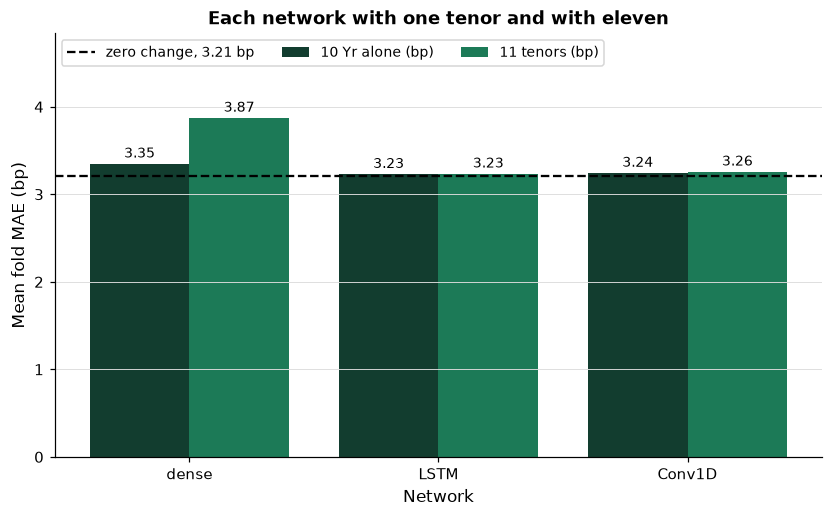

,10 Yr alone (bp),11 tenors (bp),"folds below zero change, 11 tenors"
Network,,,
dense,3.35,3.87,0
LSTM,3.23,3.23,1
Conv1D,3.24,3.26,0


In [40]:
# the walk-forward MAE of each network with one channel and with eleven, from the two sections' tables
kinds = [("dense", "dense_16_changes", "dense_16_11_tenors"), ("LSTM", "lstm_16", "lstm_16_11_tenors"),
         ("Conv1D", "conv1d_16", "conv1d_16_11_tenors")]
by_channels = pd.DataFrame({"10 Yr alone (bp)": [tables[a]["mae_bp"].mean() for _, a, _ in kinds],
                         "11 tenors (bp)": [tables[b]["mae_bp"].mean() for _, _, b in kinds],
                         "folds below zero change, 11 tenors": [int((tables[b]["mae_bp"].to_numpy() < zero.to_numpy()).sum()) for _, _, b in kinds]},
                        index=pd.Index([k for k, _, _ in kinds], name="Network"))
fig, ax = plt.subplots()
plotkit.bars(by_channels[["10 Yr alone (bp)", "11 tenors (bp)"]], "Each network with one tenor and with eleven", "Mean fold MAE (bp)", ax=ax, fmt="{:.2f}")
ax.axhline(zero.mean(), color="black", linestyle="--", label=f"zero change, {zero.mean():.2f} bp")
ax.set_ylim(0, by_channels[["10 Yr alone (bp)", "11 tenors (bp)"]].to_numpy().max() * 1.25)
ax.legend(loc="upper left", ncol=3, fontsize=9)
plt.show()
# the lower MAE of each column is marked: it ranks networks, not securities
plotkit.styled(by_channels, ["10 Yr alone (bp)", "11 tenors (bp)"], "Mean of the five walk-forward fold MAEs in bp, each network on the 10 Yr alone and on all 11 tenors, and the folds below zero change on 11",
               higher_is_better=False, fmt="{:.2f}")

* The dense network's pair is the one that moves: 3.35 bp on the 10 Yr alone and 3.87 on 11 tenors. The LSTM's and the Conv1D's pairs are nearly equal, and every bar stays above the dashed line, zero change's 3.21 bp. In Excel, a clustered column chart of the first two columns draws the bars.

## 13.6 Same-Day Changes Stay Out

Channels bring a new way to leak. The 10 Yr's change on a date is not in its own window, because `make_windows` stops the row before. But the curve moves together on a day: if a window ended on the target date, the 2 Yr's and 30 Yr's changes on that same date would sit in it, and they say a great deal about the 10 Yr's change that day. A model fitted on such windows looks excellent and could not have been used on the day, because those changes are only known once the day is over.

Q. How closely does the 10 Yr's change follow the 2 Yr's and the 30 Yr's on the same date, and on the date before?

In [41]:
for tenor in ("2 Yr", "30 Yr"):
    same_day = changes["10 Yr"].corr(changes[tenor])
    day_before = changes["10 Yr"].corr(changes[tenor].shift(1))
    print(f"10 Yr change against the {tenor} change: same date {same_day:.2f}, the {tenor} change one date earlier {day_before:.2f}")

10 Yr change against the 2 Yr change: same date 0.75, the 2 Yr change one date earlier 0.02
10 Yr change against the 30 Yr change: same date 0.93, the 30 Yr change one date earlier -0.03


* On the same date the correlation is 0.75 with the 2 Yr and 0.93 with the 30 Yr; a date earlier it is 0.02 and -0.03. The same-day changes carry most of the 10 Yr's move; the day before carries almost none. One row too many in a window is the difference.

Q. Add `assert_windows_past_only` to `netkit.py`, with its test.

In [42]:
%%writefile -a netkit.py


def assert_windows_past_only(input_end_dates, target_dates) -> None:
    """Stop unless every window ends strictly before the date it is scored on.

    Inputs: input_end_dates, the date of each window's last input row; target_dates, each window's target date, the
    same length.
    Output: None when every window's last input date is earlier than its target date.
    Convention: a window that ends on its target date holds that day's changes, for example another tenor's same-day
    change, and its fit looks far better than anything usable on the day.
    Raises AssertionError naming how many windows fail, and ValueError on lengths that differ or empty inputs.
    """
    ends, targets = pd.DatetimeIndex(input_end_dates), pd.DatetimeIndex(target_dates)
    if len(ends) == 0 or len(ends) != len(targets):
        raise ValueError(f"need the same number of end dates and target dates, not {len(ends)} and {len(targets)}")
    failing = int((ends >= targets).sum())
    if failing:
        raise AssertionError(f"{failing} of {len(ends)} windows end on or after the date they are scored on")

Appending to netkit.py


In [43]:
%%writefile -a test_netkit.py


def test_assert_windows_past_only_raises_on_same_day():
    dates = pd.bdate_range("2020-01-01", periods=10)
    netkit.assert_windows_past_only(dates[:-1], dates[1:])
    with pytest.raises(AssertionError, match="3 of 9"):
        ends = dates[:-1].tolist()
        ends[2], ends[5], ends[8] = dates[3], dates[6], dates[9]
        netkit.assert_windows_past_only(ends, dates[1:])

Appending to test_netkit.py


* It compares two lists of dates: the date of each window's last row, and the date the window is scored on. Every last row must be strictly earlier. It names how many windows fail, so a message tells you whether one window or all of them broke the rule.
* The test moves three windows' end dates onto their target dates and expects the message "3 of 9".

Q. Reload, and run every test.

In [44]:
importlib.reload(netkit)
print(f"assert_windows_past_only in netkit: {hasattr(netkit, 'assert_windows_past_only')}")

assert_windows_past_only in netkit: True


In [45]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_netkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

........................................................                 [100%]
56 passed in 13.57s



* `56 passed`: day 12's 53 and today's 3.

Q. Check today's windows: every one built by `make_windows` for the 1,980 target dates, and then windows that end on the target date.

In [46]:
positions = np.arange(window, len(changes))
target_dates = changes.index[positions]
# make_windows' window for position p is rows p - 20 to p - 1, so its last row is dated changes.index[p - 1]
netkit.assert_windows_past_only(changes.index[positions - 1], target_dates)
print(f"make_windows: all {len(positions):,} windows end before their target date")

# a window that ends on its target date: its last row would be dated changes.index[p]
try:
    netkit.assert_windows_past_only(changes.index[positions], target_dates)
except AssertionError as error:
    print(f"windows that end on the target date: AssertionError: {error}")

make_windows: all 1,980 windows end before their target date
windows that end on the target date: AssertionError: 1980 of 1980 windows end on or after the date they are scored on


* `make_windows` passes. Windows ending on the target date fail all 1,980: "1980 of 1980 windows end on or after the date they are scored on". The error is caught here by name so the notebook carries on; in your own code, let it stop you.
* Run the check on every set of windows you build, above all when you add channels: a window built by hand, with a slice one row too long, is how the same-day changes get in. The AI check at the end of the notebook is that mistake.

Q. Draw the same comparison for every other tenor: the 10 Yr's change against its change on the same date, and one date earlier.

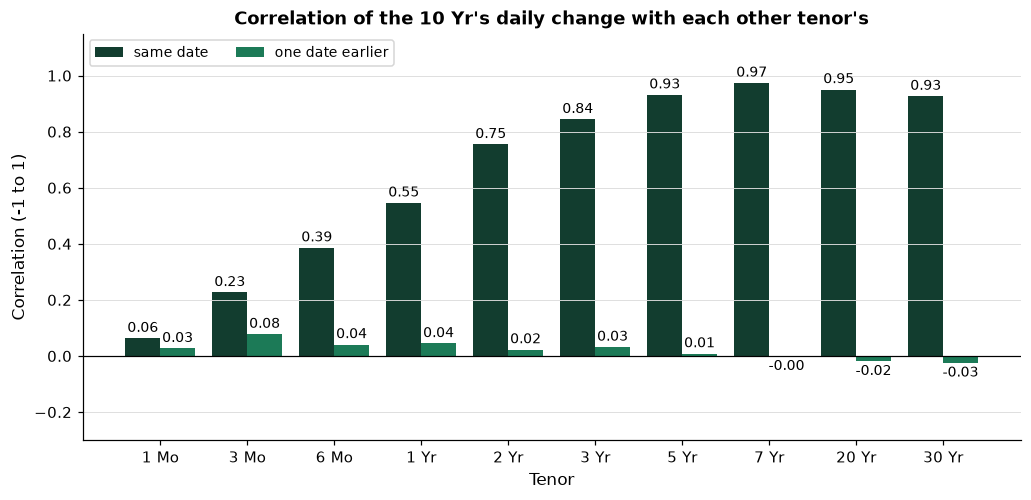

,same date,one date earlier
Tenor,,
1 Mo,0.06,0.03
3 Mo,0.23,0.08
6 Mo,0.39,0.04
1 Yr,0.55,0.04
2 Yr,0.75,0.02
3 Yr,0.84,0.03
5 Yr,0.93,0.01
7 Yr,0.97,-0.00
20 Yr,0.95,-0.02


In [47]:
# correlation of the 10 Yr's daily change with each other tenor's, on the same date and with that tenor one date earlier
others = [tenor for tenor in changes.columns if tenor != "10 Yr"]
correlations = pd.DataFrame({"same date": [changes["10 Yr"].corr(changes[t]) for t in others],
                             "one date earlier": [changes["10 Yr"].corr(changes[t].shift(1)) for t in others]},
                            index=pd.Index(others, name="Tenor"))
fig, ax = plt.subplots(figsize=(11, 4.8))
plotkit.bars(correlations, "Correlation of the 10 Yr's daily change with each other tenor's", "Correlation (-1 to 1)", ax=ax, fmt="{:.2f}")
ax.set_ylim(-0.3, 1.15)
ax.axhline(0, color="black", linewidth=0.8)
ax.legend(loc="upper left", ncol=2, fontsize=9)
plt.show()
# the rows are tenors, so no cell is marked
plotkit.styled(correlations, [], "Correlation of the 10 Yr's daily change in bp with each other tenor's change, on the same date and one date earlier, development years", fmt="{:.2f}")

* Same date: the correlations run from 0.06 with the 1 Mo to 0.97 with the 7 Yr, and the 2 Yr's and 30 Yr's are the two the text used above. One date earlier: none is larger than 0.08 in size, near the zero line. A window that held the target date's own row would hand the network the tall bars; a window that stops the row before hands it the flat ones. In Excel, `CORREL` of two columns, one shifted a row, gives each bar.

## 13.7 Every Sequence Model So Far

Eight networks and two simple rules have now been scored on the same five folds of the development years. One table holds them all.

Q. Put every model in one table: its channels, its weights and biases, its mean walk-forward MAE, its distance from zero change, and the folds where it was below zero change.

In [48]:
builds = {**earlier, "conv1d_16": conv_window, **many}
# the two rules have no weights; a rule is below zero change on a fold only if its MAE is smaller there
rows = [{"model": "zero_change", "channels": 1, "parameters": 0, "mae_bp": zero.mean(), "folds_below": 0},
        {"model": "training_mean", "channels": 1, "parameters": 0, "mae_bp": train_mean.mean(),
          "folds_below": int((train_mean.to_numpy() < zero.to_numpy()).sum())}]
for name, table in tables.items():
    channels = 11 if name.endswith("11_tenors") else 1
    rows.append({"model": name, "channels": channels, "parameters": builds[name](20, channels).count_params(),
                 "mae_bp": table["mae_bp"].mean(),
                 "folds_below": int((table["mae_bp"].to_numpy() < zero.to_numpy()).sum())})
every = pd.DataFrame(rows).set_index("model")
every["minus_zero_change_bp"] = every["mae_bp"] - zero.mean()
# the lowest MAE in each metric column is marked: the zero-change rule, which every network is measured against
plotkit.styled(every[["channels", "parameters", "mae_bp", "minus_zero_change_bp", "folds_below"]], ["mae_bp", "minus_zero_change_bp"],
               "Every sequence model and rule: channels, weights and biases, mean walk-forward MAE in bp, its distance from zero change, and the folds below zero change",
               higher_is_better=False, fmt="{:.2f}")

,channels,parameters,mae_bp,minus_zero_change_bp,folds_below
model,,,,,
zero_change,1,0,3.21,0.00,0
training_mean,1,0,3.22,0.01,0
dense_16_changes,1,353,3.35,0.14,0
simple_rnn_16,1,305,3.31,0.10,0
lstm_16,1,"1,169",3.23,0.02,0
gru_16,1,929,3.22,0.01,1
conv1d_16,1,113,3.24,0.03,0
dense_16_11_tenors,11,"3,553",3.87,0.66,0
lstm_16_11_tenors,11,"1,809",3.23,0.02,1


* Zero change is the lowest line in the table. Every network is between 0.01 and 0.66 bp behind it on average, and only 2 of the 8 networks are below it on any fold at all.
* More weights did not help: the dense network on 11 tenors, the largest by far (3,553 weights and biases), is the worst, and day 11's dense network is next. The LSTMs, the GRU, and the two convolutions sit within 0.03 bp of each other, close to the training mean (3.22 bp), which is where a network ends when it finds nothing to fit.

Q. Chart each network's MAE minus zero change's, fold by fold.

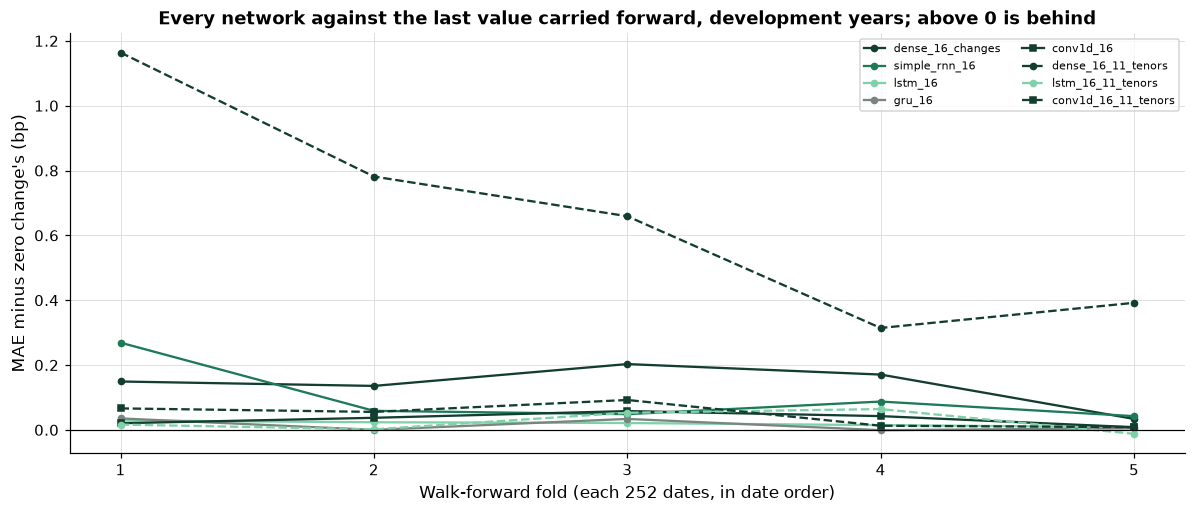

In [49]:
fig, ax = plt.subplots(figsize=(11, 4.8))
folds = range(1, len(zero) + 1)
# one colour per kind of network; the 11-tenor versions are dashed and the convolutions get square markers
colours = {"dense": plotkit.GREEN_DARK, "simple_rnn": plotkit.GREEN, "lstm": plotkit.GREEN_LIGHT, "gru": plotkit.GREY,
           "conv1d": plotkit.GREEN_DARK}
for name, table in tables.items():
    kind = name.split("_16")[0]
    ax.plot(folds, table["mae_bp"].to_numpy() - zero.to_numpy(), "--" if name.endswith("11_tenors") else "-", color=colours[kind],
            marker="s" if kind == "conv1d" else "o", markersize=4, label=name)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(list(folds))
ax.set_xlabel("Walk-forward fold (each 252 dates, in date order)")
ax.set_ylabel("MAE minus zero change's (bp)")
ax.set_title("Every network against the last value carried forward, development years; above 0 is behind")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

* Almost every point is above the zero line, in every fold. The dense network on 11 tenors is far above it throughout; the others crowd just above it. The lowest point in the chart is 0.01 bp below zero change, a fraction of a fold's error of about 3.21 bp.

Q. Draw each network's mean gap to zero change as bars, longest first.

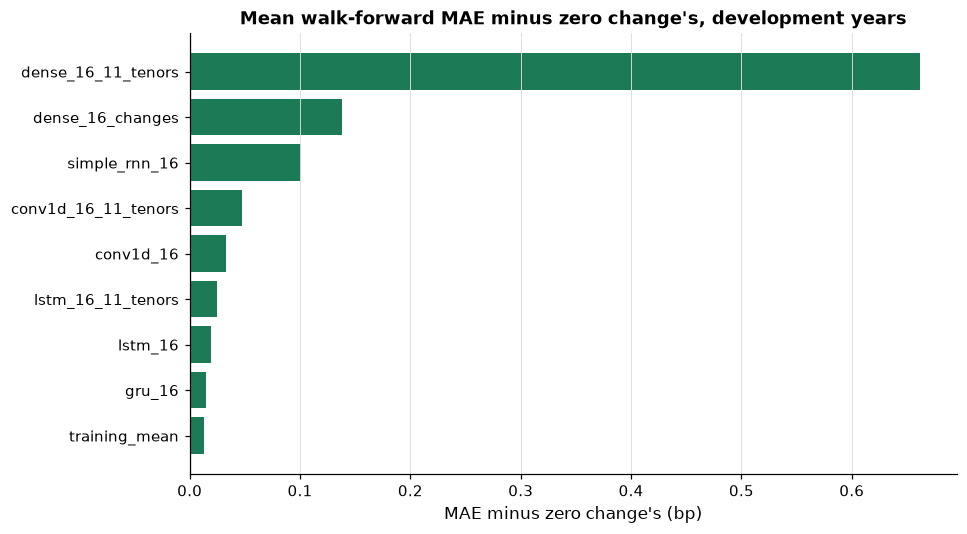

In [50]:
# the mean MAE of each network minus zero change's, the two rules included; longest bar first
gap = (every["mae_bp"] - zero.mean()).drop(index="zero_change")
fig, ax = plt.subplots(figsize=(9, 5.2))
plotkit.importance_bars(gap.index.tolist(), gap.to_numpy(), "Mean walk-forward MAE minus zero change's, development years",
                        ax=ax, xlabel="MAE minus zero change's (bp)")
plt.show()

* The longest bars are the dense networks, the one on 11 tenors longest; the LSTMs, the GRU, and the convolutions are short bars close together, near the training mean's. Every bar is on the same side of zero. In Excel, a bar chart of the table's `minus_zero_change_bp` column, sorted, draws it.

## 13.8 The Choice for Day 14

Day 14 opens the held-out years once, for networks chosen on the development years. The rule: the two networks with the lowest mean walk-forward MAE over the five development folds, on either kind of input, go to day 14 as candidates, with zero change and the training mean beside them. Day 14 chooses between the two by the same measure before it reads a held-out date.

> **Candidates for day 14: `gru_16` and `lstm_16`, both on the 10 Yr alone, with zero change and the training mean beside them.** `gru_16` has the lowest mean MAE of every network (3.22 bp), less than 0.01 bp ahead of `lstm_16` (3.23 bp). Next comes `lstm_16_11_tenors` (3.23 bp), the lowest on 11 tenors: every network on 11 tenors is above the same network on the 10 Yr alone, so the 11-tenor inputs are not carried forward. Neither candidate is below zero change on average (3.21 bp): `gru_16` is 0.01 bp behind and below it on 1 of 5 folds, `lstm_16` below it on 0 of 5. Naming them says which networks day 14 opens the held-out years with, not that they are good: the gap between them is less than 0.01 bp, and how far another seed moves these numbers has not been measured yet; day 14 measures it. Everything was chosen on the 2,001 development dates; no held-out date has been fitted or scored.

## Excel Side by Side

Excel has no convolution layer and no network training, and no walk-forward routine. What it has is `SUMPRODUCT`, and a filter is a `SUMPRODUCT` filled down. Every formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-06) on the notebook's first window: the dates in column A and the 10 Yr changes in bp in B2:B21 of a sheet named `one`, filter 1's five weights (from the Keras layer of section 13.1) in K2:K6 and its bias in K7, and five weights of 0.2 in M2:M6; on a sheet named `many`, all 11 tenors' changes in B2:L21 and the 11-tenor layer's filter 1 in N2:X6 with its bias in N7.

| Job | Python | Excel | Excel returned |
| --- | --- | --- | --- |
| A 5-day moving average | `conv1d_by_hand` with five weights of 0.2 | `=SUMPRODUCT(B2:B6,$M$2:$M$6)` in E2, filled down; beside it `=AVERAGE(B2:B6)` | first value -2.8, both columns equal |
| One filter on one tenor | `netkit.conv1d_by_hand(window_one, kernel_one, bias_one)[:, 0]` | `=SUMPRODUCT(B2:B6,$K$2:$K$6)+$K$7` in C2, filled down to C17 | first value 5.6165 |
| ReLU | `np.maximum(hand_one, 0)` | `=MAX(0,C2)` in D2, filled down | 7 of 16 set to 0 |
| Average pooling | `GlobalAveragePooling1D` | `=AVERAGE(D2:D17)` | 2.8086 |
| Max pooling | `GlobalMaxPooling1D` | `=MAX(D2:D17)` | 9.5347 |
| One filter on 11 tenors | `netkit.conv1d_by_hand(window_many, kernel_many, bias_many)[:, 0]` | `=SUMPRODUCT(B2:L6,$N$2:$X$6)+$N$7` in M2, filled down to M17 | first value 5.9707 |

**A filter is a fill-down.** Put the five weights in K2:K6 and the bias in K7. In C2, `=SUMPRODUCT(B2:B6,$K$2:$K$6)+$K$7` multiplies the first five days by the five weights and adds the bias. Fill it down: the `B2:B6` part slides one row at a time, B3:B7, B4:B8, while the dollar signs hold the weights still. That sliding block with fixed weights is exactly the convolution. It stops at C17, the last row where five days fit: 16 outputs.

**Equal weights are `AVERAGE`.** With five weights of 0.2, the same fill-down equals `=AVERAGE(B2:B6)` filled down, the 5-day moving average every desk has built.

**ReLU and pooling.** `=MAX(0,C2)` filled down is ReLU. `AVERAGE` and `MAX` of that column are the two pooling layers.

**Eleven tenors are a rectangle.** On the `many` sheet the weights are a block of 5 rows by 11 columns, N2:X6, and `=SUMPRODUCT(B2:L6,$N$2:$X$6)+$N$7` multiplies a 5-day by 11-tenor block of changes cell by cell by the weights. Filled down, `B2:L6` slides a day at a time.

What Excel cannot do is fit the weights: the numbers in K2:K6 came from Keras. And it has no walk-forward routine to fit a fresh network for each fold.

Q. Do Excel's numbers equal Python's?

In [51]:
# Excel's numbers, from the course's Excel check, beside netkit's and Keras's for the same window and weights
excel = {"filter 1, one tenor": [5.616539627313598, -1.334489494562141, -5.62965258955955, 6.28450760245321, 2.662360906600972, -8.747094392776496, 4.717495828866953, -0.708043068647378, -4.793618023395532, 8.248560220003114, -7.400554388761518, 1.2179767489433395, 9.534684389829629, -10.437370628118517, 6.538325458765035, 0.11781337857246399],
         "ReLU of filter 1": [5.616539627313598, 0.0, 0.0, 6.28450760245321, 2.662360906600972, 0.0, 4.717495828866953, 0.0, 0.0, 8.248560220003114, 0.0, 1.2179767489433395, 9.534684389829629, 0.0, 6.538325458765035, 0.11781337857246399],
         "average pooling": [2.8086415100842697],
         "max pooling": [9.534684389829629],
         "filter 1, 11 tenors": [5.970661625266063, 6.534365937113776, -3.2841622829437447, -4.19058559834955, 4.649065315723422, -10.225800991058364, -4.880552724003777, -3.3857639729976743, 7.701880455017117, 7.723328024148916, -3.6418602019548385, -3.352359831333151, 6.005534738302235, -5.164718717336662, 0.7305803745985087, -3.730304747819903]}
netkit_values = {"filter 1, one tenor": hand_one[:, 0], "ReLU of filter 1": relu_hand[:, 0],
                 "average pooling": [relu_hand[:, 0].mean()], "max pooling": [relu_hand[:, 0].max()],
                 "filter 1, 11 tenors": hand_many[:, 0]}
keras_values = {"filter 1, one tenor": keras_one[:, 0], "ReLU of filter 1": np.asarray(relu_keras)[0, :, 0],
                "average pooling": [average_keras[0]], "max pooling": [max_keras[0]],
                "filter 1, 11 tenors": keras_many[:, 0]}
rows = []
for job, values in excel.items():
    values = np.array(values)
    rows.append({"job": job, "values": len(values), "Excel, first": values[0],
                 "within 1e-12 of netkit": np.abs(values - np.array(netkit_values[job])).max() < 1e-12,
                 "within 1e-5 of Keras": np.abs(values - np.array(keras_values[job])).max() < 1e-5})
# every row is a value, not a model, so no cell is marked
display(plotkit.styled(pd.DataFrame(rows).set_index("job"), [], "Excel's values beside netkit's and Keras's for the same window and weights: how many values, Excel's first, and whether they agree", fmt="{:.4f}"))

excel_moving = [-2.8000000000000025, -2.400000000000002, -1.200000000000001, -1.9999999999999973, -5.199999999999996, -2.9999999999999982, -1.9999999999999973, -0.7999999999999963, 0.7999999999999963, 0.8000000000000007, 0.0, 0.20000000000000018, -2.8000000000000025, -2.599999999999998, -2.6000000000000023, -3.0000000000000027]
excel_average = [-2.8000000000000025, -2.400000000000002, -1.200000000000001, -1.9999999999999971, -5.199999999999996, -2.9999999999999982, -1.9999999999999971, -0.7999999999999963, 0.7999999999999965, 0.8000000000000007, 0.0, 0.20000000000000018, -2.8000000000000025, -2.599999999999998, -2.6000000000000023, -3.0000000000000027]
print(f"SUMPRODUCT with weights of 0.2 equal to AVERAGE, conv1d_by_hand, and pandas' rolling mean within 1e-12: "
      f"{np.abs(np.array(excel_moving) - moving[:, 0]).max() < 1e-12 and np.abs(np.array(excel_average) - rolling).max() < 1e-12}")

,values,"Excel, first",within 1e-12 of netkit,within 1e-5 of Keras
job,,,,
"filter 1, one tenor",16,5.6165,True,True
ReLU of filter 1,16,5.6165,True,True
average pooling,1,2.8086,True,True
max pooling,1,9.5347,True,True
"filter 1, 11 tenors",16,5.9707,True,True


SUMPRODUCT with weights of 0.2 equal to AVERAGE, conv1d_by_hand, and pandas' rolling mean within 1e-12: True


* Every Excel value equals netkit's within 1e-12, all 16 outputs of each filter: Excel and numpy both work in double precision on the same numbers. Against Keras the match is within 1e-5, Keras's float32 on changes of several bp, as in section 13.1.

## Save the Day with Git

The morning's commit holds the files as day 12 left them. Commit today's change on top, then the sequence log, then read the history.

Q. Commit today's two functions and their tests.

In [52]:
# M marks a tracked file that changed since the last commit
!git -C "{work}" status --short
!git -C "{work}" add netkit.py test_netkit.py
!git -C "{work}" commit -q -m "Day 13: conv1d_by_hand and assert_windows_past_only, 56 tests"

 M netkit.py
 M test_netkit.py
?? plotkit.py
?? treasury_par_yields.csv


Q. Write the sequence log as days 11 and 12 left it, from the networks rebuilt in section 13.4, and commit it.

In [53]:
def log_rows(names):
    """One row per model of the sequence log, with day 11's columns, from this notebook's tables."""
    out = []
    for name in names:
        scores = {"zero_change": zero, "training_mean": train_mean}.get(name)
        scores = tables[name]["mae_bp"] if scores is None else scores
        out.append({"model": name, "channels": 11 if name.endswith("11_tenors") else 1, "window": window,
                    "rows": "development", "folds": len(zero), "mae_bp": scores.mean(),
                    "zero_change_mae_bp": zero.mean(),
                    "folds_below_zero_change": int((scores.to_numpy() < zero.to_numpy()).sum())})
    return out


log = pd.DataFrame(log_rows(["zero_change", "training_mean", "dense_16_changes", "simple_rnn_16", "lstm_16", "gru_16"]))
# 4 decimals and LF line endings, so a later diff shows a real change and prints the same everywhere
log.to_csv("results.csv", index=False, float_format="%.4f", lineterminator="\n")
print((work / "results.csv").read_text(encoding="utf-8"))

model,channels,window,rows,folds,mae_bp,zero_change_mae_bp,folds_below_zero_change
zero_change,1,20,development,5,3.2087,3.2087,0
training_mean,1,20,development,5,3.2216,3.2087,0
dense_16_changes,1,20,development,5,3.3472,3.2087,0
simple_rnn_16,1,20,development,5,3.3099,3.2087,0
lstm_16,1,20,development,5,3.2281,3.2087,0
gru_16,1,20,development,5,3.2234,3.2087,1



* Day 11's columns: `model, channels, window, rows, folds, mae_bp, zero_change_mae_bp, folds_below_zero_change`. Day 11's log also had a row for its dense network on levels; it is not rebuilt here, because nothing today uses levels and it needs a run of its own. Your own log from day 11 keeps it.

In [54]:
!git -C "{work}" add results.csv
!git -C "{work}" commit -q -m "Sequence log as days 11 and 12 left it, rebuilt on the same folds (levels row not rebuilt)"

Q. Add today's four networks to the log, and commit.

In [55]:
log = pd.DataFrame(log_rows(["zero_change", "training_mean", "dense_16_changes", "simple_rnn_16", "lstm_16", "gru_16",
                             "conv1d_16", "dense_16_11_tenors", "lstm_16_11_tenors", "conv1d_16_11_tenors"]))
log.to_csv("results.csv", index=False, float_format="%.4f", lineterminator="\n")
print((work / "results.csv").read_text(encoding="utf-8"))

model,channels,window,rows,folds,mae_bp,zero_change_mae_bp,folds_below_zero_change
zero_change,1,20,development,5,3.2087,3.2087,0
training_mean,1,20,development,5,3.2216,3.2087,0
dense_16_changes,1,20,development,5,3.3472,3.2087,0
simple_rnn_16,1,20,development,5,3.3099,3.2087,0
lstm_16,1,20,development,5,3.2281,3.2087,0
gru_16,1,20,development,5,3.2234,3.2087,1
conv1d_16,1,20,development,5,3.2420,3.2087,0
dense_16_11_tenors,11,20,development,5,3.8709,3.2087,0
lstm_16_11_tenors,11,20,development,5,3.2333,3.2087,1
conv1d_16_11_tenors,11,20,development,5,3.2558,3.2087,0



In [56]:
!git -C "{work}" add results.csv
!git -C "{work}" commit -q -m "Sequence log: Conv1D on the 10 Yr, and dense, LSTM, Conv1D on 11 tenors, development years"

Q. Today's Git step: the history, one line per commit, with the labels Git keeps.

In [57]:
# --decorate adds the labels that point at a commit: HEAD and the branch, and any tag
!git -C "{work}" log --oneline --decorate

04e577a (HEAD -> main) Sequence log: Conv1D on the 10 Yr, and dense, LSTM, Conv1D on 11 tenors, development years
fee2370 Sequence log as days 11 and 12 left it, rebuilt on the same folds (levels row not rebuilt)
57ad078 Day 13: conv1d_by_hand and assert_windows_past_only, 56 tests
4c468ef Start of day 13: netkit as day 12 left it


* Four commits, newest first: the log with today's rows, the log as days 11 and 12 left it, today's code, the start of the day. `--decorate` prints `(HEAD -> ...)` beside the newest: `HEAD` is the commit you are on, and the name after the arrow is the branch it belongs to. Day 14 adds a tag, and `--decorate` shows tags the same way.

## Bring It Home

Add today's functions to your own `my_bondmath` folder. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and activate the course's environment.

```powershell
Set-Location "$HOME\projects\python-fixed-income"
.\.venv\Scripts\Activate.ps1
Set-Location "$HOME\projects\my_bondmath"
```

**Step 2.** Open `netkit.py` and paste the code of today's two `%%writefile -a netkit.py` cells (sections 13.1 and 13.6), without their first lines, at the end. Do the same for the two `%%writefile -a test_netkit.py` cells in `test_netkit.py`. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_netkit.py
```

The last line says `56 passed`.

**Step 4.** Commit, and read the history with its labels.

```powershell
git add netkit.py test_netkit.py
git commit -m "Day 13: conv1d_by_hand and assert_windows_past_only, 56 tests"
git log --oneline --decorate -5
```

`-5` keeps the history to the last five commits; in your own folder, where every day was its own commit, the list is long.

## You Can Now

* Compute a one-dimensional convolution by hand with `conv1d_by_hand`, and check it against Keras's `Conv1D`.
* Say why a filter of equal weights is a moving average, and write a filter in Excel as `SUMPRODUCT` filled down.
* Pool a filter's outputs with `GlobalAveragePooling1D` or `GlobalMaxPooling1D`, and with `AVERAGE` and `MAX`.
* Score a Conv1D walk-forward against the last value carried forward, on the same folds as every earlier network.
* Give a network many tenors as channels, and say why a dense network suffers from it more than a convolution.
* Keep same-day changes out of a window, and prove it with `assert_windows_past_only`.
* Choose models on the development years only, by a stated rule, and write the choice down.

Next, day 14: the case study. The two candidates named today meet the held-out years once, beside zero change and the training mean.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

The exercises use the development years of the Treasury file only, walk-forward, on section 13.4's five folds; nothing after 2022-12-30 is read. Every answer describes these past dates. Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the changes as in section 13.1, sets up the folds and zero change's MAE on each, defines section 13.3's `conv_window` and day 11's `dense_window`, a function that fits fold 1 by hand with any window builder (`fold_one_mae`, used in the AI check), and `check`, which marks your answers.

In [58]:
from sklearn.preprocessing import StandardScaler

# the development years' daily changes in bp of the 11 full tenors, as in section 13.1
treasury = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"]).set_index("date")
TENORS = ['1 Mo', '3 Mo', '6 Mo', '1 Yr', '2 Yr', '3 Yr', '5 Yr', '7 Yr', '10 Yr', '20 Yr', '30 Yr']
changes = (treasury.loc[:"2022-12-30", TENORS].diff() * 100).iloc[1:]
del treasury  # nothing below can read a held-out row
window = 20
positions = np.arange(window, len(changes))
splits = mlkit.walk_forward_splits(changes.index[positions], min_train=504, test_size=252)
# zero change on each fold: the mean absolute 10 Yr change on its test dates
zero = pd.Series([np.abs(changes["10 Yr"].to_numpy()[positions[test]]).mean() for _, test in splits])


# seed before building any Keras model, so its numbers never depend on what ran before
def conv_window(window, channels, width=5):
    """A one-dimensional convolution on a window: 16 filters of `width` days with ReLU, the average of each
    filter's outputs over the window, and one linear output."""
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(window, channels)),
                              keras.layers.Conv1D(16, width, activation="relu", name="conv"),
                              keras.layers.GlobalAveragePooling1D(name="pool"),
                              keras.layers.Dense(1, name="output")], name="conv_window")
    # mean squared error on the standardized change, Adam at Keras's default learning rate
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
    return model


def dense_window(window, channels):
    """Day 11's network: a dense network on a flattened window, window x channels inputs, 16 ReLU units, one
    linear output."""
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(window, channels)), keras.layers.Flatten(name="flatten"),
                              keras.layers.Dense(16, activation="relu", name="hidden"),
                              keras.layers.Dense(1, name="output")], name="dense_window")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
    return model


def fold_one_mae(windows):
    """Fold 1 of the walk-forward on the 11 tenors, by hand, with the input windows built by `windows` (it returns
    inputs first) and section 13.5's dense network: (the network's MAE, zero change's MAE), in bp."""
    train_positions, test_positions = positions[splits[0][0]], positions[splits[0][1]]
    # the scaler sees only the rows inside the training windows; the frame keeps the dates
    _, _, scaled = netkit.fit_arrays(StandardScaler(), changes.iloc[train_positions[0] - 20:train_positions[-1]],
                                     changes)
    scaled = pd.DataFrame(scaled, index=changes.index, columns=changes.columns)
    X_fold = windows(scaled, "10 Yr", 20, train_positions)[0]
    X_next = windows(scaled, "10 Yr", 20, test_positions)[0]
    # the targets in bp, standardized with the training dates' mean and spread
    y_fold = changes["10 Yr"].to_numpy()[train_positions]
    y_next = changes["10 Yr"].to_numpy()[test_positions]
    centre, spread = y_fold.mean(), y_fold.std()
    standard = ((y_fold - centre) / spread).astype("float32")
    # the last fifth of the training windows, in date order, to stop on
    n_stop = len(train_positions) // 5
    model = dense_window(20, len(TENORS))
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    model.fit(X_fold[:-n_stop].astype("float32"), standard[:-n_stop],
              validation_data=(X_fold[-n_stop:].astype("float32"), standard[-n_stop:]),
              epochs=50, batch_size=32, callbacks=[stop], verbose=0)
    fitted = model.predict(X_next.astype("float32"), verbose=0).ravel() * spread + centre
    return float(np.abs(y_next - fitted).mean()), float(np.abs(y_next).mean())


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

### Exercise 1

Q. Give the convolution filters 10 days wide instead of 5 (`conv_window(window, channels, width=10)`), and score it walk-forward on the 10 Yr changes with `netkit.walk_forward_network`, on the same folds (`window=20, min_train=504, test_size=252`). Store its mean MAE in bp, rounded to 2 decimals, in **ex1_mae**, and the number of folds where it is below zero change in **ex1_below**. Does a wider filter help?

In [59]:
ex1_mae = ...
ex1_below = ...

In [60]:
check("Exercise 1 mean MAE, filters 10 days wide", ex1_mae, 3.25)
check("Exercise 1 folds below zero change", ex1_below, 0)

Exercise 1 mean MAE, filters 10 days wide: not attempted yet
Exercise 1 folds below zero change: not attempted yet


### Exercise 2

Q. Give the convolution 5 tenors instead of 11: `['3 Mo', '2 Yr', '5 Yr', '10 Yr', '30 Yr']`. Score `conv_window` walk-forward with those five columns as `values` and the 10 Yr as the target, on the same folds. Store its mean MAE in bp, rounded to 2 decimals, in **ex2_mae**, and its folds below zero change in **ex2_below**. (A convolution on several tenors can differ in the last digits from run to run, which is why the answer is rounded.)

In [61]:
ex2_mae = ...
ex2_below = ...

In [62]:
check("Exercise 2 mean MAE, 5 tenors", ex2_mae, 3.24)
check("Exercise 2 folds below zero change", ex2_below, 0)

Exercise 2 mean MAE, 5 tenors: not attempted yet
Exercise 2 folds below zero change: not attempted yet


### Exercise 3

Q. Add a function to your module. `channel_names(tenors)` turns each tenor label into a channel name in snake case with its unit, in the window's order: `"2 Yr"` becomes `"change_2_yr_bp"`. It refuses an empty list or a tenor that appears twice with `ValueError`. Write the docstring first. Then add `test_channel_names_hand`, which checks two labels by hand and both refusals. Run pytest, reload the module, and store `netkit.channel_names(['3 Mo', '2 Yr', '5 Yr', '10 Yr', '30 Yr'])` in **ex3_names**.

Write the function in the cell that starts with `%%writefile -a netkit.py` and the test in the one that starts with `%%writefile -a test_netkit.py`, and run each of those cells once.

In [63]:
%%writefile -a netkit.py


# Exercise 3: write channel_names(tenors) below this line

Appending to netkit.py


In [64]:
%%writefile -a test_netkit.py


# Exercise 3: write test_channel_names_hand() below this line

Appending to test_netkit.py


In [65]:
# run pytest, reload the module, then run your function
ex3_names = ...

In [66]:
check("Exercise 3 channel names", ex3_names, ['change_3_mo_bp', 'change_2_yr_bp', 'change_5_yr_bp', 'change_10_yr_bp', 'change_30_yr_bp'])

Exercise 3 channel names: not attempted yet


### Exercise 4

Q. Work out the shape of a convolution before you build it. A `Conv1D` of 8 filters of width 7 with a stride of 3 and `valid` padding reads a 20-day window of all 11 tenors. Store the number of outputs per filter in **ex4_outputs** and the layer's weights and biases in **ex4_weights**. Use the formula from section 13.2, then build the layer and check it.

In [67]:
# the formula first, then the layer in Keras to check it
ex4_outputs = ...
ex4_weights = ...

In [68]:
check("Exercise 4 outputs per filter", ex4_outputs, 5)
check("Exercise 4 weights and biases", ex4_weights, 624)

Exercise 4 outputs per filter: not attempted yet
Exercise 4 weights and biases: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a function that builds windows of all 11 tenors' changes for a network, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
Windows of every tenor's daily changes, and the change each window is scored on.

    Inputs: frame, daily changes in bp, one column per tenor, indexed by date in order; target, the column
    scored (for example "10 Yr"); window, the trading days in each window; positions, the row positions of
    the target dates.
    Output: (inputs, targets, input_end_dates): inputs shaped (len(positions), window, tenors), each window
    the `window` trading days strictly before its target date, every tenor side by side; targets, the target
    column on each target date; input_end_dates, the date of each window's last row.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns arrays of the right shapes, and contains one bug.

In [69]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def curve_windows(frame, target, window, positions):
    """Windows of every tenor's daily changes, and the change each window is scored on.

    Inputs: frame, daily changes in bp, one column per tenor, indexed by date in order; target, the column
    scored (for example "10 Yr"); window, the trading days in each window; positions, the row positions of
    the target dates.
    Output: (inputs, targets, input_end_dates): inputs shaped (len(positions), window, tenors), each window
    the `window` trading days strictly before its target date, every tenor side by side; targets, the target
    column on each target date; input_end_dates, the date of each window's last row.
    """
    rows, places = frame.to_numpy(dtype=float), np.asarray(positions)
    # the window of rows up to each target date, every tenor side by side
    inputs = np.stack([rows[p - window + 1:p + 1] for p in places])
    return inputs, frame[target].to_numpy(dtype=float)[places], frame.index[places]

Q. Before you run the next cell: fold 1 is fitted with these windows and section 13.5's dense network on 11 tenors. That network scored 3.89 bp on fold 1 with `make_windows`, against zero change's 2.72 bp. What will it score with these windows?

In [70]:
ai_mae, ai_zero = fold_one_mae(curve_windows)
print(f"fold 1 with these windows: the network {ai_mae:.2f} bp, zero change {ai_zero:.2f} bp")

fold 1 with these windows: the network 2.09 bp, zero change 2.72 bp


Q. Test the function against its docstring before you trust it: every window must end strictly before its target date, and the windows must equal `make_windows`'.

In [71]:
# the test, written from the docstring before the code is trusted
ai_inputs, ai_targets, ai_ends = curve_windows(changes, "10 Yr", 20, positions)
target_dates = changes.index[positions]
# every window must end strictly before the date it is scored on
late = int((pd.DatetimeIndex(ai_ends) >= target_dates).sum())
assert late == 0, f"{late} of {len(positions)} windows end on or after the date they are scored on"
netkit.assert_windows_past_only(ai_ends, target_dates)
reference_inputs, _ = netkit.make_windows(changes, changes["10 Yr"], 20, positions)
assert np.array_equal(ai_inputs, reference_inputs), "the windows differ from make_windows'"
print(f"every window ends before its target date: {late == 0}; equal to make_windows: True")

AssertionError: 1980 of 1980 windows end on or after the date they are scored on

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then fit fold 1 with the fixed function, `fold_one_mae(curve_windows)[0]`, and store it rounded to 2 decimals in **ex5_fold_one**.

In [72]:
# fix the function above and run the test again, then store the answer
ex5_fold_one = ...

In [73]:
check("Exercise 5 fold 1 with the fixed windows", ex5_fold_one, 3.89)

Exercise 5 fold 1 with the fixed windows: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```